# Exact local-$a$ LTE interface-temperature contours

This notebook visualizes the latest two-block cluster scan using the exact local fraction $a(0^+)=n_K(0^+)/n_B(0^+)$.

The first contour shows $T(0^-)-T(0^+)$ and the second shows $T(0^+)$ directly. Points where the three jump equations have no physical root remain explicitly marked and retain $T(0^+)=\mathrm{NaN}$.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
DATA_PATH = (
    ROOT
    / "new_paper_calculations"
    / "26-07-23"
    / "lte-temperature-jump-two-block-linear.npy"
)
OUTPUT_DIR = ROOT / "local_analysis_results" / "26SU-9"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

payload = np.load(DATA_PATH, allow_pickle=True).item()

low_T = np.asarray(payload["low_temperature_grid"], dtype=float)
low_m = np.asarray(payload["low_metastability_grid"], dtype=float)
low_delta_T = np.asarray(payload["low_delta_T_interface_MeV_grid"], dtype=float)
low_T_Qstar = np.asarray(payload["low_T_Qstar_LTE_MeV_grid"], dtype=float)
low_beta = np.asarray(payload["low_beta_LTE_grid"], dtype=float)
low_lambda_n = np.asarray(payload["low_lambda_n_grid"], dtype=float)
low_u_N = np.asarray(payload["low_u_N_grid"], dtype=float)
low_status = np.asarray(payload["low_status_grid"], dtype=int)
low_jump_status = np.asarray(payload["low_lte_jump_closure_status_grid"], dtype=int)
low_isobar_status = np.asarray(payload["low_lte_isobar_closure_status_grid"], dtype=int)
low_A_exact_local = np.asarray(payload["low_A_boundary_exact_local_grid"], dtype=float)
low_isobar_pressure_residual = np.asarray(
    payload["low_lte_isobar_pressure_residual_norm_grid"], dtype=float
)
low_a_residual = np.asarray(payload["low_lte_jump_a_residual_grid"], dtype=float)
low_energy_residual = np.asarray(
    payload["low_lte_jump_energy_residual_norm_grid"], dtype=float
)
low_momentum_residual = np.asarray(
    payload["low_lte_jump_momentum_residual_norm_grid"], dtype=float
)

high_T = np.asarray(payload["high_temperature_grid"], dtype=float)
high_m = np.asarray(payload["high_metastability_grid"], dtype=float)
high_delta_T = np.asarray(payload["high_delta_T_interface_MeV_grid"], dtype=float)
high_T_Qstar = np.asarray(payload["high_T_Qstar_LTE_MeV_grid"], dtype=float)
high_beta = np.asarray(payload["high_beta_LTE_grid"], dtype=float)
high_lambda_n = np.asarray(payload["high_lambda_n_grid"], dtype=float)
high_u_N = np.asarray(payload["high_u_N_grid"], dtype=float)
high_status = np.asarray(payload["high_status_grid"], dtype=int)
high_jump_status = np.asarray(payload["high_lte_jump_closure_status_grid"], dtype=int)
high_isobar_status = np.asarray(payload["high_lte_isobar_closure_status_grid"], dtype=int)
high_A_exact_local = np.asarray(payload["high_A_boundary_exact_local_grid"], dtype=float)
high_isobar_pressure_residual = np.asarray(
    payload["high_lte_isobar_pressure_residual_norm_grid"], dtype=float
)
high_a_residual = np.asarray(payload["high_lte_jump_a_residual_grid"], dtype=float)
high_energy_residual = np.asarray(
    payload["high_lte_jump_energy_residual_norm_grid"], dtype=float
)
high_momentum_residual = np.asarray(
    payload["high_lte_jump_momentum_residual_norm_grid"], dtype=float
)

A_boundary_temperature_values = np.asarray(
    payload["A_boundary_temperature_values"], dtype=float
)
A_boundary_metastability_values = np.asarray(
    payload["A_boundary_metastability_values"], dtype=float
)
gap_boundary_temperature_values = np.asarray(
    payload["gap_boundary_temperature_values"], dtype=float
)
gap_boundary_metastability_values = np.asarray(
    payload["gap_boundary_metastability_values"], dtype=float
)

jump_codes = payload["lte_jump_closure_status_codes"]
JUMP_SOLVED = int(jump_codes["solved"])
JUMP_NOT_ATTEMPTED = int(jump_codes["not_attempted"])
JUMP_ROOT_FAILURE = int(jump_codes["root_failure"])
JUMP_POSTCHECK_FAILURE = int(jump_codes["postcheck_failure"])

isobar_codes = payload["lte_isobar_closure_status_codes"]
ISOBAR_SOLVED = int(isobar_codes["solved"])
ISOBAR_NOT_ATTEMPTED = int(isobar_codes["not_attempted"])
ISOBAR_ROOT_FAILURE = int(isobar_codes["root_failure"])
ISOBAR_POSTCHECK_FAILURE = int(isobar_codes["postcheck_failure"])

print(f"Loaded: {DATA_PATH}")
print(f"Run tag: {payload['run_tag']}")
print(f"Interface closure: {payload['T_Qstar_LTE_definition']}")

Loaded: /Users/janshao/NSM_related/new_paper_calculations/26-07-23/lte-temperature-jump-two-block-linear.npy
Run tag: lte_temperature_jump_two_block_linear_beta5_exact_local_a_v3
Interface closure: exact local-a interface solve of baryon, energy, and momentum jumps


## Cluster-result diagnostics

In [2]:
def finite_max_abs(values):
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    return float(np.max(np.abs(values[finite]))) if np.any(finite) else np.nan


for block_name, block_arrays in {
    "low": (
        low_T,
        low_m,
        low_delta_T,
        low_T_Qstar,
        low_beta,
        low_lambda_n,
        low_u_N,
        low_status,
        low_jump_status,
        low_isobar_status,
        low_A_exact_local,
    ),
    "high": (
        high_T,
        high_m,
        high_delta_T,
        high_T_Qstar,
        high_beta,
        high_lambda_n,
        high_u_N,
        high_status,
        high_jump_status,
        high_isobar_status,
        high_A_exact_local,
    ),
}.items():
    reference_shape = block_arrays[0].shape
    assert all(array.shape == reference_shape for array in block_arrays), block_name

assert np.all(np.diff(low_T[:, 0]) > 0.0)
assert np.all(np.diff(high_T[:, 0]) > 0.0)
assert np.all(np.diff(low_m[0, :]) > 0.0)
assert np.all(np.diff(high_m[0, :]) > 0.0)
assert np.all(low_isobar_status == ISOBAR_SOLVED)
assert np.all(high_isobar_status == ISOBAR_SOLVED)

for T_Qstar, delta_T, jump_status in (
    (low_T_Qstar, low_delta_T, low_jump_status),
    (high_T_Qstar, high_delta_T, high_jump_status),
):
    assert np.array_equal(np.isfinite(T_Qstar), jump_status == JUMP_SOLVED)
    assert np.array_equal(np.isfinite(delta_T), jump_status == JUMP_SOLVED)

seam_max_abs_MeV = max(
    finite_max_abs(low_delta_T[-1, :] - high_delta_T[0, :]),
    finite_max_abs(low_T_Qstar[-1, :] - high_T_Qstar[0, :]),
)
seam_beta_max_abs = finite_max_abs(low_beta[-1, :] - high_beta[0, :])
seam_A_exact_local_max_abs = finite_max_abs(
    low_A_exact_local[-1, :] - high_A_exact_local[0, :]
)
assert np.array_equal(low_jump_status[-1, :], high_jump_status[0, :])
assert np.array_equal(low_isobar_status[-1, :], high_isobar_status[0, :])

temperature_identity_max_abs_MeV = max(
    finite_max_abs(low_delta_T - (low_T - low_T_Qstar)),
    finite_max_abs(high_delta_T - (high_T - high_T_Qstar)),
)
beta_identity_max_abs = max(
    finite_max_abs(low_beta - 5.0 * low_lambda_n * low_u_N),
    finite_max_abs(high_beta - 5.0 * high_lambda_n * high_u_N),
)
composition_residual_max_abs = max(
    finite_max_abs(low_a_residual),
    finite_max_abs(high_a_residual),
)
energy_residual_max_abs = max(
    finite_max_abs(low_energy_residual),
    finite_max_abs(high_energy_residual),
)
momentum_residual_max_abs = max(
    finite_max_abs(low_momentum_residual),
    finite_max_abs(high_momentum_residual),
)
isobar_pressure_residual_max_abs = max(
    finite_max_abs(low_isobar_pressure_residual),
    finite_max_abs(high_isobar_pressure_residual),
)

assert seam_max_abs_MeV <= 1.0e-12
assert seam_beta_max_abs <= 1.0e-12
assert seam_A_exact_local_max_abs <= 1.0e-12
assert temperature_identity_max_abs_MeV <= 1.0e-12
assert beta_identity_max_abs <= 1.0e-12
assert composition_residual_max_abs <= 1.0e-7
assert energy_residual_max_abs <= 1.0e-7
assert momentum_residual_max_abs <= 1.0e-7
assert isobar_pressure_residual_max_abs <= 1.0e-9

summary_rows = []
for block_name, T_grid, delta_T, T_Qstar, status, jump_status, isobar_status in (
    ("low", low_T, low_delta_T, low_T_Qstar, low_status, low_jump_status, low_isobar_status),
    ("high", high_T, high_delta_T, high_T_Qstar, high_status, high_jump_status, high_isobar_status),
):
    summary_rows.append(
        {
            "block": block_name,
            "shape": T_grid.shape,
            "analytic_success_points": int(np.count_nonzero(status == 0)),
            "exact_isobar_roots": int(np.count_nonzero(isobar_status == ISOBAR_SOLVED)),
            "exact_jump_roots": int(np.count_nonzero(jump_status == JUMP_SOLVED)),
            "root_failure_points": int(np.count_nonzero(jump_status == JUMP_ROOT_FAILURE)),
            "postcheck_failure_points": int(
                np.count_nonzero(jump_status == JUMP_POSTCHECK_FAILURE)
            ),
            "not_attempted_points": int(
                np.count_nonzero(jump_status == JUMP_NOT_ATTEMPTED)
            ),
            "delta_T_min_MeV": float(np.nanmin(delta_T)),
            "delta_T_max_MeV": float(np.nanmax(delta_T)),
            "T_Qstar_min_MeV": float(np.nanmin(T_Qstar)),
            "T_Qstar_max_MeV": float(np.nanmax(T_Qstar)),
        }
    )

display(pd.DataFrame(summary_rows))
display(
    pd.DataFrame.from_dict(
        {
            "seam_max_abs_MeV": seam_max_abs_MeV,
            "seam_beta_max_abs": seam_beta_max_abs,
            "seam_A_exact_local_max_abs": seam_A_exact_local_max_abs,
            "temperature_identity_max_abs_MeV": temperature_identity_max_abs_MeV,
            "beta_identity_max_abs": beta_identity_max_abs,
            "composition_residual_max_abs": composition_residual_max_abs,
            "energy_residual_max_abs": energy_residual_max_abs,
            "momentum_residual_max_abs": momentum_residual_max_abs,
            "isobar_pressure_residual_max_abs": isobar_pressure_residual_max_abs,
            "jump_failure_policy": payload["jump_failure_policy"],
        },
        orient="index",
        columns=["value"],
    )
)

,block,shape,analytic_success_points,exact_isobar_roots,exact_jump_roots,root_failure_points,postcheck_failure_points,not_attempted_points,delta_T_min_MeV,delta_T_max_MeV,T_Qstar_min_MeV,T_Qstar_max_MeV
0,low,"(30, 20)",600,600,600,0,0,0,-13.755100,69.534897,0.000225,13.765100
1,high,"(12, 20)",240,240,201,39,0,0,67.690648,76.528905,10.465103,21.606441


,value
seam_max_abs_MeV,0.0
seam_beta_max_abs,0.0
seam_A_exact_local_max_abs,0.0
temperature_identity_max_abs_MeV,0.0
beta_identity_max_abs,0.0
composition_residual_max_abs,0.0
energy_residual_max_abs,0.0
momentum_residual_max_abs,0.0
isobar_pressure_residual_max_abs,0.0
jump_failure_policy,mark closure status and return NaN temperature


## Signed interface-temperature difference

Colored contour lines show $T(0^-)-T(0^+)$. Gray regions reproduce the two saved exclusion boundaries, and crosses mark mesh points where the exact jump solve has no physical root.

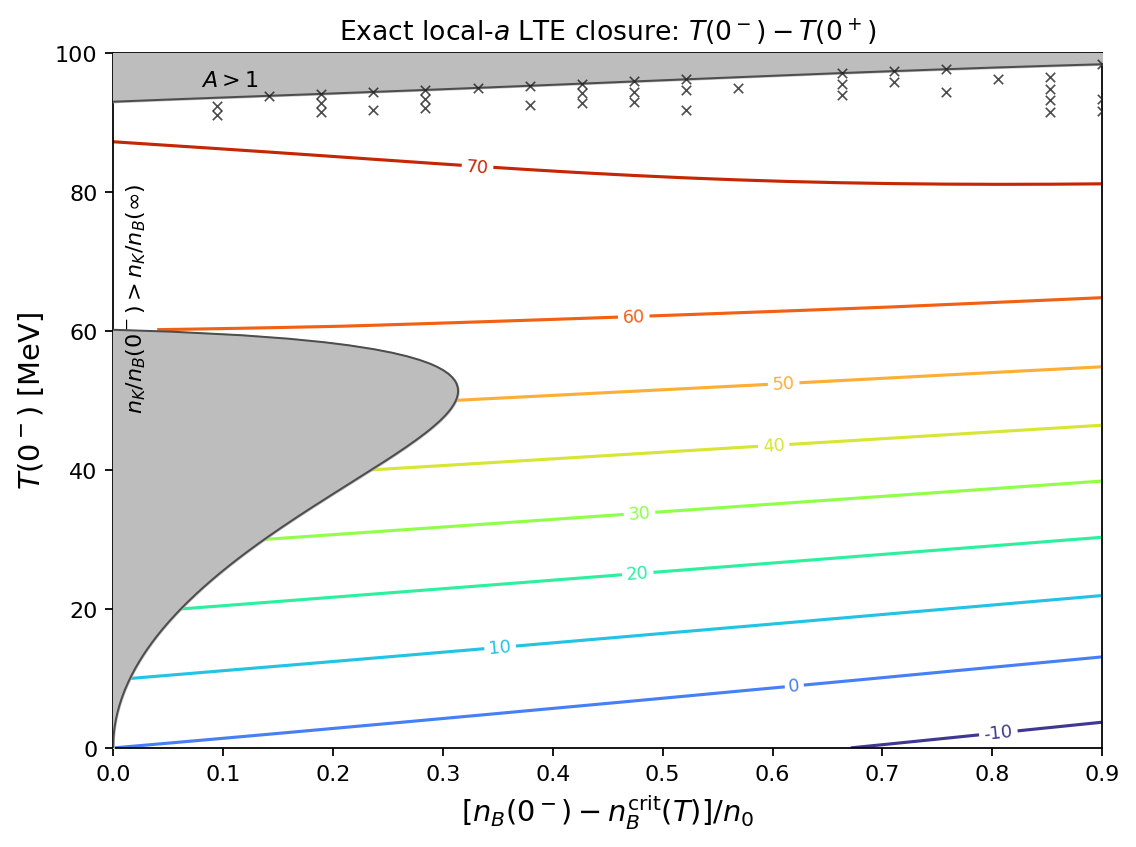

In [3]:
# Tunable plotting parameters
FIGURE_SIZE = (7.2, 5.4)
FIGURE_DPI = 160
TITLE_FONT_SIZE = 12
AXIS_LABEL_FONT_SIZE = 13
TICK_LABEL_FONT_SIZE = 10
CONTOUR_LEVELS_MEV = (-15.0, -10.0, 0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0)
CONTOUR_CMAP = "turbo"
CONTOUR_LINE_WIDTH = 1.4
CONTOUR_LABEL_FONT_SIZE = 8
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 3
GRAY_FILL_COLOR = "#bdbdbd"
GRAY_FILL_ALPHA = 1.0
BOUNDARY_LINE_COLOR = "#4d4d4d"
BOUNDARY_LINE_WIDTH = 0.9
ROOT_FAILURE_MARKER = "x"
ROOT_FAILURE_MARKER_SIZE = 18
ROOT_FAILURE_COLOR = "#202020"
ROOT_FAILURE_LINE_WIDTH = 0.75
ROOT_FAILURE_ALPHA = 0.8
X_LIMITS = (0.0, 0.9)
Y_LIMITS = (0.0, 100.0)
X_MAJOR_TICK = 0.1
Y_MAJOR_TICK = 20.0
TITLE_TEXT = r"Exact local-$a$ LTE closure: $T(0^-)-T(0^+)$"
X_LABEL_TEXT = r"$[n_B(0^-)-n_B^{\mathrm{crit}}(T)]/n_0$"
Y_LABEL_TEXT = r"$T(0^-)$ [MeV]"
A_REGION_LABEL = r"$A>1$"
GAP_REGION_LABEL = r"$n_K/n_B(0^-)>n_K/n_B(\infty)$"
A_REGION_LABEL_POSITION = (0.08, 95.2)
GAP_REGION_LABEL_POSITION = (0.01, 49.0)
REGION_LABEL_FONT_SIZE = 10
PLOT_ZORDER = 1
EXCLUSION_ZORDER = 3
BOUNDARY_ZORDER = 4
ROOT_FAILURE_ZORDER = 5
LAYOUT_TIGHT = True
EXPORT_PDF = OUTPUT_DIR / "lte-temperature-jump-contour-exact-local-a-v3.pdf"
EXPORT_PNG = OUTPUT_DIR / "lte-temperature-jump-contour-exact-local-a-v3.png"
EXPORT_DPI = 300
EXPORT_BBOX = "tight"

low_delta_field = np.ma.masked_invalid(low_delta_T)
high_delta_field = np.ma.masked_invalid(high_delta_T)
root_failure_mask = high_jump_status == JUMP_ROOT_FAILURE

A_boundary_order = np.argsort(A_boundary_metastability_values)
A_boundary_x = A_boundary_metastability_values[A_boundary_order]
A_boundary_y = A_boundary_temperature_values[A_boundary_order]
gap_boundary_order = np.argsort(gap_boundary_temperature_values)
gap_boundary_y = gap_boundary_temperature_values[gap_boundary_order]
gap_boundary_x = gap_boundary_metastability_values[gap_boundary_order]

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
low_lines = ax.contour(
    low_m,
    low_T,
    low_delta_field,
    levels=CONTOUR_LEVELS_MEV,
    cmap=CONTOUR_CMAP,
    linewidths=CONTOUR_LINE_WIDTH,
    zorder=PLOT_ZORDER,
)
high_lines = ax.contour(
    high_m,
    high_T,
    high_delta_field,
    levels=CONTOUR_LEVELS_MEV,
    cmap=CONTOUR_CMAP,
    linewidths=CONTOUR_LINE_WIDTH,
    zorder=PLOT_ZORDER,
)
ax.clabel(
    low_lines,
    inline=CONTOUR_LABEL_INLINE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    fmt=CONTOUR_LABEL_FORMAT,
)
ax.clabel(
    high_lines,
    inline=CONTOUR_LABEL_INLINE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    fmt=CONTOUR_LABEL_FORMAT,
)

ax.fill_between(
    A_boundary_x,
    A_boundary_y,
    Y_LIMITS[1],
    color=GRAY_FILL_COLOR,
    alpha=GRAY_FILL_ALPHA,
    zorder=EXCLUSION_ZORDER,
)
ax.plot(
    A_boundary_x,
    A_boundary_y,
    color=BOUNDARY_LINE_COLOR,
    linewidth=BOUNDARY_LINE_WIDTH,
    zorder=BOUNDARY_ZORDER,
)
ax.fill_betweenx(
    gap_boundary_y,
    X_LIMITS[0],
    gap_boundary_x,
    color=GRAY_FILL_COLOR,
    alpha=GRAY_FILL_ALPHA,
    zorder=EXCLUSION_ZORDER,
)
ax.plot(
    gap_boundary_x,
    gap_boundary_y,
    color=BOUNDARY_LINE_COLOR,
    linewidth=BOUNDARY_LINE_WIDTH,
    zorder=BOUNDARY_ZORDER,
)
ax.scatter(
    high_m[root_failure_mask],
    high_T[root_failure_mask],
    marker=ROOT_FAILURE_MARKER,
    s=ROOT_FAILURE_MARKER_SIZE,
    color=ROOT_FAILURE_COLOR,
    linewidths=ROOT_FAILURE_LINE_WIDTH,
    alpha=ROOT_FAILURE_ALPHA,
    zorder=ROOT_FAILURE_ZORDER,
)

ax.text(*A_REGION_LABEL_POSITION, A_REGION_LABEL, fontsize=REGION_LABEL_FONT_SIZE, zorder=ROOT_FAILURE_ZORDER)
ax.text(*GAP_REGION_LABEL_POSITION, GAP_REGION_LABEL, fontsize=REGION_LABEL_FONT_SIZE, rotation=90, zorder=ROOT_FAILURE_ZORDER)
ax.set_xlim(X_LIMITS)
ax.set_ylim(Y_LIMITS)
ax.set_xticks(np.arange(X_LIMITS[0], X_LIMITS[1] + 0.5 * X_MAJOR_TICK, X_MAJOR_TICK))
ax.set_yticks(np.arange(Y_LIMITS[0], Y_LIMITS[1] + 0.5 * Y_MAJOR_TICK, Y_MAJOR_TICK))
ax.tick_params(axis="both", labelsize=TICK_LABEL_FONT_SIZE)
ax.set_xlabel(X_LABEL_TEXT, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(Y_LABEL_TEXT, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_title(TITLE_TEXT, fontsize=TITLE_FONT_SIZE)
if LAYOUT_TIGHT:
    fig.tight_layout()
fig.savefig(EXPORT_PDF, bbox_inches=EXPORT_BBOX)
fig.savefig(EXPORT_PNG, dpi=EXPORT_DPI, bbox_inches=EXPORT_BBOX)
plt.show()

## Downstream interface temperature

This contour shows $T(0^+)$ itself, with no subtraction. The exclusions and failed-root markers use the same conventions as the signed-temperature plot.

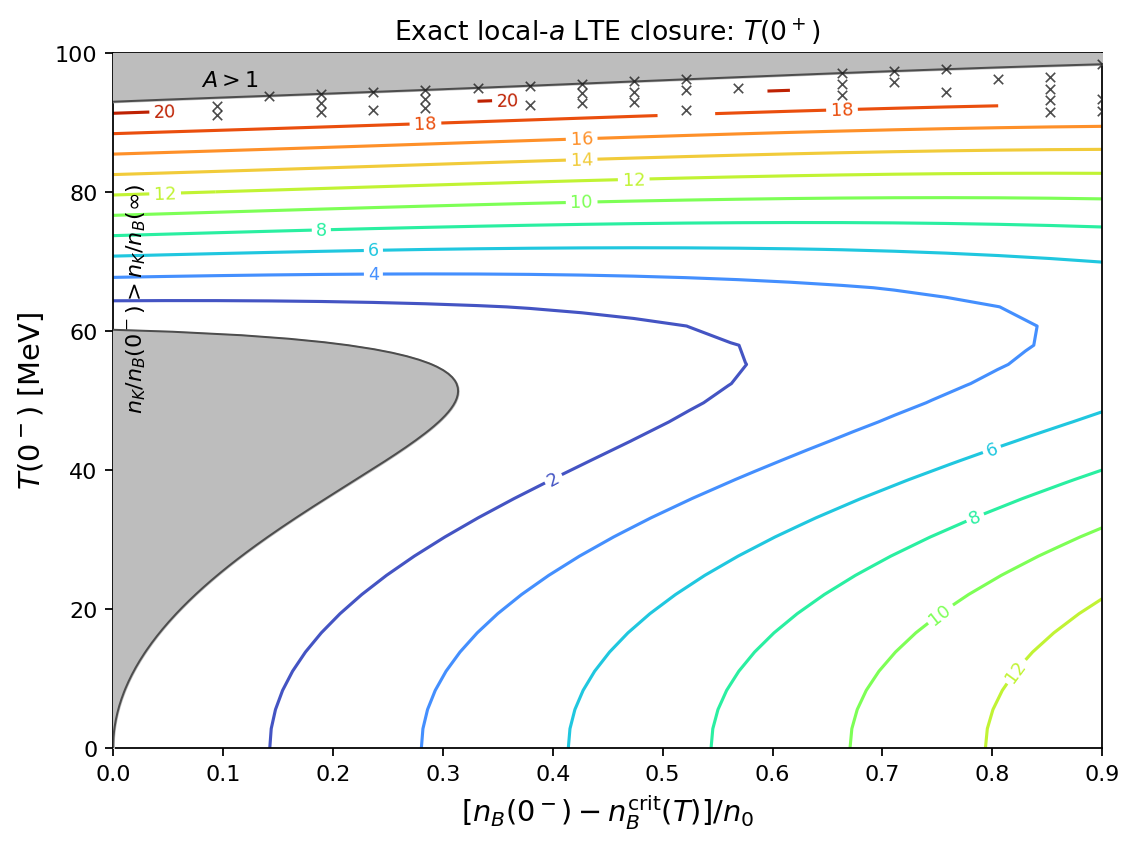

In [4]:
# Tunable plotting parameters
FIGURE_SIZE = (7.2, 5.4)
FIGURE_DPI = 160
TITLE_FONT_SIZE = 12
AXIS_LABEL_FONT_SIZE = 13
TICK_LABEL_FONT_SIZE = 10
CONTOUR_LEVELS_MEV = (0.0, 2.0, 4.0, 6.0, 8.0, 10.0, 12.0, 14.0, 16.0, 18.0, 20.0, 22.0)
CONTOUR_CMAP = "turbo"
CONTOUR_LINE_WIDTH = 1.4
CONTOUR_LABEL_FONT_SIZE = 8
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 3
GRAY_FILL_COLOR = "#bdbdbd"
GRAY_FILL_ALPHA = 1.0
BOUNDARY_LINE_COLOR = "#4d4d4d"
BOUNDARY_LINE_WIDTH = 0.9
ROOT_FAILURE_MARKER = "x"
ROOT_FAILURE_MARKER_SIZE = 18
ROOT_FAILURE_COLOR = "#202020"
ROOT_FAILURE_LINE_WIDTH = 0.75
ROOT_FAILURE_ALPHA = 0.8
X_LIMITS = (0.0, 0.9)
Y_LIMITS = (0.0, 100.0)
X_MAJOR_TICK = 0.1
Y_MAJOR_TICK = 20.0
TITLE_TEXT = r"Exact local-$a$ LTE closure: $T(0^+)$"
X_LABEL_TEXT = r"$[n_B(0^-)-n_B^{\mathrm{crit}}(T)]/n_0$"
Y_LABEL_TEXT = r"$T(0^-)$ [MeV]"
A_REGION_LABEL = r"$A>1$"
GAP_REGION_LABEL = r"$n_K/n_B(0^-)>n_K/n_B(\infty)$"
A_REGION_LABEL_POSITION = (0.08, 95.2)
GAP_REGION_LABEL_POSITION = (0.01, 49.0)
REGION_LABEL_FONT_SIZE = 10
PLOT_ZORDER = 1
EXCLUSION_ZORDER = 3
BOUNDARY_ZORDER = 4
ROOT_FAILURE_ZORDER = 5
LAYOUT_TIGHT = True
EXPORT_PDF = OUTPUT_DIR / "lte-interface-temperature-T-plus-contour-exact-local-a-v3.pdf"
EXPORT_PNG = OUTPUT_DIR / "lte-interface-temperature-T-plus-contour-exact-local-a-v3.png"
EXPORT_DPI = 300
EXPORT_BBOX = "tight"

low_T_Qstar_field = np.ma.masked_invalid(low_T_Qstar)
high_T_Qstar_field = np.ma.masked_invalid(high_T_Qstar)
root_failure_mask = high_jump_status == JUMP_ROOT_FAILURE

A_boundary_order = np.argsort(A_boundary_metastability_values)
A_boundary_x = A_boundary_metastability_values[A_boundary_order]
A_boundary_y = A_boundary_temperature_values[A_boundary_order]
gap_boundary_order = np.argsort(gap_boundary_temperature_values)
gap_boundary_y = gap_boundary_temperature_values[gap_boundary_order]
gap_boundary_x = gap_boundary_metastability_values[gap_boundary_order]

fig, ax = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI)
low_lines = ax.contour(
    low_m,
    low_T,
    low_T_Qstar_field,
    levels=CONTOUR_LEVELS_MEV,
    cmap=CONTOUR_CMAP,
    linewidths=CONTOUR_LINE_WIDTH,
    zorder=PLOT_ZORDER,
)
high_lines = ax.contour(
    high_m,
    high_T,
    high_T_Qstar_field,
    levels=CONTOUR_LEVELS_MEV,
    cmap=CONTOUR_CMAP,
    linewidths=CONTOUR_LINE_WIDTH,
    zorder=PLOT_ZORDER,
)
ax.clabel(
    low_lines,
    inline=CONTOUR_LABEL_INLINE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    fmt=CONTOUR_LABEL_FORMAT,
)
ax.clabel(
    high_lines,
    inline=CONTOUR_LABEL_INLINE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    fmt=CONTOUR_LABEL_FORMAT,
)

ax.fill_between(
    A_boundary_x,
    A_boundary_y,
    Y_LIMITS[1],
    color=GRAY_FILL_COLOR,
    alpha=GRAY_FILL_ALPHA,
    zorder=EXCLUSION_ZORDER,
)
ax.plot(
    A_boundary_x,
    A_boundary_y,
    color=BOUNDARY_LINE_COLOR,
    linewidth=BOUNDARY_LINE_WIDTH,
    zorder=BOUNDARY_ZORDER,
)
ax.fill_betweenx(
    gap_boundary_y,
    X_LIMITS[0],
    gap_boundary_x,
    color=GRAY_FILL_COLOR,
    alpha=GRAY_FILL_ALPHA,
    zorder=EXCLUSION_ZORDER,
)
ax.plot(
    gap_boundary_x,
    gap_boundary_y,
    color=BOUNDARY_LINE_COLOR,
    linewidth=BOUNDARY_LINE_WIDTH,
    zorder=BOUNDARY_ZORDER,
)
ax.scatter(
    high_m[root_failure_mask],
    high_T[root_failure_mask],
    marker=ROOT_FAILURE_MARKER,
    s=ROOT_FAILURE_MARKER_SIZE,
    color=ROOT_FAILURE_COLOR,
    linewidths=ROOT_FAILURE_LINE_WIDTH,
    alpha=ROOT_FAILURE_ALPHA,
    zorder=ROOT_FAILURE_ZORDER,
)

ax.text(*A_REGION_LABEL_POSITION, A_REGION_LABEL, fontsize=REGION_LABEL_FONT_SIZE, zorder=ROOT_FAILURE_ZORDER)
ax.text(*GAP_REGION_LABEL_POSITION, GAP_REGION_LABEL, fontsize=REGION_LABEL_FONT_SIZE, rotation=90, zorder=ROOT_FAILURE_ZORDER)
ax.set_xlim(X_LIMITS)
ax.set_ylim(Y_LIMITS)
ax.set_xticks(np.arange(X_LIMITS[0], X_LIMITS[1] + 0.5 * X_MAJOR_TICK, X_MAJOR_TICK))
ax.set_yticks(np.arange(Y_LIMITS[0], Y_LIMITS[1] + 0.5 * Y_MAJOR_TICK, Y_MAJOR_TICK))
ax.tick_params(axis="both", labelsize=TICK_LABEL_FONT_SIZE)
ax.set_xlabel(X_LABEL_TEXT, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_ylabel(Y_LABEL_TEXT, fontsize=AXIS_LABEL_FONT_SIZE)
ax.set_title(TITLE_TEXT, fontsize=TITLE_FONT_SIZE)
if LAYOUT_TIGHT:
    fig.tight_layout()
fig.savefig(EXPORT_PDF, bbox_inches=EXPORT_BBOX)
fig.savefig(EXPORT_PNG, dpi=EXPORT_DPI, bbox_inches=EXPORT_BBOX)
plt.show()

## Absolute-density physical boundaries

The following cells abandon metastability as a coordinate and work directly in the $(n_B(0^-)/n_0,T)$ plane over $0.2\leq n_B(0^-)/n_0\leq5$.
They calculate only the one-dimensional $\Delta h=0$ and $A=1$ boundaries; no two-dimensional velocity mesh is evaluated.
The enthalpy-gap boundary uses the cold equilibrated quark endpoint, while the thermodynamic check below verifies the full local identity including $\mu_K n_K$.

In [5]:
# Tunable calculation parameters
ABS_BOUNDARY_OUTPUT_PATH = "local_analysis_results/26SU-9/T-nB-absolute-boundaries-0p2n0-to-5n0.npy"
ABS_FORCE_RECOMPUTE = False
ABS_T_MIN_MEV = 1.0e-2
ABS_T_MAX_MEV = 100.0
ABS_T_COUNT = 51
ABS_NB_MIN_OVER_N0 = 0.2
ABS_NB_MAX_OVER_N0 = 5.0
ABS_NB_COUNT = 31
ABS_GAP_PROBE_COUNT = 15
ABS_GAP_CONTINUATION_HALF_WIDTH = 0.30
ABS_GAP_ROOT_XTOL = 1.0e-7
ABS_GAP_ROOT_RTOL = 1.0e-10
ABS_GAP_ACCEPT_RESIDUAL_MEV = 1.0e-4
ABS_RMF_SCALED_RESIDUAL_MAX = 1.0e-6
ABS_A_PROBE_COUNT = 7
ABS_A_BISECTION_STEPS = 10
ABS_A_CONTINUATION_HALF_WIDTH_MEV = 12.0
ABS_A_ACCEPT_ONE_MINUS_A = 5.0e-3
ABS_DENSITY_MATCH_RTOL = 2.0e-5
ABS_T_0PLUS_MEV = 1.0e-3
ABS_NCRIT0_OVER_N0 = 3.0
ABS_XI = 0.0
ABS_MS_MEV = 0.0
ABS_NM_TYPE = "PNM"
ABS_UPB = 5000
ABS_THERMO_VALIDATION_STATES = ((1100.0, 0.0, 0.0), (1100.0, 60.0, 10.0), (1250.0, 120.0, 30.0))
ABS_THERMO_VALIDATION_RTOL = 2.0e-8

import importlib.util
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import brentq
from tqdm.auto import tqdm

import RMFsolver.constants as abs_const
import RMFsolver.RMFparameter as abs_para
from RMFsolver import phase_velocity as abs_phase_velocity
from RMFsolver.Solver import RMFsolvePNM as abs_RMFsolvePNM
from RMFsolver.Solver import edens_RMF as abs_edens_RMF
from RMFsolver.Solver import pressure_RMF as abs_pressure_RMF

ABS_ROOT = Path.cwd()
ABS_COMMON_PATH = ABS_ROOT / "new_paper_calculations" / "26-07-20" / "_hydro_analytic_contour_common.py"
abs_common_spec = importlib.util.spec_from_file_location("abs_density_boundary_common", ABS_COMMON_PATH)
if abs_common_spec is None or abs_common_spec.loader is None:
    raise RuntimeError(f"Could not import {ABS_COMMON_PATH}")
abs_common = importlib.util.module_from_spec(abs_common_spec)
sys.modules[abs_common_spec.name] = abs_common
abs_common_spec.loader.exec_module(abs_common)
abs_n0 = float(0.16 * abs_const.MeV_fm**3)
abs_nB_crit0 = float(ABS_NCRIT0_OVER_N0 * abs_n0)
abs_B14, abs_muB_crit0, abs_P_crit0 = abs_common.calibrate_b14(
    abs_nB_crit0,
    ABS_MS_MEV,
    ABS_NM_TYPE,
)
abs_validation_rows = []
for abs_muB, abs_muK, abs_T in ABS_THERMO_VALIDATION_STATES:
    abs_P = float(abs_phase_velocity.PQM(abs_muB, abs_muK, abs_B14, abs_T, ms=ABS_MS_MEV, upB=ABS_UPB))
    abs_e = float(abs_phase_velocity.edensQM(abs_muB, abs_muK, abs_B14, abs_T, ms=ABS_MS_MEV, include_em=False, upB=ABS_UPB))
    abs_nB = float(abs_phase_velocity.nB_QM(abs_muB, abs_muK, abs_B14, abs_T, ms=ABS_MS_MEV, upB=ABS_UPB))
    abs_nK = float(abs_phase_velocity.nK_QM(abs_muB, abs_muK, abs_B14, abs_T, ms=ABS_MS_MEV, upB=ABS_UPB))
    abs_s = float(abs_phase_velocity.entropyQM(abs_muB, abs_muK, abs_B14, abs_T, ms=ABS_MS_MEV, include_em=False, upB=ABS_UPB))
    abs_h_over_nB = float((abs_e + abs_P) / abs_nB)
    abs_identity_rhs = float(abs_muB + abs_muK * abs_nK / abs_nB + abs_T * abs_s / abs_nB)
    abs_identity_residual = float(abs_h_over_nB - abs_identity_rhs)
    abs_validation_rows.append({
        "muB [MeV]": abs_muB,
        "muK [MeV]": abs_muK,
        "T [MeV]": abs_T,
        "a=nK/nB": abs_nK / abs_nB,
        "h/nB [MeV]": abs_h_over_nB,
        "muB+muK*a+T*s/nB [MeV]": abs_identity_rhs,
        "identity residual [MeV]": abs_identity_residual,
    })
abs_validation_table = pd.DataFrame(abs_validation_rows)
display(abs_validation_table)
abs_identity_scale = max(float(np.max(np.abs(abs_validation_table["h/nB [MeV]"]))), 1.0)
abs_identity_max_error = float(np.max(np.abs(abs_validation_table["identity residual [MeV]"])))
if abs_identity_max_error > ABS_THERMO_VALIDATION_RTOL * abs_identity_scale:
    raise RuntimeError(f"Quark thermodynamic identity failed: max residual={abs_identity_max_error:.3e} MeV")
print(f"Calibrated B^(1/4) = {abs_B14:.9f} MeV; thermodynamic identity max error = {abs_identity_max_error:.3e} MeV")

/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,muB [MeV],muK [MeV],T [MeV],a=nK/nB,h/nB [MeV],muB+muK*a+T*s/nB [MeV],identity residual [MeV]
0,1100.0,0.0,0.0,0.000000,1100.000000,1100.000000,0.000000e+00
1,1100.0,60.0,10.0,0.240530,1122.419200,1122.419200,2.273737e-13
2,1250.0,120.0,30.0,0.399568,1359.403208,1359.403208,-2.273737e-13


Calibrated B^(1/4) = 189.156595729 MeV; thermodynamic identity max error = 2.274e-13 MeV


In [6]:
def abs_nuclear_state(nB_over_n0, temperature_MeV, initial_state=None):
    return abs_fixed_density_nuclear_state(
        nB_over_n0,
        temperature_MeV,
        initial_state=initial_state,
    )


def abs_fixed_density_nuclear_state(nB_over_n0, temperature_MeV, initial_state=None):
    nB_MeV3 = float(nB_over_n0) * abs_n0
    solver_kwargs = {}
    if initial_state is not None and initial_state.get("rmf_fields") is not None:
        sigma_init, w0_init, r03_init, mub_init = initial_state["rmf_fields"]
        solver_kwargs = {
            "sigma_init": float(sigma_init),
            "w0_init": float(w0_init),
            "r03_init": float(r03_init),
            "mub_init": float(mub_init),
        }
    solution = abs_RMFsolvePNM(
        nB_MeV3,
        float(temperature_MeV),
        abs_para.paraQMCRMF3,
        verb=False,
        **solver_kwargs,
    )
    rmf_scaled_residual = float(np.max(np.abs(solution[1])) / max(abs(nB_MeV3), 1.0))
    if (not np.isfinite(rmf_scaled_residual)) or rmf_scaled_residual > ABS_RMF_SCALED_RESIDUAL_MAX:
        raise RuntimeError(f"RMF branch did not converge: scaled residual={rmf_scaled_residual:.3e}")
    P_N = float(abs_pressure_RMF(
        solution,
        add_photons=False,
        renorm=False,
        electrons=False,
        neutrinos=False,
    ))
    _, e_N, _ = abs_edens_RMF(
        solution,
        add_photons=False,
        renorm=False,
        electrons=False,
        neutrinos=False,
        use_entropy=False,
    )
    e_N = float(e_N)
    h_N = float(P_N + e_N)
    return {
        "P_N": P_N,
        "e_N": e_N,
        "h_N": h_N,
        "nB_N": nB_MeV3,
        "h_over_nB_N": float(h_N / nB_MeV3),
        "muB_N": float(solution[0][3]),
        "T_N": float(temperature_MeV),
        "rmf_fields": tuple(float(value) for value in solution[0][:4]),
        "rmf_scaled_residual": rmf_scaled_residual,
    }


def abs_enthalpy_gap(nB_over_n0, temperature_MeV, initial_state=None):
    state = abs_fixed_density_nuclear_state(
        nB_over_n0,
        temperature_MeV,
        initial_state=initial_state,
    )
    gap_MeV, muB_cold_MeV = abs_phase_velocity._slow_front_enthalpy_gap(state, abs_B14)
    return float(gap_MeV), float(muB_cold_MeV), state


def abs_sign_change_brackets(coordinates, values):
    coordinates = np.asarray(coordinates, dtype=float)
    values = np.asarray(values, dtype=float)
    brackets = []
    exact_roots = []
    for index in range(coordinates.size - 1):
        left_x, right_x = float(coordinates[index]), float(coordinates[index + 1])
        left_value, right_value = float(values[index]), float(values[index + 1])
        if not np.all(np.isfinite((left_value, right_value))):
            continue
        if left_value == 0.0:
            exact_roots.append(left_x)
        elif left_value * right_value < 0.0:
            brackets.append((left_x, right_x))
    if values.size and np.isfinite(values[-1]) and values[-1] == 0.0:
        exact_roots.append(float(coordinates[-1]))
    return brackets, exact_roots


def abs_solve_gap_curve(temperature_values_MeV):
    records = []
    previous_root = None
    previous_probe_states = {}
    full_probes = np.linspace(ABS_NB_MIN_OVER_N0, ABS_NB_MAX_OVER_N0, ABS_GAP_PROBE_COUNT)
    for temperature_MeV in tqdm(temperature_values_MeV, desc="Delta h=0", unit="T"):
        cache = {}
        def evaluate(nB_over_n0, preferred_state=None):
            key = float(np.round(nB_over_n0, 12))
            if key not in cache:
                cached_states = [
                    (abs(cached_ratio - key), cached_row[2])
                    for cached_ratio, cached_row in cache.items()
                    if cached_row[3] == "ok"
                ]
                if cached_states:
                    initial_state = min(cached_states, key=lambda item: item[0])[1]
                elif preferred_state is not None:
                    initial_state = preferred_state
                elif previous_probe_states:
                    initial_state = min(
                        previous_probe_states.items(),
                        key=lambda item: abs(item[0] - key),
                    )[1]
                else:
                    initial_state = None
                try:
                    gap_MeV, muB_cold_MeV, state = abs_enthalpy_gap(
                        nB_over_n0,
                        temperature_MeV,
                        initial_state=initial_state,
                    )
                    cache[key] = (gap_MeV, muB_cold_MeV, state, "ok")
                except Exception as exc:
                    cache[key] = (np.nan, np.nan, None, str(exc))
            return cache[key]
        probe_rows = []
        row_state = None
        for probe in full_probes:
            probe_row = evaluate(probe, preferred_state=row_state)
            probe_rows.append(probe_row)
            if probe_row[3] == "ok":
                row_state = probe_row[2]
        for probe, probe_row in zip(full_probes, probe_rows):
            if probe_row[3] == "ok":
                previous_probe_states[float(np.round(probe, 12))] = probe_row[2]
        probe_values = np.asarray([row[0] for row in probe_rows])
        root_brackets, exact_roots = abs_sign_change_brackets(full_probes, probe_values)
        roots = list(exact_roots)
        for lower, upper in root_brackets:
            try:
                root = brentq(
                    lambda ratio: evaluate(ratio)[0],
                    lower,
                    upper,
                    xtol=ABS_GAP_ROOT_XTOL,
                    rtol=ABS_GAP_ROOT_RTOL,
                )
                roots.append(float(root))
            except Exception:
                pass
        roots = sorted({float(np.round(root, 10)) for root in roots})
        valid_roots = [
            root for root in roots
            if np.isfinite(evaluate(root)[0])
            and abs(evaluate(root)[0]) <= ABS_GAP_ACCEPT_RESIDUAL_MEV
        ]
        gap_low = float(evaluate(ABS_NB_MIN_OVER_N0)[0])
        gap_high = float(evaluate(ABS_NB_MAX_OVER_N0)[0])
        if len(valid_roots) == 1:
            boundary = valid_roots[0]
            residual = float(evaluate(boundary)[0])
            status = "root"
            previous_root = boundary
        elif len(valid_roots) > 1:
            boundary = np.nan
            residual = np.nan
            status = "multiple_roots"
            previous_root = None
        elif roots:
            boundary = np.nan
            residual = np.nan
            status = "discontinuous_sign_change"
            previous_root = None
        elif np.isfinite(gap_low) and np.isfinite(gap_high) and gap_low <= 0.0 and gap_high <= 0.0:
            boundary = np.nan
            residual = np.nan
            status = "all_allowed"
        elif np.isfinite(gap_low) and np.isfinite(gap_high) and gap_low > 0.0 and gap_high > 0.0:
            boundary = np.nan
            residual = np.nan
            status = "all_forbidden"
        else:
            boundary = np.nan
            residual = np.nan
            status = "unresolved"
            previous_root = None
        records.append({
            "T_MeV": float(temperature_MeV),
            "nB_boundary_over_n0": float(boundary),
            "gap_residual_MeV": float(residual),
            "gap_at_nB_min_MeV": gap_low,
            "gap_at_nB_max_MeV": gap_high,
            "forbidden_on_low_density_side": bool(np.isfinite(gap_low) and gap_low > 0.0),
            "status": status,
            "roots": roots,
            "valid_roots": valid_roots,
            "maximum_rmf_scaled_residual": float(max(
                (row[2]["rmf_scaled_residual"] for row in cache.values() if row[3] == "ok"),
                default=np.nan,
            )),
            "evaluation_count": len(cache),
        })
    return records


def abs_evaluate_A_state(nB_over_n0, temperature_MeV, endpoint_guess=None, nuclear_state_guess=None):
    nuclear_state = None
    try:
        nuclear_state = abs_nuclear_state(
            nB_over_n0,
            temperature_MeV,
            initial_state=nuclear_state_guess,
        )
        result = abs_phase_velocity.analytic_velocity_bound(
            float(nuclear_state["muB_N"]),
            float(temperature_MeV),
            float(abs_B14),
            xi=ABS_XI,
            ms=ABS_MS_MEV,
            param=abs_para.paraQMCRMF3,
            NM_type=ABS_NM_TYPE,
            upB=ABS_UPB,
            initial_guess=endpoint_guess,
            T_0plus=ABS_T_0PLUS_MEV,
        )
        density_relative_error = float(abs(result["nB_0minus"] - nuclear_state["nB_N"]) / nuclear_state["nB_N"])
        if density_relative_error > ABS_DENSITY_MATCH_RTOL:
            raise RuntimeError(f"Analytic EOS branch mismatch: relative density error={density_relative_error:.3e}")
        return {
            "status": "success",
            "A_boundary": float(result["A_boundary"]),
            "endpoint_solution": (float(result["muB_inf"]), float(result["T_inf"])),
            "nuclear_state": nuclear_state,
            "density_relative_error": density_relative_error,
            "message": "",
        }
    except abs_phase_velocity.SlowFrontNoSolution as exc:
        return {"status": "gap_forbidden", "A_boundary": np.nan, "endpoint_solution": None, "nuclear_state": nuclear_state, "message": str(exc)}
    except Exception as exc:
        message = str(exc)
        is_A_failure = "A_boundary must satisfy 0 < A_boundary < 1" in message
        return {
            "status": "A_forbidden" if is_A_failure else "numerical_failure",
            "A_boundary": np.nan,
            "endpoint_solution": None,
            "nuclear_state": nuclear_state,
            "message": message,
        }


def abs_solve_A_boundary_for_density(nB_over_n0, previous_boundary=None, previous_endpoint=None):
    cache = {}
    def evaluate(temperature_MeV, preferred_endpoint=None):
        key = float(np.round(temperature_MeV, 10))
        if key not in cache:
            successful = [
                (abs(cached_T - key), cached_row)
                for cached_T, cached_row in cache.items()
                if cached_row["status"] == "success"
            ]
            if preferred_endpoint is not None:
                endpoint_guess = preferred_endpoint
            elif successful:
                endpoint_guess = min(successful, key=lambda item: item[0])[1]["endpoint_solution"]
            else:
                endpoint_guess = previous_endpoint
            nuclear_states = [
                (abs(cached_T - key), cached_row["nuclear_state"])
                for cached_T, cached_row in cache.items()
                if cached_row.get("nuclear_state") is not None
            ]
            nuclear_state_guess = min(nuclear_states, key=lambda item: item[0])[1] if nuclear_states else None
            cache[key] = abs_evaluate_A_state(
                nB_over_n0,
                key,
                endpoint_guess=endpoint_guess,
                nuclear_state_guess=nuclear_state_guess,
            )
            cache[key]["T_MeV"] = key
        return cache[key]
    transitions = []
    if previous_boundary is not None and np.isfinite(previous_boundary):
        local_temperatures = np.asarray([
            max(ABS_T_MIN_MEV, previous_boundary - ABS_A_CONTINUATION_HALF_WIDTH_MEV),
            min(ABS_T_MAX_MEV, previous_boundary + ABS_A_CONTINUATION_HALF_WIDTH_MEV),
        ])
        local_rows = [evaluate(value) for value in local_temperatures]
        if local_rows[0]["status"] == "success" and local_rows[1]["status"] == "A_forbidden":
            transitions = [(local_rows[0], local_rows[1])]
    if not transitions:
        probe_temperatures = np.linspace(ABS_T_MIN_MEV, ABS_T_MAX_MEV, ABS_A_PROBE_COUNT)
        probe_rows = [evaluate(value) for value in probe_temperatures]
        transitions = [
            (left, right)
            for left, right in zip(probe_rows[:-1], probe_rows[1:])
            if left["status"] == "success" and right["status"] == "A_forbidden"
        ]
    boundary = np.nan
    residual = np.nan
    estimate = np.nan
    endpoint_near_boundary = previous_endpoint
    if len(transitions) == 1:
        lower_row, upper_row = transitions[0]
        lower = float(lower_row["T_MeV"])
        upper = float(upper_row["T_MeV"])
        estimate = 0.5 * (lower + upper)
        status = "root"
        for _ in range(ABS_A_BISECTION_STEPS):
            middle = 0.5 * (lower + upper)
            middle_row = evaluate(middle, preferred_endpoint=lower_row["endpoint_solution"])
            if middle_row["status"] == "success":
                lower = middle
                lower_row = middle_row
            elif middle_row["status"] == "A_forbidden":
                upper = middle
                upper_row = middle_row
            else:
                status = f"bisection_{middle_row['status']}"
                break
        if status == "root":
            boundary = 0.5 * (lower + upper)
            residual = float(1.0 - lower_row["A_boundary"])
            endpoint_near_boundary = lower_row["endpoint_solution"]
    elif len(transitions) > 1:
        status = "multiple_roots"
    else:
        statuses = [row["status"] for row in cache.values()]
        if "success" in statuses and "A_forbidden" not in statuses:
            status = "all_A_allowed"
            successful_rows = [row for row in cache.values() if row["status"] == "success"]
            endpoint_near_boundary = max(successful_rows, key=lambda row: row["T_MeV"])["endpoint_solution"]
        elif statuses and all(item == "A_forbidden" for item in statuses):
            status = "all_A_forbidden"
        elif "gap_forbidden" in statuses and "success" not in statuses:
            status = "no_moving_branch"
        else:
            status = "unresolved"
    return {
        "nB_over_n0": float(nB_over_n0),
        "T_boundary_MeV": float(boundary),
        "boundary_estimate_MeV": float(estimate),
        "one_minus_A_residual": float(residual),
        "status": status,
        "evaluation_count": len(cache),
        "status_counts": {name: sum(row["status"] == name for row in cache.values()) for name in {row["status"] for row in cache.values()}},
        "endpoint_near_boundary": endpoint_near_boundary,
    }


def abs_solve_A_curve(density_values_over_n0):
    records = []
    previous_boundary = None
    previous_endpoint = None
    for nB_over_n0 in tqdm(density_values_over_n0, desc="A=1", unit="nB"):
        record = abs_solve_A_boundary_for_density(
            nB_over_n0,
            previous_boundary=previous_boundary,
            previous_endpoint=previous_endpoint,
        )
        records.append(record)
        if record["status"] == "root":
            previous_boundary = float(record["T_boundary_MeV"])
            previous_endpoint = record["endpoint_near_boundary"]
    return records


def abs_atomic_save(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(dir=path.parent, suffix=".npy", delete=False) as handle:
        temporary_path = Path(handle.name)
        np.save(handle, payload, allow_pickle=True)
    temporary_path.replace(path)


def abs_run_boundary_scan(temperature_values_MeV, density_values_over_n0):
    gap_records = abs_solve_gap_curve(temperature_values_MeV)
    A_records = abs_solve_A_curve(density_values_over_n0)
    return {
        "temperature_values_MeV": np.asarray(temperature_values_MeV, dtype=float),
        "density_values_over_n0": np.asarray(density_values_over_n0, dtype=float),
        "gap_boundary_nB_over_n0": np.asarray([record["nB_boundary_over_n0"] for record in gap_records], dtype=float),
        "A_boundary_temperature_MeV": np.asarray([record["T_boundary_MeV"] for record in A_records], dtype=float),
        "gap_records": gap_records,
        "A_records": A_records,
        "B14_calibrated_MeV": float(abs_B14),
        "n0_MeV3": float(abs_n0),
        "nB_crit0_over_n0": float(ABS_NCRIT0_OVER_N0),
        "density_coordinate": "nB_at_0minus_over_n0",
        "temperature_coordinate": "T_N_MeV",
        "gap_definition": "muB_cold_at_PN_minus_hN_over_nB_N",
        "gap_forbidden_condition": "Delta_h_greater_than_zero",
        "A_boundary_definition": "A_boundary_equals_one_extreme_endothermic",
        "enthalpy_flux_invariant": "gamma_h_over_nB",
        "thermodynamic_identity": "hQ_over_nB_equals_muB_plus_muK_nK_over_nB_plus_T_sQ_over_nB",
        "thermodynamic_identity_max_error_MeV": float(abs_identity_max_error),
    }

In [7]:
abs_boundary_output_path = ABS_ROOT / ABS_BOUNDARY_OUTPUT_PATH
abs_temperature_values_MeV = np.linspace(ABS_T_MIN_MEV, ABS_T_MAX_MEV, ABS_T_COUNT)
abs_density_values_over_n0 = np.linspace(ABS_NB_MIN_OVER_N0, ABS_NB_MAX_OVER_N0, ABS_NB_COUNT)
if ABS_FORCE_RECOMPUTE or not abs_boundary_output_path.exists():
    abs_boundary_payload = abs_run_boundary_scan(
        abs_temperature_values_MeV,
        abs_density_values_over_n0,
    )
    abs_boundary_payload["calculation_arguments"] = {
        "T_min_MeV": ABS_T_MIN_MEV,
        "T_max_MeV": ABS_T_MAX_MEV,
        "T_count": ABS_T_COUNT,
        "nB_min_over_n0": ABS_NB_MIN_OVER_N0,
        "nB_max_over_n0": ABS_NB_MAX_OVER_N0,
        "nB_count": ABS_NB_COUNT,
        "gap_probe_count": ABS_GAP_PROBE_COUNT,
        "A_probe_count": ABS_A_PROBE_COUNT,
        "A_bisection_steps": ABS_A_BISECTION_STEPS,
    }
    abs_atomic_save(abs_boundary_output_path, abs_boundary_payload)
    print(f"Saved {abs_boundary_output_path}")
else:
    abs_boundary_payload = np.load(abs_boundary_output_path, allow_pickle=True).item()
    print(f"Loaded {abs_boundary_output_path}")

Loaded /Users/janshao/NSM_related/local_analysis_results/26SU-9/T-nB-absolute-boundaries-0p2n0-to-5n0.npy


In [8]:
abs_gap_diagnostics = pd.DataFrame(abs_boundary_payload["gap_records"])
abs_A_diagnostics = pd.DataFrame(abs_boundary_payload["A_records"])
display(pd.DataFrame({
    "boundary": ("Delta h=0", "A=1"),
    "sample count": (len(abs_gap_diagnostics), len(abs_A_diagnostics)),
    "finite roots": (
        int(np.count_nonzero(np.isfinite(abs_boundary_payload["gap_boundary_nB_over_n0"]))),
        int(np.count_nonzero(np.isfinite(abs_boundary_payload["A_boundary_temperature_MeV"]))),
    ),
    "maximum evaluations per sample": (
        int(abs_gap_diagnostics["evaluation_count"].max()),
        int(abs_A_diagnostics["evaluation_count"].max()),
    ),
}))
display(abs_gap_diagnostics["status"].value_counts(dropna=False).rename("Delta h status"))
display(abs_A_diagnostics["status"].value_counts(dropna=False).rename("A status"))
abs_gap_root_rows = abs_gap_diagnostics[abs_gap_diagnostics["status"] == "root"]
abs_A_root_rows = abs_A_diagnostics[abs_A_diagnostics["status"] == "root"]
if len(abs_gap_root_rows):
    abs_gap_max_residual = float(np.nanmax(np.abs(abs_gap_root_rows["gap_residual_MeV"])))
    print(f"max |Delta h| at refined boundary = {abs_gap_max_residual:.3e} MeV")
    if abs_gap_max_residual > ABS_GAP_ACCEPT_RESIDUAL_MEV:
        raise RuntimeError("Delta h boundary contains a non-closing root")
abs_rmf_max_residual = float(abs_gap_diagnostics["maximum_rmf_scaled_residual"].max())
print(f"max scaled RMF residual = {abs_rmf_max_residual:.3e}")
if abs_rmf_max_residual > ABS_RMF_SCALED_RESIDUAL_MAX:
    raise RuntimeError("RMF continuation scan contains an unconverged state")
if len(abs_A_root_rows):
    abs_A_max_residual = float(np.nanmax(np.abs(abs_A_root_rows["one_minus_A_residual"])))
    print(f"max one-sided 1-A residual = {abs_A_max_residual:.3e}")
    if abs_A_max_residual > ABS_A_ACCEPT_ONE_MINUS_A:
        raise RuntimeError("A=1 boundary did not approach A=1 closely enough")

,boundary,sample count,finite roots,maximum evaluations per sample
0,Delta h=0,51,29,28
1,A=1,31,28,19


status
root              29
all_allowed       20
multiple_roots     2
Name: Delta h status, dtype: int64

status
root               28
all_A_forbidden     3
Name: A status, dtype: int64

max |Delta h| at refined boundary = 1.427e-06 MeV
max scaled RMF residual = 9.943e-08
max one-sided 1-A residual = 2.195e-04


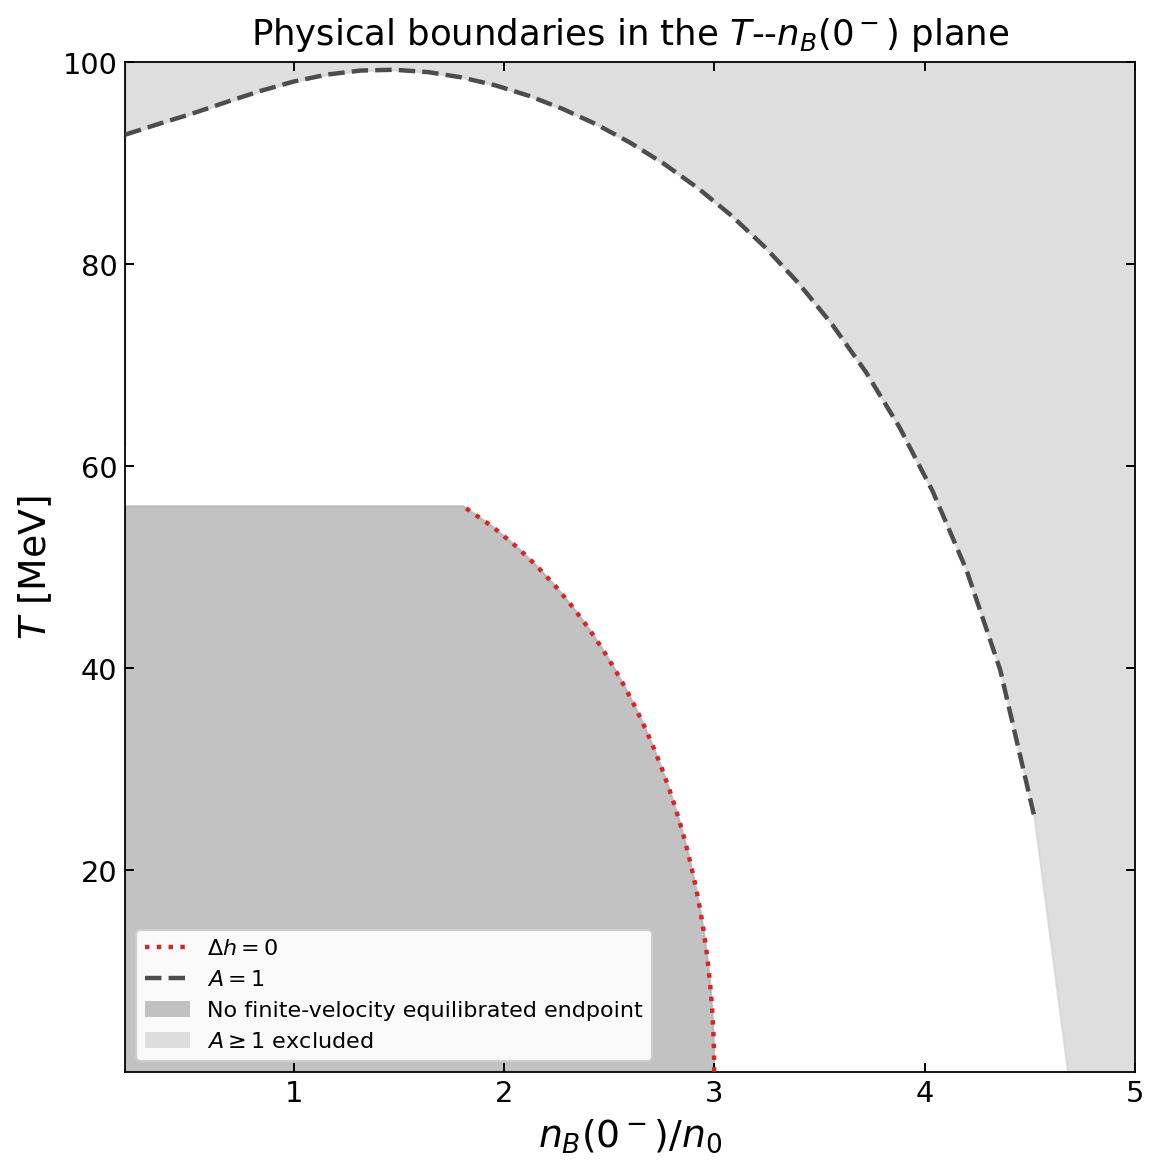

In [9]:
# Tunable plotting parameters
ABS_MAP_FIGURE_SIZE = (7.2, 7.2)
ABS_MAP_FIGURE_DPI = 160
ABS_MAP_EXPORT_DPI = 220
ABS_MAP_CONSTRAINED_LAYOUT = True
ABS_MAP_BACKGROUND_COLOR = "white"
ABS_MAP_X_LIMITS = (0.2, 5.0)
ABS_MAP_Y_LIMITS_MEV = (1.0e-2, 100.0)
ABS_MAP_X_SCALE = "linear"
ABS_MAP_Y_SCALE = "linear"
ABS_MAP_BOX_ASPECT = 1.0
ABS_MAP_GAP_COLOR = "#d62728"
ABS_MAP_GAP_LINE_STYLE = ":"
ABS_MAP_GAP_LINE_WIDTH = 2.0
ABS_MAP_A_COLOR = "0.30"
ABS_MAP_A_LINE_STYLE = "--"
ABS_MAP_A_LINE_WIDTH = 2.0
ABS_MAP_GAP_SHADE_COLOR = "0.70"
ABS_MAP_GAP_SHADE_ALPHA = 0.80
ABS_MAP_A_SHADE_COLOR = "0.84"
ABS_MAP_A_SHADE_ALPHA = 0.80
ABS_MAP_SHADE_ZORDER = 0
ABS_MAP_BOUNDARY_ZORDER = 3
ABS_MAP_SHOW_UNRESOLVED = True
ABS_MAP_UNRESOLVED_MARKER = "x"
ABS_MAP_UNRESOLVED_COLOR = "#9467bd"
ABS_MAP_UNRESOLVED_MARKER_SIZE = 28.0
ABS_MAP_UNRESOLVED_LINE_WIDTH = 1.0
ABS_MAP_UNRESOLVED_ZORDER = 4
ABS_MAP_TITLE = r"Physical boundaries in the $T$--$n_B(0^-)$ plane"
ABS_MAP_TITLE_FONT_SIZE = 16
ABS_MAP_TITLE_PAD = 8
ABS_MAP_X_LABEL = r"$n_B(0^-)/n_0$"
ABS_MAP_Y_LABEL = r"$T$ [MeV]"
ABS_MAP_AXIS_LABEL_FONT_SIZE = 17
ABS_MAP_TICK_LABEL_FONT_SIZE = 13
ABS_MAP_TICK_DIRECTION = "in"
ABS_MAP_TICKS_TOP = True
ABS_MAP_TICKS_RIGHT = True
ABS_MAP_TICK_LENGTH = 4.0
ABS_MAP_TICK_WIDTH = 0.9
ABS_MAP_SPINE_LINE_WIDTH = 0.8
ABS_MAP_LEGEND_FONT_SIZE = 10
ABS_MAP_LEGEND_LOCATION = "best"
ABS_MAP_LEGEND_FRAME_ALPHA = 0.92
ABS_MAP_OUTPUT_PNG = "local_analysis_results/26SU-9/T-nB-absolute-boundaries-0p2n0-to-5n0.png"
ABS_MAP_OUTPUT_PDF = "local_analysis_results/26SU-9/T-nB-absolute-boundaries-0p2n0-to-5n0.pdf"

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

abs_plot_T = np.asarray(abs_boundary_payload["temperature_values_MeV"], dtype=float)
abs_plot_gap_nB = np.asarray(abs_boundary_payload["gap_boundary_nB_over_n0"], dtype=float)
abs_plot_nB = np.asarray(abs_boundary_payload["density_values_over_n0"], dtype=float)
abs_plot_A_T = np.asarray(abs_boundary_payload["A_boundary_temperature_MeV"], dtype=float)
abs_figure, abs_axis = plt.subplots(
    figsize=ABS_MAP_FIGURE_SIZE,
    dpi=ABS_MAP_FIGURE_DPI,
    constrained_layout=ABS_MAP_CONSTRAINED_LAYOUT,
    facecolor=ABS_MAP_BACKGROUND_COLOR,
)
abs_axis.set_facecolor(ABS_MAP_BACKGROUND_COLOR)
abs_axis.set_xscale(ABS_MAP_X_SCALE)
abs_axis.set_yscale(ABS_MAP_Y_SCALE)
abs_axis.set_xlim(*ABS_MAP_X_LIMITS)
abs_axis.set_ylim(*ABS_MAP_Y_LIMITS_MEV)
abs_axis.set_box_aspect(ABS_MAP_BOX_ASPECT)
abs_finite_A = np.isfinite(abs_plot_nB) & np.isfinite(abs_plot_A_T)
abs_A_status = np.asarray([record["status"] for record in abs_boundary_payload["A_records"]], dtype=object)
abs_A_fill_boundary = abs_plot_A_T.copy()
abs_A_fill_boundary[abs_A_status == "all_A_forbidden"] = ABS_MAP_Y_LIMITS_MEV[0]
abs_A_fill_boundary[abs_A_status == "all_A_allowed"] = ABS_MAP_Y_LIMITS_MEV[1]
abs_finite_A_fill = np.isfinite(abs_plot_nB) & np.isfinite(abs_A_fill_boundary)
if np.any(abs_finite_A_fill):
    abs_axis.fill_between(
        abs_plot_nB,
        abs_A_fill_boundary,
        ABS_MAP_Y_LIMITS_MEV[1],
        where=abs_finite_A_fill,
        color=ABS_MAP_A_SHADE_COLOR,
        alpha=ABS_MAP_A_SHADE_ALPHA,
        interpolate=False,
        zorder=ABS_MAP_SHADE_ZORDER,
    )
abs_finite_gap = np.isfinite(abs_plot_T) & np.isfinite(abs_plot_gap_nB)
abs_gap_fill_lower = np.full(abs_plot_T.shape, np.nan)
abs_gap_fill_upper = np.full(abs_plot_T.shape, np.nan)
for abs_gap_index, abs_gap_record in enumerate(abs_boundary_payload["gap_records"]):
    abs_gap_status = str(abs_gap_record["status"])
    abs_gap_forbidden_low = bool(abs_gap_record["forbidden_on_low_density_side"])
    if abs_gap_status == "root" and np.isfinite(abs_plot_gap_nB[abs_gap_index]):
        if abs_gap_forbidden_low:
            abs_gap_fill_lower[abs_gap_index] = ABS_MAP_X_LIMITS[0]
            abs_gap_fill_upper[abs_gap_index] = abs_plot_gap_nB[abs_gap_index]
        else:
            abs_gap_fill_lower[abs_gap_index] = abs_plot_gap_nB[abs_gap_index]
            abs_gap_fill_upper[abs_gap_index] = ABS_MAP_X_LIMITS[1]
    elif abs_gap_status == "all_forbidden":
        abs_gap_fill_lower[abs_gap_index] = ABS_MAP_X_LIMITS[0]
        abs_gap_fill_upper[abs_gap_index] = ABS_MAP_X_LIMITS[1]
    elif abs_gap_status == "all_allowed":
        abs_gap_fill_lower[abs_gap_index] = ABS_MAP_X_LIMITS[0]
        abs_gap_fill_upper[abs_gap_index] = ABS_MAP_X_LIMITS[0]
abs_finite_gap_fill = np.isfinite(abs_gap_fill_lower) & np.isfinite(abs_gap_fill_upper)
if np.any(abs_finite_gap_fill):
    abs_axis.fill_betweenx(
        abs_plot_T,
        abs_gap_fill_lower,
        abs_gap_fill_upper,
        where=abs_finite_gap_fill,
        color=ABS_MAP_GAP_SHADE_COLOR,
        alpha=ABS_MAP_GAP_SHADE_ALPHA,
        interpolate=False,
        zorder=ABS_MAP_SHADE_ZORDER + 1,
    )
abs_axis.plot(
    np.ma.masked_invalid(abs_plot_gap_nB),
    abs_plot_T,
    color=ABS_MAP_GAP_COLOR,
    linestyle=ABS_MAP_GAP_LINE_STYLE,
    linewidth=ABS_MAP_GAP_LINE_WIDTH,
    zorder=ABS_MAP_BOUNDARY_ZORDER,
)
abs_axis.plot(
    abs_plot_nB,
    np.ma.masked_invalid(abs_plot_A_T),
    color=ABS_MAP_A_COLOR,
    linestyle=ABS_MAP_A_LINE_STYLE,
    linewidth=ABS_MAP_A_LINE_WIDTH,
    zorder=ABS_MAP_BOUNDARY_ZORDER,
)
abs_A_estimates = np.asarray([record["boundary_estimate_MeV"] for record in abs_boundary_payload["A_records"]], dtype=float)
abs_A_unresolved = ~np.isfinite(abs_plot_A_T) & np.isfinite(abs_A_estimates)
if ABS_MAP_SHOW_UNRESOLVED and np.any(abs_A_unresolved):
    abs_axis.scatter(
        abs_plot_nB[abs_A_unresolved],
        abs_A_estimates[abs_A_unresolved],
        marker=ABS_MAP_UNRESOLVED_MARKER,
        color=ABS_MAP_UNRESOLVED_COLOR,
        s=ABS_MAP_UNRESOLVED_MARKER_SIZE,
        linewidths=ABS_MAP_UNRESOLVED_LINE_WIDTH,
        zorder=ABS_MAP_UNRESOLVED_ZORDER,
    )
abs_axis.set_title(ABS_MAP_TITLE, fontsize=ABS_MAP_TITLE_FONT_SIZE, pad=ABS_MAP_TITLE_PAD)
abs_axis.set_xlabel(ABS_MAP_X_LABEL, fontsize=ABS_MAP_AXIS_LABEL_FONT_SIZE)
abs_axis.set_ylabel(ABS_MAP_Y_LABEL, fontsize=ABS_MAP_AXIS_LABEL_FONT_SIZE)
abs_axis.tick_params(
    direction=ABS_MAP_TICK_DIRECTION,
    top=ABS_MAP_TICKS_TOP,
    right=ABS_MAP_TICKS_RIGHT,
    length=ABS_MAP_TICK_LENGTH,
    width=ABS_MAP_TICK_WIDTH,
    labelsize=ABS_MAP_TICK_LABEL_FONT_SIZE,
)
for abs_spine in abs_axis.spines.values():
    abs_spine.set_linewidth(ABS_MAP_SPINE_LINE_WIDTH)
abs_legend_handles = [
    Line2D((0.0,), (0.0,), color=ABS_MAP_GAP_COLOR, linestyle=ABS_MAP_GAP_LINE_STYLE, linewidth=ABS_MAP_GAP_LINE_WIDTH, label=r"$\Delta h=0$"),
    Line2D((0.0,), (0.0,), color=ABS_MAP_A_COLOR, linestyle=ABS_MAP_A_LINE_STYLE, linewidth=ABS_MAP_A_LINE_WIDTH, label=r"$A=1$"),
    Patch(facecolor=ABS_MAP_GAP_SHADE_COLOR, alpha=ABS_MAP_GAP_SHADE_ALPHA, label="No finite-velocity equilibrated endpoint"),
    Patch(facecolor=ABS_MAP_A_SHADE_COLOR, alpha=ABS_MAP_A_SHADE_ALPHA, label=r"$A\geq1$ excluded"),
]
if ABS_MAP_SHOW_UNRESOLVED and np.any(abs_A_unresolved):
    abs_legend_handles.append(Line2D((0.0,), (0.0,), color=ABS_MAP_UNRESOLVED_COLOR, marker=ABS_MAP_UNRESOLVED_MARKER, linestyle="None", label="unresolved boundary"))
abs_axis.legend(
    handles=abs_legend_handles,
    fontsize=ABS_MAP_LEGEND_FONT_SIZE,
    loc=ABS_MAP_LEGEND_LOCATION,
    framealpha=ABS_MAP_LEGEND_FRAME_ALPHA,
)
abs_map_png = ABS_ROOT / ABS_MAP_OUTPUT_PNG
abs_map_pdf = ABS_ROOT / ABS_MAP_OUTPUT_PDF
abs_map_png.parent.mkdir(parents=True, exist_ok=True)
abs_figure.savefig(abs_map_png, dpi=ABS_MAP_EXPORT_DPI, facecolor=ABS_MAP_BACKGROUND_COLOR)
abs_figure.savefig(abs_map_pdf, facecolor=ABS_MAP_BACKGROUND_COLOR)
plt.show()

## Elliptical-ray boundary refinement on physical axes

The following cells use dimensionless elliptical-polar coordinates only to parameterize and refine the boundaries over $n_0\leq n_B(0^-)\leq5n_0$. The hidden origin remains at $n_B(0^-)=n_0$, with $X=[n_B(0^-)/n_0-1]/4$ and $Y=T/(100\,\mathrm{MeV})$. Every trial ray is converted back to the physical variables $n_B(0^-)/n_0$ and $T$ before evaluating the EOS. The final visualization remains a linear Cartesian plot in those physical coordinates.

In [10]:
# Tunable calculation parameters
ER_OUTPUT_PATH = "local_analysis_results/26SU-9/T-nB-elliptical-ray-boundaries.npy"
ER_FORCE_RECOMPUTE = False
ER_DENSITY_ORIGIN_OVER_N0 = 1.0
ER_DENSITY_SCALE_OVER_N0 = 4.0
ER_TEMPERATURE_SCALE_MEV = 100.0
ER_DENSITY_MIN_OVER_N0 = 1.0
ER_DENSITY_MAX_OVER_N0 = 5.0
ER_TEMPERATURE_MIN_MEV = 1.0e-2
ER_TEMPERATURE_MAX_MEV = 100.0
ER_INITIAL_ANGLE_COUNT = 9
ER_MAX_REFINEMENT_PASSES = 4
ER_MAX_CURVE_POINTS = 129
ER_CARTESIAN_DENSITY_CHORD_TOL_OVER_N0 = 2.5e-3
ER_CARTESIAN_TEMPERATURE_CHORD_TOL_MEV = 1.0e-1
ER_ENDPOINT_PROBE_COUNT = 25
ER_GAP_RAY_PROBE_COUNT = 15
ER_A_RAY_PROBE_COUNT = 15
ER_GAP_ROOT_XTOL = 1.0e-8
ER_GAP_ROOT_RTOL = 1.0e-11
ER_GAP_ACCEPT_RESIDUAL_MEV = 1.0e-4
ER_A_BISECTION_STEPS = 10
ER_A_ACCEPT_ONE_MINUS_A = 5.0e-3
ER_A_ACCEPT_BRACKET_RELATIVE_WIDTH = 1.0e-5
ER_ROUND_DIGITS = 12

from datetime import datetime, timezone

if "abs_enthalpy_gap" not in globals() or "abs_evaluate_A_state" not in globals():
    raise RuntimeError("Run the absolute-density setup and helper cells above first")


In [11]:
def er_to_internal_coordinates(nB_over_n0, temperature_MeV):
    X = (float(nB_over_n0) - ER_DENSITY_ORIGIN_OVER_N0) / ER_DENSITY_SCALE_OVER_N0
    Y = float(temperature_MeV) / ER_TEMPERATURE_SCALE_MEV
    return float(np.hypot(X, Y)), float(np.arctan2(Y, X))


def er_to_physical_coordinates(theta_rad, rho):
    nB_over_n0 = ER_DENSITY_ORIGIN_OVER_N0 + ER_DENSITY_SCALE_OVER_N0 * float(rho) * np.cos(float(theta_rad))
    temperature_MeV = ER_TEMPERATURE_SCALE_MEV * float(rho) * np.sin(float(theta_rad))
    return float(nB_over_n0), float(temperature_MeV)


def er_ray_rho_bounds(theta_rad):
    cosine = float(np.cos(theta_rad))
    sine = float(np.sin(theta_rad))
    if sine <= 0.0:
        raise ValueError("Interior ray angles must satisfy 0 < theta < pi")
    rho_min = ER_TEMPERATURE_MIN_MEV / (ER_TEMPERATURE_SCALE_MEV * sine)
    if cosine > 0.0:
        rho_max_density = (ER_DENSITY_MAX_OVER_N0 - ER_DENSITY_ORIGIN_OVER_N0) / (ER_DENSITY_SCALE_OVER_N0 * cosine)
    elif cosine < 0.0:
        rho_max_density = (ER_DENSITY_MIN_OVER_N0 - ER_DENSITY_ORIGIN_OVER_N0) / (ER_DENSITY_SCALE_OVER_N0 * cosine)
    else:
        rho_max_density = np.inf
    rho_max_temperature = ER_TEMPERATURE_MAX_MEV / (ER_TEMPERATURE_SCALE_MEV * sine)
    rho_max = min(rho_max_density, rho_max_temperature)
    if not (np.isfinite(rho_min) and np.isfinite(rho_max) and rho_min < rho_max):
        raise RuntimeError("Ray does not cross the requested physical window")
    return float(rho_min), float(rho_max)


def er_nearest_cached_state(cache, coordinate, state_key):
    candidates = [
        (abs(float(cached_coordinate) - float(coordinate)), row.get(state_key))
        for cached_coordinate, row in cache.items()
        if row.get(state_key) is not None
    ]
    return min(candidates, key=lambda item: item[0])[1] if candidates else None


def er_evaluate_gap_cartesian(nB_over_n0, temperature_MeV, initial_state=None):
    gap_MeV, muB_cold_MeV, state = abs_enthalpy_gap(
        float(nB_over_n0),
        float(temperature_MeV),
        initial_state=initial_state,
    )
    rho, theta_rad = er_to_internal_coordinates(nB_over_n0, temperature_MeV)
    return {
        "status": "success",
        "nB_over_n0": float(nB_over_n0),
        "T_MeV": float(temperature_MeV),
        "rho": rho,
        "theta_rad": theta_rad,
        "theta_deg": float(np.degrees(theta_rad)),
        "gap_MeV": float(gap_MeV),
        "muB_cold_MeV": float(muB_cold_MeV),
        "rmf_scaled_residual": float(state["rmf_scaled_residual"]),
        "state": state,
    }


def er_solve_gap_on_path(coordinates, physical_coordinates, label, initial_state=None):
    coordinates = np.asarray(coordinates, dtype=float)
    cache = {}
    def evaluate(coordinate, preferred_state=None):
        key = float(np.round(coordinate, ER_ROUND_DIGITS))
        if key not in cache:
            initial_state = er_nearest_cached_state(cache, key, "state")
            if initial_state is None:
                initial_state = preferred_state
            nB_over_n0, temperature_MeV = physical_coordinates(key)
            try:
                cache[key] = er_evaluate_gap_cartesian(nB_over_n0, temperature_MeV, initial_state=initial_state)
            except RuntimeError as seeded_error:
                try:
                    cache[key] = er_evaluate_gap_cartesian(nB_over_n0, temperature_MeV, initial_state=None)
                except RuntimeError as default_error:
                    cache[key] = {
                        "status": "numerical_failure",
                        "nB_over_n0": float(nB_over_n0),
                        "T_MeV": float(temperature_MeV),
                        "gap_MeV": np.nan,
                        "state": None,
                        "message": f"seeded: {seeded_error}; default: {default_error}",
                    }
        return cache[key]
    previous_state = initial_state
    rows = []
    for coordinate in coordinates:
        row = evaluate(coordinate, preferred_state=previous_state)
        rows.append(row)
        if row.get("state") is not None:
            previous_state = row["state"]
    brackets, exact_roots = abs_sign_change_brackets(coordinates, [row["gap_MeV"] for row in rows])
    roots = list(exact_roots)
    for lower, upper in brackets:
        roots.append(float(brentq(
            lambda coordinate: evaluate(coordinate)["gap_MeV"],
            float(lower),
            float(upper),
            xtol=ER_GAP_ROOT_XTOL,
            rtol=ER_GAP_ROOT_RTOL,
        )))
    roots = sorted({float(np.round(root, 10)) for root in roots})
    if len(roots) != 1:
        raise RuntimeError(f"{label}: expected one Delta h root, found {len(roots)}")
    result = dict(evaluate(roots[0]))
    result["boundary_kind"] = "Delta_h_equals_zero"
    result["solve_kind"] = label
    result["evaluation_count"] = len(cache)
    if abs(result["gap_MeV"]) > ER_GAP_ACCEPT_RESIDUAL_MEV:
        raise RuntimeError(f"{label}: Delta h residual did not close")
    return result


def er_evaluate_A_cartesian(nB_over_n0, temperature_MeV, endpoint_guess=None, nuclear_state_guess=None):
    result = abs_evaluate_A_state(
        float(nB_over_n0),
        float(temperature_MeV),
        endpoint_guess=endpoint_guess,
        nuclear_state_guess=nuclear_state_guess,
    )
    rho, theta_rad = er_to_internal_coordinates(nB_over_n0, temperature_MeV)
    result = dict(result)
    result.update({
        "nB_over_n0": float(nB_over_n0),
        "T_MeV": float(temperature_MeV),
        "rho": rho,
        "theta_rad": theta_rad,
        "theta_deg": float(np.degrees(theta_rad)),
    })
    return result


def er_solve_A_transition_on_path(
    coordinates,
    physical_coordinates,
    label,
    initial_endpoint=None,
    initial_nuclear_state=None,
):
    coordinates = np.asarray(coordinates, dtype=float)
    cache = {}
    def evaluate(coordinate, preferred_endpoint=None, preferred_nuclear_state=None):
        key = float(np.round(coordinate, ER_ROUND_DIGITS))
        if key not in cache:
            endpoint_guess = preferred_endpoint
            if endpoint_guess is None:
                successful = [
                    (abs(cached_coordinate - key), row["endpoint_solution"])
                    for cached_coordinate, row in cache.items()
                    if row.get("endpoint_solution") is not None
                ]
                if successful:
                    endpoint_guess = min(successful, key=lambda item: item[0])[1]
            nuclear_state_guess = er_nearest_cached_state(cache, key, "nuclear_state")
            if nuclear_state_guess is None:
                nuclear_state_guess = preferred_nuclear_state
            nB_over_n0, temperature_MeV = physical_coordinates(key)
            cache[key] = er_evaluate_A_cartesian(
                nB_over_n0,
                temperature_MeV,
                endpoint_guess=endpoint_guess,
                nuclear_state_guess=nuclear_state_guess,
            )
            if cache[key]["status"] == "numerical_failure":
                cache[key] = er_evaluate_A_cartesian(
                    nB_over_n0,
                    temperature_MeV,
                    endpoint_guess=None,
                    nuclear_state_guess=None,
                )
        return cache[key]
    previous_endpoint = initial_endpoint
    previous_nuclear_state = initial_nuclear_state
    rows = []
    for coordinate in coordinates:
        row = evaluate(
            coordinate,
            preferred_endpoint=previous_endpoint,
            preferred_nuclear_state=previous_nuclear_state,
        )
        rows.append(row)
        if row.get("endpoint_solution") is not None:
            previous_endpoint = row["endpoint_solution"]
        if row.get("nuclear_state") is not None:
            previous_nuclear_state = row["nuclear_state"]
    transitions = [
        (left_coordinate, right_coordinate, left_row, right_row)
        for left_coordinate, right_coordinate, left_row, right_row in zip(
            coordinates[:-1], coordinates[1:], rows[:-1], rows[1:]
        )
        if left_row["status"] == "success" and right_row["status"] == "A_forbidden"
    ]
    if len(transitions) != 1:
        status_counts = pd.Series([row["status"] for row in rows]).value_counts().to_dict()
        raise RuntimeError(f"{label}: expected one success-to-A transition, found {len(transitions)}; {status_counts}")
    lower, upper, lower_row, upper_row = transitions[0]
    coordinate_span = max(abs(float(coordinates[-1]) - float(coordinates[0])), np.finfo(float).eps)
    accepted_from_one_sided_bracket = False
    for _ in range(ER_A_BISECTION_STEPS):
        middle = 0.5 * (float(lower) + float(upper))
        middle_row = evaluate(
            middle,
            preferred_endpoint=lower_row.get("endpoint_solution"),
            preferred_nuclear_state=lower_row.get("nuclear_state"),
        )
        if middle_row["status"] == "success":
            lower, lower_row = middle, middle_row
        elif middle_row["status"] == "A_forbidden":
            upper, upper_row = middle, middle_row
        else:
            recovery_rows = []
            interval_width = float(upper) - float(lower)
            for fraction in (0.45, 0.55, 0.35, 0.65):
                recovery_coordinate = float(lower) + fraction * interval_width
                recovery_row = evaluate(
                    recovery_coordinate,
                    preferred_endpoint=lower_row.get("endpoint_solution"),
                    preferred_nuclear_state=lower_row.get("nuclear_state"),
                )
                recovery_rows.append((recovery_coordinate, recovery_row))
            successful_rows = [(float(lower), lower_row)] + [
                item for item in recovery_rows if item[1]["status"] == "success"
            ]
            forbidden_rows = [
                item for item in recovery_rows if item[1]["status"] == "A_forbidden"
            ] + [(float(upper), upper_row)]
            recovered_lower, recovered_lower_row = max(successful_rows, key=lambda item: item[0])
            valid_forbidden_rows = [item for item in forbidden_rows if item[0] > recovered_lower]
            if not valid_forbidden_rows:
                raise RuntimeError(
                    f"{label}: could not recover bisection after {middle_row['status']}: {middle_row.get('message', '')}"
                )
            recovered_upper, recovered_upper_row = min(valid_forbidden_rows, key=lambda item: item[0])
            if recovered_lower <= float(lower) and recovered_upper >= float(upper):
                current_relative_width = (float(upper) - float(lower)) / coordinate_span
                current_one_minus_A = float(1.0 - lower_row["A_boundary"])
                if (
                    np.isfinite(current_one_minus_A)
                    and current_one_minus_A <= ER_A_ACCEPT_ONE_MINUS_A
                    and current_relative_width <= ER_A_ACCEPT_BRACKET_RELATIVE_WIDTH
                ):
                    accepted_from_one_sided_bracket = True
                    break
                raise RuntimeError(
                    f"{label}: recovery did not shrink bracket after {middle_row['status']}; "
                    f"relative width={current_relative_width:.3e}, one_minus_A={current_one_minus_A:.3e}: "
                    f"{middle_row.get('message', '')}"
                )
            lower, lower_row = recovered_lower, recovered_lower_row
            upper, upper_row = recovered_upper, recovered_upper_row
    boundary_coordinate = 0.5 * (float(lower) + float(upper))
    nB_over_n0, temperature_MeV = physical_coordinates(boundary_coordinate)
    rho, theta_rad = er_to_internal_coordinates(nB_over_n0, temperature_MeV)
    residual = float(1.0 - lower_row["A_boundary"])
    coordinate_bracket_width = float(upper) - float(lower)
    coordinate_bracket_relative_width = coordinate_bracket_width / coordinate_span
    if residual > ER_A_ACCEPT_ONE_MINUS_A:
        raise RuntimeError(f"{label}: one-sided A residual did not close: {residual:.3e}")
    return {
        "status": "root",
        "boundary_kind": "A_equals_one",
        "solve_kind": label,
        "nB_over_n0": float(nB_over_n0),
        "T_MeV": float(temperature_MeV),
        "rho": rho,
        "theta_rad": theta_rad,
        "theta_deg": float(np.degrees(theta_rad)),
        "one_minus_A_residual": residual,
        "coordinate_bracket_width": coordinate_bracket_width,
        "coordinate_bracket_relative_width": coordinate_bracket_relative_width,
        "accepted_from_one_sided_bracket": bool(accepted_from_one_sided_bracket),
        "A_below_boundary": float(lower_row["A_boundary"]),
        "endpoint_solution": lower_row.get("endpoint_solution"),
        "nuclear_state": lower_row.get("nuclear_state"),
        "evaluation_count": len(cache),
    }


def er_ray_probe_values(theta_rad, count, rho_hint=None):
    rho_min, rho_max = er_ray_rho_bounds(theta_rad)
    probes = list(np.linspace(rho_min, rho_max, int(count)))
    if rho_hint is not None and np.isfinite(rho_hint):
        half_width = 0.12 * (rho_max - rho_min)
        probes.extend([
            np.clip(float(rho_hint) - half_width, rho_min, rho_max),
            np.clip(float(rho_hint), rho_min, rho_max),
            np.clip(float(rho_hint) + half_width, rho_min, rho_max),
        ])
    return np.asarray(sorted({float(np.round(value, ER_ROUND_DIGITS)) for value in probes}), dtype=float)


def er_solve_gap_on_ray(theta_rad, rho_hint=None, state_hint=None):
    probes = er_ray_probe_values(theta_rad, ER_GAP_RAY_PROBE_COUNT, rho_hint=rho_hint)
    return er_solve_gap_on_path(
        probes,
        lambda rho: er_to_physical_coordinates(theta_rad, rho),
        label="elliptical_ray",
        initial_state=state_hint,
    )


def er_solve_A_on_ray(theta_rad, rho_hint=None, endpoint_hint=None, nuclear_state_hint=None):
    if rho_hint is not None and np.isfinite(rho_hint):
        rho_min, rho_max = er_ray_rho_bounds(theta_rad)
        radial_span = rho_max - rho_min
        local_offsets = radial_span * np.asarray((-0.20, -0.10, -0.04, 0.0, 0.04, 0.10, 0.20))
        local_probes = np.asarray(sorted({
            float(np.round(np.clip(float(rho_hint) + offset, rho_min, rho_max), ER_ROUND_DIGITS))
            for offset in local_offsets
        }), dtype=float)
        try:
            return er_solve_A_transition_on_path(
                local_probes,
                lambda rho: er_to_physical_coordinates(theta_rad, rho),
                label="elliptical_ray_local",
                initial_endpoint=endpoint_hint,
                initial_nuclear_state=nuclear_state_hint,
            )
        except RuntimeError:
            pass
    probes = er_ray_probe_values(theta_rad, ER_A_RAY_PROBE_COUNT, rho_hint=rho_hint)
    return er_solve_A_transition_on_path(
        probes,
        lambda rho: er_to_physical_coordinates(theta_rad, rho),
        label="elliptical_ray_full",
        initial_endpoint=endpoint_hint,
        initial_nuclear_state=nuclear_state_hint,
    )


def er_chebyshev_angles(theta_min, theta_max, count):
    parameter = np.linspace(0.0, 1.0, int(count))
    clustered = 0.5 * (1.0 - np.cos(np.pi * parameter))
    return float(theta_min) + (float(theta_max) - float(theta_min)) * clustered


def er_nearest_curve_record(records, theta_rad):
    return min(records.values(), key=lambda row: abs(row["theta_rad"] - float(theta_rad)))


def er_solve_curve_point(kind, theta_rad, records):
    nearest = er_nearest_curve_record(records, theta_rad)
    if kind == "gap":
        return er_solve_gap_on_ray(
            theta_rad,
            rho_hint=nearest["rho"],
            state_hint=nearest.get("state"),
        )
    if kind == "A":
        return er_solve_A_on_ray(
            theta_rad,
            rho_hint=nearest["rho"],
            endpoint_hint=nearest.get("endpoint_solution"),
            nuclear_state_hint=nearest.get("nuclear_state"),
        )
    raise ValueError(f"Unknown curve kind: {kind}")


def er_build_refined_curve(kind, lower_endpoint, upper_endpoint):
    theta_values = er_chebyshev_angles(
        lower_endpoint["theta_rad"],
        upper_endpoint["theta_rad"],
        ER_INITIAL_ANGLE_COUNT,
    )
    records = {
        float(np.round(lower_endpoint["theta_rad"], ER_ROUND_DIGITS)): dict(lower_endpoint),
        float(np.round(upper_endpoint["theta_rad"], ER_ROUND_DIGITS)): dict(upper_endpoint),
    }
    interior = list(theta_values[1:-1])
    if interior:
        seed_index = int(np.argmin(np.abs(np.asarray(interior) - 0.5 * (theta_values[0] + theta_values[-1]))))
        solve_order = interior[seed_index:] + list(reversed(interior[:seed_index]))
        for theta_rad in tqdm(solve_order, desc=f"{kind} initial rays", unit="ray"):
            key = float(np.round(theta_rad, ER_ROUND_DIGITS))
            records[key] = er_solve_curve_point(kind, key, records)
    ordered_keys = sorted(records)
    active_segments = list(zip(ordered_keys[:-1], ordered_keys[1:]))
    refinement_summary = []
    for refinement_pass in range(ER_MAX_REFINEMENT_PASSES):
        next_segments = []
        max_density_error = 0.0
        max_temperature_error = 0.0
        for left_key, right_key in tqdm(active_segments, desc=f"{kind} refinement {refinement_pass + 1}", unit="segment"):
            if len(records) >= ER_MAX_CURVE_POINTS:
                break
            midpoint_key = float(np.round(0.5 * (left_key + right_key), ER_ROUND_DIGITS))
            if midpoint_key not in records:
                records[midpoint_key] = er_solve_curve_point(kind, midpoint_key, records)
            left = records[left_key]
            right = records[right_key]
            midpoint = records[midpoint_key]
            density_error = abs(midpoint["nB_over_n0"] - 0.5 * (left["nB_over_n0"] + right["nB_over_n0"]))
            temperature_error = abs(midpoint["T_MeV"] - 0.5 * (left["T_MeV"] + right["T_MeV"]))
            midpoint["density_chord_error_over_n0"] = float(density_error)
            midpoint["temperature_chord_error_MeV"] = float(temperature_error)
            max_density_error = max(max_density_error, density_error)
            max_temperature_error = max(max_temperature_error, temperature_error)
            if (
                density_error > ER_CARTESIAN_DENSITY_CHORD_TOL_OVER_N0
                or temperature_error > ER_CARTESIAN_TEMPERATURE_CHORD_TOL_MEV
            ):
                next_segments.extend([(left_key, midpoint_key), (midpoint_key, right_key)])
        refinement_summary.append({
            "pass": refinement_pass + 1,
            "tested_segments": len(active_segments),
            "segments_requiring_refinement": len(next_segments) // 2,
            "maximum_density_chord_error_over_n0": float(max_density_error),
            "maximum_temperature_chord_error_MeV": float(max_temperature_error),
        })
        active_segments = next_segments
        if not active_segments or len(records) >= ER_MAX_CURVE_POINTS:
            break
    return [records[key] for key in sorted(records)], refinement_summary


def er_public_record(record):
    excluded = {"state", "nuclear_state"}
    return {key: value for key, value in record.items() if key not in excluded}


def er_run_refined_boundary_scan():
    density_probes = np.linspace(ER_DENSITY_MIN_OVER_N0, ER_DENSITY_MAX_OVER_N0, ER_ENDPOINT_PROBE_COUNT)
    temperature_probes = np.linspace(ER_TEMPERATURE_MIN_MEV, ER_TEMPERATURE_MAX_MEV, ER_ENDPOINT_PROBE_COUNT)
    gap_bottom = er_solve_gap_on_path(
        density_probes,
        lambda nB_over_n0: (nB_over_n0, ER_TEMPERATURE_MIN_MEV),
        label="fixed_T_minimum",
    )
    gap_left = er_solve_gap_on_path(
        temperature_probes,
        lambda temperature_MeV: (ER_DENSITY_MIN_OVER_N0, temperature_MeV),
        label="fixed_nB_minimum",
    )
    A_bottom = er_solve_A_transition_on_path(
        density_probes,
        lambda nB_over_n0: (nB_over_n0, ER_TEMPERATURE_MIN_MEV),
        label="fixed_T_minimum",
    )
    A_left = er_solve_A_transition_on_path(
        temperature_probes,
        lambda temperature_MeV: (ER_DENSITY_MIN_OVER_N0, temperature_MeV),
        label="fixed_nB_minimum",
    )
    gap_records, gap_refinement = er_build_refined_curve("gap", gap_bottom, gap_left)
    A_records, A_refinement = er_build_refined_curve("A", A_bottom, A_left)
    return {
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "gap_records": [er_public_record(record) for record in gap_records],
        "A_records": [er_public_record(record) for record in A_records],
        "gap_refinement": gap_refinement,
        "A_refinement": A_refinement,
        "transform": {
            "density_origin_over_n0": ER_DENSITY_ORIGIN_OVER_N0,
            "density_scale_over_n0": ER_DENSITY_SCALE_OVER_N0,
            "temperature_scale_MeV": ER_TEMPERATURE_SCALE_MEV,
            "rho_definition": "sqrt(((nB_over_n0-1)/4)^2+(T_MeV/100)^2)",
            "theta_definition": "atan2(T_MeV/100,(nB_over_n0-1)/4)",
        },
        "physical_window": {
            "density_min_over_n0": ER_DENSITY_MIN_OVER_N0,
            "density_max_over_n0": ER_DENSITY_MAX_OVER_N0,
            "temperature_min_MeV": ER_TEMPERATURE_MIN_MEV,
            "temperature_max_MeV": ER_TEMPERATURE_MAX_MEV,
        },
        "calculation_arguments": {
            "initial_angle_count": ER_INITIAL_ANGLE_COUNT,
            "maximum_refinement_passes": ER_MAX_REFINEMENT_PASSES,
            "maximum_curve_points": ER_MAX_CURVE_POINTS,
            "density_chord_tolerance_over_n0": ER_CARTESIAN_DENSITY_CHORD_TOL_OVER_N0,
            "temperature_chord_tolerance_MeV": ER_CARTESIAN_TEMPERATURE_CHORD_TOL_MEV,
            "gap_accept_residual_MeV": ER_GAP_ACCEPT_RESIDUAL_MEV,
            "A_accept_one_minus_A": ER_A_ACCEPT_ONE_MINUS_A,
        },
        "coordinate_usage": "elliptical_rays_for_calculation_physical_cartesian_for_visualization",
    }


In [12]:
er_output_path = ABS_ROOT / ER_OUTPUT_PATH
if ER_FORCE_RECOMPUTE or not er_output_path.exists():
    er_boundary_payload = er_run_refined_boundary_scan()
    abs_atomic_save(er_output_path, er_boundary_payload)
    print(f"Saved {er_output_path}")
else:
    er_boundary_payload = np.load(er_output_path, allow_pickle=True).item()
    print(f"Loaded {er_output_path}")


Loaded /Users/janshao/NSM_related/local_analysis_results/26SU-9/T-nB-elliptical-ray-boundaries.npy


In [13]:
er_gap_diagnostics = pd.DataFrame(er_boundary_payload["gap_records"])
er_A_diagnostics = pd.DataFrame(er_boundary_payload["A_records"])
er_summary = pd.DataFrame({
    "boundary": ("Delta h=0", "A=1"),
    "ray-refined points": (len(er_gap_diagnostics), len(er_A_diagnostics)),
    "theta minimum [deg]": (er_gap_diagnostics["theta_deg"].min(), er_A_diagnostics["theta_deg"].min()),
    "theta maximum [deg]": (er_gap_diagnostics["theta_deg"].max(), er_A_diagnostics["theta_deg"].max()),
})
display(er_summary)
er_all_records = er_boundary_payload["gap_records"] + er_boundary_payload["A_records"]
er_round_trip_errors = []
for er_record in er_all_records:
    er_nB_round_trip, er_T_round_trip = er_to_physical_coordinates(er_record["theta_rad"], er_record["rho"])
    er_round_trip_errors.append((
        abs(er_nB_round_trip - er_record["nB_over_n0"]),
        abs(er_T_round_trip - er_record["T_MeV"]),
    ))
er_max_density_round_trip = float(max(error[0] for error in er_round_trip_errors))
er_max_temperature_round_trip = float(max(error[1] for error in er_round_trip_errors))
er_max_gap_residual = float(np.max(np.abs(er_gap_diagnostics["gap_MeV"])))
er_max_A_residual = float(np.max(np.abs(er_A_diagnostics["one_minus_A_residual"])))
print(f"maximum density round-trip error = {er_max_density_round_trip:.3e} n0")
print(f"maximum temperature round-trip error = {er_max_temperature_round_trip:.3e} MeV")
print(f"maximum |Delta h| residual = {er_max_gap_residual:.3e} MeV")
print(f"maximum one-sided 1-A residual = {er_max_A_residual:.3e}")
if er_max_density_round_trip > 1.0e-10 or er_max_temperature_round_trip > 1.0e-9:
    raise RuntimeError("Elliptical-coordinate round trip failed")
if er_max_gap_residual > ER_GAP_ACCEPT_RESIDUAL_MEV:
    raise RuntimeError("Ray-refined Delta h boundary contains a non-closing root")
if er_max_A_residual > ER_A_ACCEPT_ONE_MINUS_A:
    raise RuntimeError("Ray-refined A boundary did not approach A=1")
for er_name, er_records in (("Delta h", er_gap_diagnostics), ("A", er_A_diagnostics)):
    if not np.all(np.diff(er_records["theta_rad"].to_numpy(dtype=float)) > 0.0):
        raise RuntimeError(f"{er_name} boundary is not ordered monotonically in theta")
for er_name, er_refinement in (("Delta h", er_boundary_payload["gap_refinement"]), ("A", er_boundary_payload["A_refinement"])):
    display(pd.DataFrame(er_refinement).assign(boundary=er_name))
    if er_refinement and er_refinement[-1]["segments_requiring_refinement"] > 0:
        raise RuntimeError(f"{er_name} curve still exceeds the Cartesian chord tolerance")


,boundary,ray-refined points,theta minimum [deg],theta maximum [deg]
0,Delta h=0,45,0.011459,90.0
1,A=1,55,0.006320,90.0


maximum density round-trip error = 4.441e-16 n0
maximum temperature round-trip error = 2.842e-14 MeV
maximum |Delta h| residual = 6.224e-07 MeV
maximum one-sided 1-A residual = 7.115e-05


,pass,tested_segments,segments_requiring_refinement,maximum_density_chord_error_over_n0,maximum_temperature_chord_error_MeV,boundary
0,1,8,6,0.023534,0.556737,Delta h
1,2,12,8,0.005897,0.160410,Delta h
2,3,16,0,0.001481,0.042977,Delta h


,pass,tested_segments,segments_requiring_refinement,maximum_density_chord_error_over_n0,maximum_temperature_chord_error_MeV,boundary
0,1,8,6,0.039183,0.982176,A
1,2,12,11,0.010220,0.277179,A
2,3,22,2,0.002625,0.071798,A
3,4,4,0,0.000679,0.012779,A


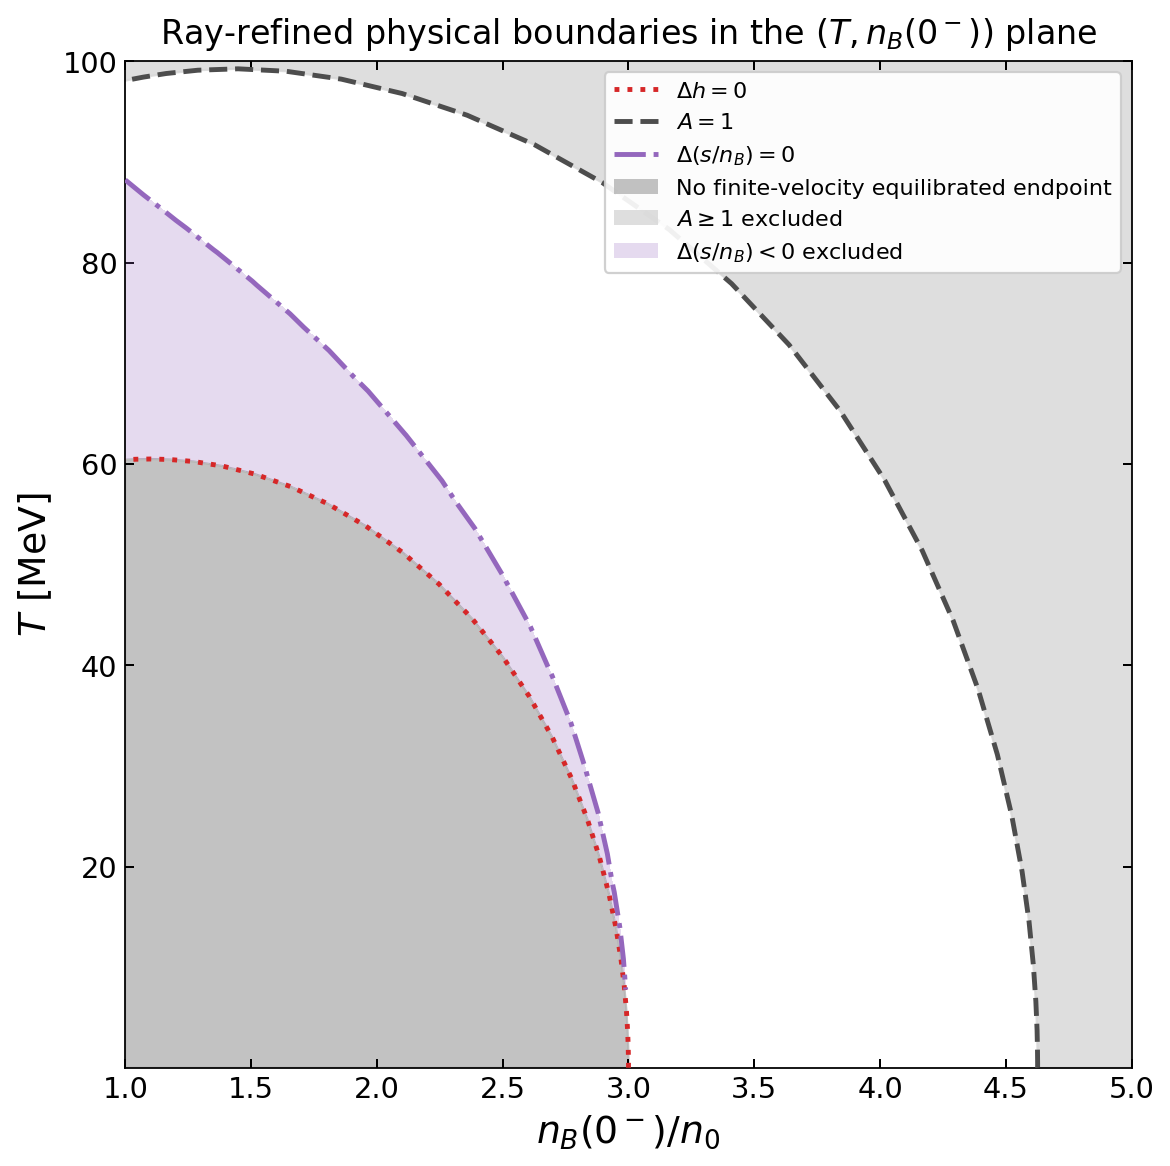

In [14]:
# Tunable plotting parameters
ER_MAP_FIGURE_SIZE = (7.2, 7.2)
ER_MAP_FIGURE_DPI = 160
ER_MAP_EXPORT_DPI = 220
ER_MAP_CONSTRAINED_LAYOUT = True
ER_MAP_BACKGROUND_COLOR = "white"
ER_MAP_X_LIMITS = (1.0, 5.0)
ER_MAP_Y_LIMITS_MEV = (1.0e-2, 100.0)
ER_MAP_X_SCALE = "linear"
ER_MAP_Y_SCALE = "linear"
ER_MAP_BOX_ASPECT = 1.0
ER_MAP_GAP_COLOR = "#d62728"
ER_MAP_GAP_LINE_STYLE = ":"
ER_MAP_GAP_LINE_WIDTH = 2.2
ER_MAP_A_COLOR = "0.30"
ER_MAP_A_LINE_STYLE = "--"
ER_MAP_A_LINE_WIDTH = 2.2
ER_MAP_GAP_SHADE_COLOR = "0.70"
ER_MAP_GAP_SHADE_ALPHA = 0.80
ER_MAP_A_SHADE_COLOR = "0.84"
ER_MAP_A_SHADE_ALPHA = 0.80
ER_MAP_ENTROPY_COLOR = "#9467bd"
ER_MAP_ENTROPY_LINE_STYLE = "-."
ER_MAP_ENTROPY_LINE_WIDTH = 2.2
ER_MAP_ENTROPY_SHADE_ALPHA = 0.24
ER_MAP_ENTROPY_BOUNDARY = 0.0
ER_MAP_ENTROPY_SHADE_ZORDER = 2
ER_MAP_ENTROPY_LINE_ZORDER = 4
ER_MAP_SHOW_ORIGINAL_SAMPLES = False
ER_MAP_ORIGINAL_MARKER = "o"
ER_MAP_ORIGINAL_MARKER_SIZE = 12.0
ER_MAP_ORIGINAL_ALPHA = 0.35
ER_MAP_ORIGINAL_COLOR = "#9467bd"
ER_MAP_TITLE = r"Ray-refined physical boundaries in the $(T,n_B(0^-))$ plane"
ER_MAP_TITLE_FONT_SIZE = 15
ER_MAP_TITLE_PAD = 8
ER_MAP_X_LABEL = r"$n_B(0^-)/n_0$"
ER_MAP_Y_LABEL = r"$T$ [MeV]"
ER_MAP_AXIS_LABEL_FONT_SIZE = 17
ER_MAP_TICK_LABEL_FONT_SIZE = 13
ER_MAP_TICK_DIRECTION = "in"
ER_MAP_TICKS_TOP = True
ER_MAP_TICKS_RIGHT = True
ER_MAP_TICK_LENGTH = 4.0
ER_MAP_TICK_WIDTH = 0.9
ER_MAP_SPINE_LINE_WIDTH = 0.8
ER_MAP_LEGEND_FONT_SIZE = 10
ER_MAP_LEGEND_LOCATION = "best"
ER_MAP_LEGEND_FRAME_ALPHA = 0.92
ER_MAP_CLUSTER_PAYLOAD_PATH = "new_paper_calculations/26-07-24/analytic-uN-elliptical-ray-grid.npy"
ER_MAP_OUTPUT_PNG = "local_analysis_results/26SU-9/T-nB-elliptical-ray-boundaries-n0-to-5n0.png"
ER_MAP_OUTPUT_PDF = "local_analysis_results/26SU-9/T-nB-elliptical-ray-boundaries-n0-to-5n0.pdf"

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

er_map_payload = np.load(ABS_ROOT / ER_MAP_CLUSTER_PAYLOAD_PATH, allow_pickle=True).item()
er_gap_nB = np.asarray(er_map_payload["gap_boundary_nB_over_n0"], dtype=float)
er_gap_T = np.asarray(er_map_payload["gap_boundary_temperature_MeV"], dtype=float)
er_A_nB = np.asarray(er_map_payload["A_boundary_nB_over_n0"], dtype=float)
er_A_T = np.asarray(er_map_payload["A_boundary_temperature_MeV"], dtype=float)
er_entropy_nB = np.asarray(er_map_payload["nB_grid_over_n0"], dtype=float)
er_entropy_T = np.asarray(er_map_payload["temperature_grid_MeV"], dtype=float)
er_entropy_jump = np.ma.masked_invalid(np.asarray(er_map_payload["entropy_jump_grid"], dtype=float))
er_figure, er_axis = plt.subplots(
    figsize=ER_MAP_FIGURE_SIZE,
    dpi=ER_MAP_FIGURE_DPI,
    constrained_layout=ER_MAP_CONSTRAINED_LAYOUT,
    facecolor=ER_MAP_BACKGROUND_COLOR,
)
er_axis.set_facecolor(ER_MAP_BACKGROUND_COLOR)
er_axis.set_xscale(ER_MAP_X_SCALE)
er_axis.set_yscale(ER_MAP_Y_SCALE)
er_axis.set_xlim(*ER_MAP_X_LIMITS)
er_axis.set_ylim(*ER_MAP_Y_LIMITS_MEV)
er_axis.set_box_aspect(ER_MAP_BOX_ASPECT)
er_A_polygon_nB = np.concatenate((
    er_A_nB,
    [ER_MAP_X_LIMITS[0], ER_MAP_X_LIMITS[1], ER_MAP_X_LIMITS[1], er_A_nB[0]],
))
er_A_polygon_T = np.concatenate((
    er_A_T,
    [ER_MAP_Y_LIMITS_MEV[1], ER_MAP_Y_LIMITS_MEV[1], ER_MAP_Y_LIMITS_MEV[0], ER_MAP_Y_LIMITS_MEV[0]],
))
er_axis.fill(
    er_A_polygon_nB,
    er_A_polygon_T,
    color=ER_MAP_A_SHADE_COLOR,
    alpha=ER_MAP_A_SHADE_ALPHA,
    zorder=0,
)
er_gap_polygon_nB = np.concatenate((
    [ER_MAP_X_LIMITS[0], er_gap_nB[0]],
    er_gap_nB[1:],
    [ER_MAP_X_LIMITS[0]],
))
er_gap_polygon_T = np.concatenate((
    [ER_MAP_Y_LIMITS_MEV[0], ER_MAP_Y_LIMITS_MEV[0]],
    er_gap_T[1:],
    [ER_MAP_Y_LIMITS_MEV[0]],
))
er_axis.fill(
    er_gap_polygon_nB,
    er_gap_polygon_T,
    color=ER_MAP_GAP_SHADE_COLOR,
    alpha=ER_MAP_GAP_SHADE_ALPHA,
    zorder=1,
)
er_entropy_finite = np.asarray(er_entropy_jump.compressed(), dtype=float)
if (
    er_entropy_finite.size
    and np.min(er_entropy_finite) < ER_MAP_ENTROPY_BOUNDARY
    and np.max(er_entropy_finite) > ER_MAP_ENTROPY_BOUNDARY
):
    er_axis.contourf(
        er_entropy_nB,
        er_entropy_T,
        er_entropy_jump,
        levels=(float(np.min(er_entropy_finite)), ER_MAP_ENTROPY_BOUNDARY),
        colors=(ER_MAP_ENTROPY_COLOR,),
        alpha=ER_MAP_ENTROPY_SHADE_ALPHA,
        zorder=ER_MAP_ENTROPY_SHADE_ZORDER,
    )
    er_axis.contour(
        er_entropy_nB,
        er_entropy_T,
        er_entropy_jump,
        levels=(ER_MAP_ENTROPY_BOUNDARY,),
        colors=(ER_MAP_ENTROPY_COLOR,),
        linestyles=(ER_MAP_ENTROPY_LINE_STYLE,),
        linewidths=(ER_MAP_ENTROPY_LINE_WIDTH,),
        zorder=ER_MAP_ENTROPY_LINE_ZORDER,
    )
er_axis.plot(
    er_gap_nB,
    er_gap_T,
    color=ER_MAP_GAP_COLOR,
    linestyle=ER_MAP_GAP_LINE_STYLE,
    linewidth=ER_MAP_GAP_LINE_WIDTH,
    zorder=3,
)
er_axis.plot(
    er_A_nB,
    er_A_T,
    color=ER_MAP_A_COLOR,
    linestyle=ER_MAP_A_LINE_STYLE,
    linewidth=ER_MAP_A_LINE_WIDTH,
    zorder=3,
)
if ER_MAP_SHOW_ORIGINAL_SAMPLES:
    er_axis.scatter(
        abs_plot_gap_nB,
        abs_plot_T,
        marker=ER_MAP_ORIGINAL_MARKER,
        s=ER_MAP_ORIGINAL_MARKER_SIZE,
        color=ER_MAP_ORIGINAL_COLOR,
        alpha=ER_MAP_ORIGINAL_ALPHA,
        zorder=4,
    )
    er_axis.scatter(
        abs_plot_nB,
        abs_plot_A_T,
        marker=ER_MAP_ORIGINAL_MARKER,
        s=ER_MAP_ORIGINAL_MARKER_SIZE,
        color=ER_MAP_ORIGINAL_COLOR,
        alpha=ER_MAP_ORIGINAL_ALPHA,
        zorder=4,
    )
er_axis.set_title(ER_MAP_TITLE, fontsize=ER_MAP_TITLE_FONT_SIZE, pad=ER_MAP_TITLE_PAD)
er_axis.set_xlabel(ER_MAP_X_LABEL, fontsize=ER_MAP_AXIS_LABEL_FONT_SIZE)
er_axis.set_ylabel(ER_MAP_Y_LABEL, fontsize=ER_MAP_AXIS_LABEL_FONT_SIZE)
er_axis.tick_params(
    direction=ER_MAP_TICK_DIRECTION,
    top=ER_MAP_TICKS_TOP,
    right=ER_MAP_TICKS_RIGHT,
    length=ER_MAP_TICK_LENGTH,
    width=ER_MAP_TICK_WIDTH,
    labelsize=ER_MAP_TICK_LABEL_FONT_SIZE,
)
for er_spine in er_axis.spines.values():
    er_spine.set_linewidth(ER_MAP_SPINE_LINE_WIDTH)
er_legend_handles = [
    Line2D((0.0,), (0.0,), color=ER_MAP_GAP_COLOR, linestyle=ER_MAP_GAP_LINE_STYLE, linewidth=ER_MAP_GAP_LINE_WIDTH, label=r"$\Delta h=0$"),
    Line2D((0.0,), (0.0,), color=ER_MAP_A_COLOR, linestyle=ER_MAP_A_LINE_STYLE, linewidth=ER_MAP_A_LINE_WIDTH, label=r"$A=1$"),
    Line2D((0.0,), (0.0,), color=ER_MAP_ENTROPY_COLOR, linestyle=ER_MAP_ENTROPY_LINE_STYLE, linewidth=ER_MAP_ENTROPY_LINE_WIDTH, label=r"$\Delta(s/n_B)=0$"),
    Patch(facecolor=ER_MAP_GAP_SHADE_COLOR, alpha=ER_MAP_GAP_SHADE_ALPHA, label="No finite-velocity equilibrated endpoint"),
    Patch(facecolor=ER_MAP_A_SHADE_COLOR, alpha=ER_MAP_A_SHADE_ALPHA, label=r"$A\geq1$ excluded"),
    Patch(facecolor=ER_MAP_ENTROPY_COLOR, alpha=ER_MAP_ENTROPY_SHADE_ALPHA, label=r"$\Delta(s/n_B)<0$ excluded"),
]
er_axis.legend(
    handles=er_legend_handles,
    fontsize=ER_MAP_LEGEND_FONT_SIZE,
    loc=ER_MAP_LEGEND_LOCATION,
    framealpha=ER_MAP_LEGEND_FRAME_ALPHA,
)
er_map_png = ABS_ROOT / ER_MAP_OUTPUT_PNG
er_map_pdf = ABS_ROOT / ER_MAP_OUTPUT_PDF
er_map_png.parent.mkdir(parents=True, exist_ok=True)
er_figure.savefig(er_map_png, dpi=ER_MAP_EXPORT_DPI, facecolor=ER_MAP_BACKGROUND_COLOR)
er_figure.savefig(er_map_pdf, facecolor=ER_MAP_BACKGROUND_COLOR)
plt.show()


## Analytical cluster velocity contour on the physical density plane

The two `26-07-24` cluster payloads are compared field by field before plotting. Their physical grids, status masks, boundaries, and velocities agree to floating-point roundoff, so the contour below uses the payload from `new_paper_calculations/26-07-24/`.

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

RAY_CLUSTER_ROOT = Path.cwd()
RAY_CLUSTER_PATHS = (
    RAY_CLUSTER_ROOT / "new_paper_calculations/26-07-24/analytic-uN-elliptical-ray-grid.npy",
    RAY_CLUSTER_ROOT / "new_paper_calculations/26-07-24-2/analytic-uN-elliptical-ray-grid.npy",
)
RAY_COMPARISON_FIELDS = (
    "nB_grid_over_n0",
    "temperature_grid_MeV",
    "velocity_grid_m_s",
    "status_grid",
    "gap_boundary_nB_over_n0",
    "gap_boundary_temperature_MeV",
    "A_boundary_nB_over_n0",
    "A_boundary_temperature_MeV",
)
RAY_COMPARISON_RTOL = 2.0e-9
RAY_COMPARISON_ATOL = 2.0e-5

ray_cluster_payloads = tuple(
    np.load(path, allow_pickle=True).item() for path in RAY_CLUSTER_PATHS
)
ray_comparison_rows = []
for ray_field in RAY_COMPARISON_FIELDS:
    ray_first = np.asarray(ray_cluster_payloads[0][ray_field])
    ray_second = np.asarray(ray_cluster_payloads[1][ray_field])
    ray_finite = np.isfinite(ray_first) & np.isfinite(ray_second)
    ray_max_difference = (
        float(np.max(np.abs(ray_first[ray_finite] - ray_second[ray_finite])))
        if np.any(ray_finite)
        else 0.0
    )
    ray_comparison_rows.append({
        "field": ray_field,
        "shape": ray_first.shape,
        "same NaN mask": bool(np.array_equal(np.isnan(ray_first), np.isnan(ray_second))),
        "maximum absolute difference": ray_max_difference,
        "equal within tolerance": bool(np.allclose(
            ray_first,
            ray_second,
            rtol=RAY_COMPARISON_RTOL,
            atol=RAY_COMPARISON_ATOL,
            equal_nan=True,
        )),
    })
ray_comparison = pd.DataFrame(ray_comparison_rows)
display(ray_comparison)
if not bool(ray_comparison["equal within tolerance"].all()):
    raise RuntimeError("The two analytical cluster payloads are not numerically equivalent")
ray_cluster_payload = ray_cluster_payloads[0]
print(f"Using {RAY_CLUSTER_PATHS[0]}")
print(
    f"Finite velocity cells: {np.count_nonzero(np.isfinite(ray_cluster_payload['velocity_grid_m_s']))}"
    f"/{np.asarray(ray_cluster_payload['velocity_grid_m_s']).size}"
)


,field,shape,same NaN mask,maximum absolute difference,equal within tolerance
0,nB_grid_over_n0,"(30, 20)",True,3.986145e-12,True
1,temperature_grid_MeV,"(30, 20)",True,7.891288e-11,True
2,velocity_grid_m_s,"(30, 20)",True,1.145166e-05,True
3,status_grid,"(30, 20)",True,0.000000e+00,True
4,gap_boundary_nB_over_n0,"(31,)",True,3.996803e-12,True
5,gap_boundary_temperature_MeV,"(31,)",True,7.911893e-11,True
6,A_boundary_nB_over_n0,"(31,)",True,0.000000e+00,True
7,A_boundary_temperature_MeV,"(31,)",True,0.000000e+00,True


Using /Users/janshao/NSM_related/new_paper_calculations/26-07-24/analytic-uN-elliptical-ray-grid.npy
Finite velocity cells: 600/600


In [16]:
# Tunable transition-curve calculation parameters
RAY_TRANSITION_REFERENCE_PAYLOAD_PATH = "new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy"
RAY_TRANSITION_TEMPERATURE_LIMITS_MEV = (0.0, 115.0)
RAY_CONTOUR_CRITICAL_DENSITY_TEMPERATURE_COUNT = 61
RAY_CONTOUR_CRITICAL_MUB_LIMITS_MEV = (300.0, 1600.0)
RAY_CONTOUR_CRITICAL_MUB_BRACKET_HALF_WIDTHS_MEV = (30.0, 60.0, 120.0, 240.0, 480.0)
RAY_CONTOUR_CRITICAL_MUB_FALLBACK_PROBE_COUNT = 65
RAY_CONTOUR_CRITICAL_ROOT_XTOL = 1.0e-7
RAY_CONTOUR_CRITICAL_ROOT_RTOL = 1.0e-10
RAY_CONTOUR_CRITICAL_ROOT_MAXITER = 200
RAY_CONTOUR_UD_CRITICAL_TEMPERATURE_COUNT = 21
RAY_CONTOUR_UD_INITIAL_STATE_MEV = (1640.0, 587.0)
RAY_CONTOUR_UD_PRESSURE_RESIDUAL_SCALE = 1.0e8
RAY_CONTOUR_UD_DENSITY_RESIDUAL_SCALE = 1.0e6
RAY_CONTOUR_UD_ROOT_XTOL = 1.0e-9
RAY_CONTOUR_UD_ROOT_RESIDUAL_TOLERANCE = 1.0e-7

from pathlib import Path

import numpy as np
import RMFsolver.RMFparameter as ray_para
from RMFsolver import phase_velocity as ray_phase_velocity
from scipy.optimize import brentq, root

ray_analytic_contour_root = Path.cwd()
ray_transition_reference_path = ray_analytic_contour_root / RAY_TRANSITION_REFERENCE_PAYLOAD_PATH
ray_analytic_contour_payload = np.load(
    ray_transition_reference_path,
    allow_pickle=True,
).item()
RAY_CONTOUR_Y_LIMITS_MEV = RAY_TRANSITION_TEMPERATURE_LIMITS_MEV
ray_calibration = ray_analytic_contour_payload["calibration"]
ray_arguments = ray_analytic_contour_payload["arguments"]
ray_n0 = float(ray_calibration["n0_MeV3"])
ray_B14 = float(ray_calibration["B14_calibrated_MeV"])
ray_muB_crit0 = float(ray_calibration["muB_crit0_MeV"])
ray_ms = float(ray_arguments["ms"])
ray_upB = int(ray_arguments["upB"])
ray_nm_type = str(ray_arguments["nm_type"])
ray_critical_temperature = np.linspace(
    RAY_CONTOUR_Y_LIMITS_MEV[0],
    RAY_CONTOUR_Y_LIMITS_MEV[1],
    RAY_CONTOUR_CRITICAL_DENSITY_TEMPERATURE_COUNT,
)
ray_critical_muB = np.full(ray_critical_temperature.shape, np.nan)
ray_critical_density = np.full(ray_critical_temperature.shape, np.nan)

def ray_critical_pressure_residual(muB_MeV, temperature_MeV):
    return float(
        ray_phase_velocity.PNM(
            float(muB_MeV),
            float(temperature_MeV),
            param=ray_para.paraQMCRMF3,
            NM_type=ray_nm_type,
        )
        - ray_phase_velocity.PQM(
            float(muB_MeV),
            0.0,
            ray_B14,
            float(temperature_MeV),
            ms=ray_ms,
            upB=ray_upB,
        )
    )

ray_previous_muB = ray_muB_crit0
for ray_critical_index, ray_critical_T in enumerate(ray_critical_temperature):
    if np.isclose(ray_critical_T, 0.0):
        ray_root_muB = ray_muB_crit0
    else:
        ray_root_muB = np.nan
        for ray_half_width in RAY_CONTOUR_CRITICAL_MUB_BRACKET_HALF_WIDTHS_MEV:
            ray_lower_muB = max(RAY_CONTOUR_CRITICAL_MUB_LIMITS_MEV[0], ray_previous_muB - ray_half_width)
            ray_upper_muB = min(RAY_CONTOUR_CRITICAL_MUB_LIMITS_MEV[1], ray_previous_muB + ray_half_width)
            ray_lower_residual = ray_critical_pressure_residual(ray_lower_muB, ray_critical_T)
            ray_upper_residual = ray_critical_pressure_residual(ray_upper_muB, ray_critical_T)
            if ray_lower_residual == 0.0:
                ray_root_muB = ray_lower_muB
                break
            if ray_upper_residual == 0.0:
                ray_root_muB = ray_upper_muB
                break
            if ray_lower_residual * ray_upper_residual < 0.0:
                ray_root_muB = brentq(
                    lambda ray_muB: ray_critical_pressure_residual(ray_muB, ray_critical_T),
                    ray_lower_muB,
                    ray_upper_muB,
                    xtol=RAY_CONTOUR_CRITICAL_ROOT_XTOL,
                    rtol=RAY_CONTOUR_CRITICAL_ROOT_RTOL,
                    maxiter=RAY_CONTOUR_CRITICAL_ROOT_MAXITER,
                )
                break
        if not np.isfinite(ray_root_muB):
            ray_probe_muB = np.linspace(
                *RAY_CONTOUR_CRITICAL_MUB_LIMITS_MEV,
                RAY_CONTOUR_CRITICAL_MUB_FALLBACK_PROBE_COUNT,
            )
            ray_probe_residual = np.asarray([
                ray_critical_pressure_residual(ray_muB, ray_critical_T)
                for ray_muB in ray_probe_muB
            ])
            ray_brackets = np.flatnonzero(
                np.isfinite(ray_probe_residual[:-1])
                & np.isfinite(ray_probe_residual[1:])
                & (ray_probe_residual[:-1] * ray_probe_residual[1:] < 0.0)
            )
            if ray_brackets.size == 0:
                raise RuntimeError(f"No phase-coexistence pressure root at T={ray_critical_T:g} MeV")
            ray_candidate_roots = np.asarray([
                brentq(
                    lambda ray_muB: ray_critical_pressure_residual(ray_muB, ray_critical_T),
                    ray_probe_muB[ray_bracket],
                    ray_probe_muB[ray_bracket + 1],
                    xtol=RAY_CONTOUR_CRITICAL_ROOT_XTOL,
                    rtol=RAY_CONTOUR_CRITICAL_ROOT_RTOL,
                    maxiter=RAY_CONTOUR_CRITICAL_ROOT_MAXITER,
                )
                for ray_bracket in ray_brackets
            ])
            ray_root_muB = float(ray_candidate_roots[
                np.argmin(np.abs(ray_candidate_roots - ray_previous_muB))
            ])
    ray_critical_muB[ray_critical_index] = ray_root_muB
    ray_critical_density[ray_critical_index] = (
        ray_phase_velocity.nB_NM(
            ray_root_muB,
            float(ray_critical_T),
            param=ray_para.paraQMCRMF3,
            NM_type=ray_nm_type,
        )
        / ray_n0
    )
    ray_previous_muB = ray_root_muB

if not np.isclose(ray_critical_density[0], ray_calibration["nB_crit0_over_n0"], rtol=2.0e-6):
    raise RuntimeError("Finite-temperature critical-density branch does not start at calibrated 3 n0 point")

ray_ud_critical_temperature = np.linspace(
    RAY_CONTOUR_Y_LIMITS_MEV[0],
    RAY_CONTOUR_Y_LIMITS_MEV[1],
    RAY_CONTOUR_UD_CRITICAL_TEMPERATURE_COUNT,
)
ray_ud_critical_muB_N = np.full(ray_ud_critical_temperature.shape, np.nan)
ray_ud_critical_muK = np.full(ray_ud_critical_temperature.shape, np.nan)
ray_ud_critical_density = np.full(ray_ud_critical_temperature.shape, np.nan)

def ray_ud_coexistence_residual(ray_ud_state, ray_ud_temperature):
    ray_ud_muB_N, ray_ud_muK = np.asarray(ray_ud_state, dtype=float)
    ray_ud_muB_Q = ray_ud_muB_N - ray_ud_muK
    _, ray_ud_species = ray_phase_velocity.nB_QM(
        ray_ud_muB_Q,
        ray_ud_muK,
        ray_B14,
        float(ray_ud_temperature),
        ms=ray_ms,
        upB=ray_upB,
        return_species=True,
    )
    ray_ud_pressure_residual = (
        ray_phase_velocity.PNM(
            ray_ud_muB_N,
            float(ray_ud_temperature),
            param=ray_para.paraQMCRMF3,
            NM_type=ray_nm_type,
        )
        - ray_phase_velocity.PQM(
            ray_ud_muB_Q,
            ray_ud_muK,
            ray_B14,
            float(ray_ud_temperature),
            ms=ray_ms,
            upB=ray_upB,
        )
    ) / RAY_CONTOUR_UD_PRESSURE_RESIDUAL_SCALE
    ray_ud_strangeness_residual = (
        ray_ud_species["n_s"] / RAY_CONTOUR_UD_DENSITY_RESIDUAL_SCALE
    )
    return np.asarray((ray_ud_pressure_residual, ray_ud_strangeness_residual))

ray_ud_previous_state = np.asarray(RAY_CONTOUR_UD_INITIAL_STATE_MEV, dtype=float)
for ray_ud_index, ray_ud_temperature in enumerate(ray_ud_critical_temperature):
    ray_ud_solution = root(
        lambda ray_ud_state: ray_ud_coexistence_residual(ray_ud_state, ray_ud_temperature),
        ray_ud_previous_state,
        method="hybr",
        options={"xtol": RAY_CONTOUR_UD_ROOT_XTOL},
    )
    ray_ud_residual = ray_ud_coexistence_residual(ray_ud_solution.x, ray_ud_temperature)
    if (
        not ray_ud_solution.success
        or not np.all(np.isfinite(ray_ud_solution.x))
        or np.max(np.abs(ray_ud_residual)) > RAY_CONTOUR_UD_ROOT_RESIDUAL_TOLERANCE
    ):
        raise RuntimeError(
            f"No constrained ud coexistence root at T={ray_ud_temperature:g} MeV: "
            f"{ray_ud_solution.message}; residual={ray_ud_residual}"
        )
    ray_ud_muB_N, ray_ud_muK = np.asarray(ray_ud_solution.x, dtype=float)
    ray_ud_critical_muB_N[ray_ud_index] = ray_ud_muB_N
    ray_ud_critical_muK[ray_ud_index] = ray_ud_muK
    ray_ud_critical_density[ray_ud_index] = (
        ray_phase_velocity.nB_NM(
            ray_ud_muB_N,
            float(ray_ud_temperature),
            param=ray_para.paraQMCRMF3,
            NM_type=ray_nm_type,
        )
        / ray_n0
    )
    ray_ud_previous_state = np.asarray(ray_ud_solution.x, dtype=float)

print(
    f"Calculated {ray_critical_temperature.size} NM-udsQM and "
    f"{ray_ud_critical_temperature.size} NM-udQM coexistence points once "
    "for the following contour cells."
)


Calculated 61 NM-udsQM and 21 NM-udQM coexistence points once for the following contour cells.


Using analytical contour payload: /Users/janshao/NSM_related/new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy


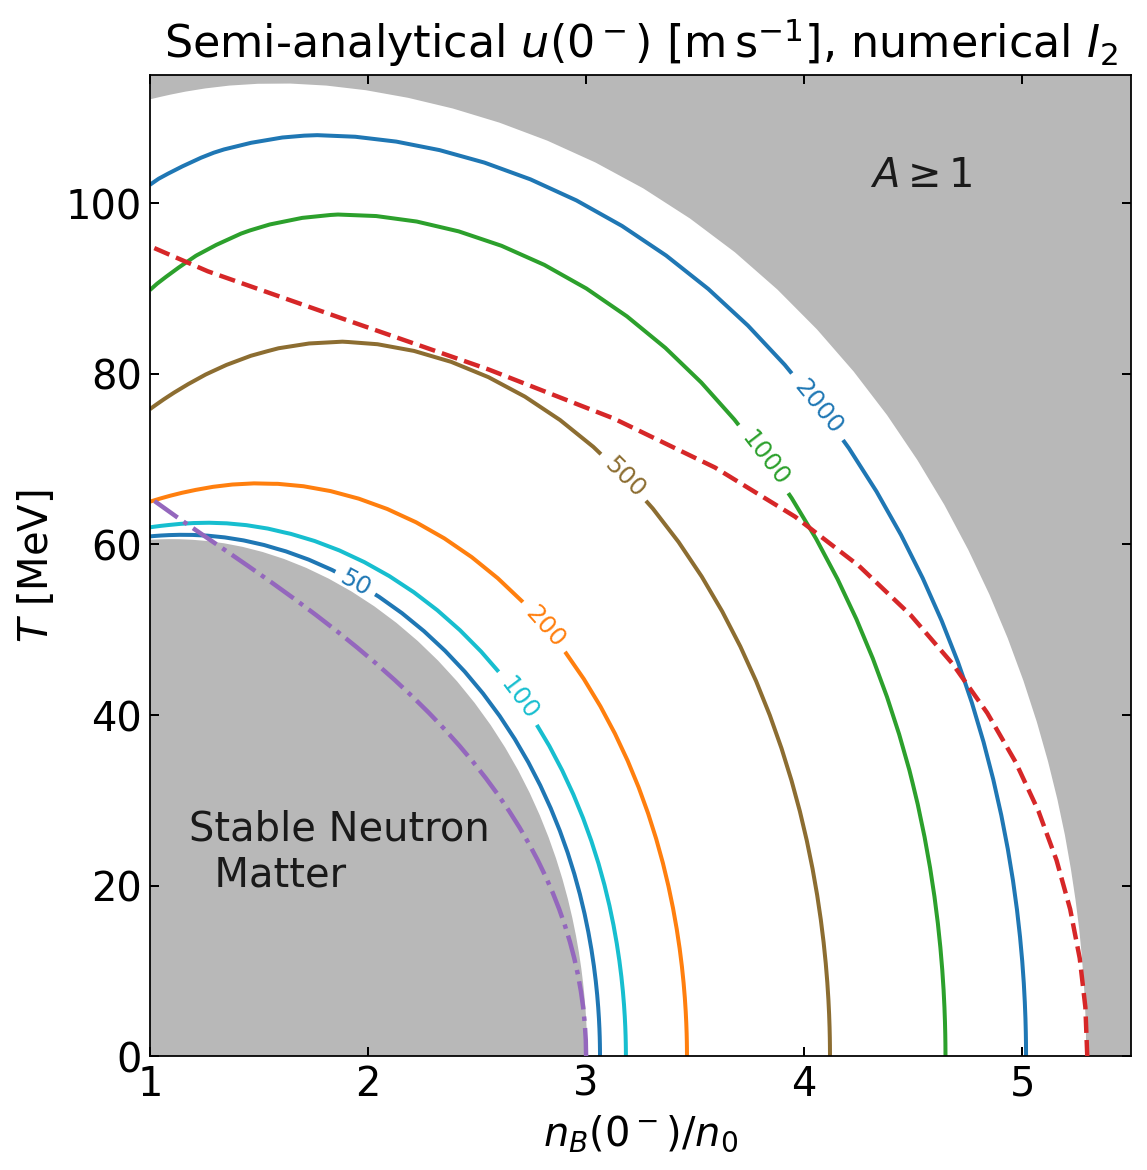

In [17]:
# Tunable plotting parameters
# Force-refreshed 2026-08-03: latest 26-08-02 numerical-I2 cluster payload
RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH = "new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy"
RAY_CONTOUR_FIGURE_SIZE = (7.2, 7.2)
RAY_CONTOUR_FIGURE_DPI = 160
RAY_CONTOUR_EXPORT_DPI = 220
RAY_CONTOUR_CONSTRAINED_LAYOUT = True
RAY_CONTOUR_BACKGROUND_COLOR = "white"
RAY_CONTOUR_X_LIMITS = (1.0, 5.5)
RAY_CONTOUR_Y_LIMITS_MEV = (0.0, 115.0)
RAY_CONTOUR_X_SCALE = "linear"
RAY_CONTOUR_Y_SCALE = "linear"
RAY_CONTOUR_BOX_ASPECT = 1.0
RAY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
RAY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c")
RAY_CONTOUR_LINE_WIDTH = 1.8
RAY_CONTOUR_LABEL_FONT_SIZE = 11
RAY_CONTOUR_LABEL_FORMAT = "%g"
RAY_CONTOUR_LABEL_INLINE = True
RAY_CONTOUR_LABEL_INLINE_SPACING = 4
RAY_CONTOUR_LINE_ZORDER = 2
RAY_CONTOUR_GAP_SHADE_COLOR = "0.72"
RAY_CONTOUR_A_SHADE_COLOR = "0.72"
RAY_CONTOUR_SHADE_ALPHA = 1.0
RAY_CONTOUR_SHADE_ZORDER = 0
RAY_CONTOUR_GAP_BOUNDARY_COLOR = "#d62728"
RAY_CONTOUR_GAP_BOUNDARY_STYLE = ":"
RAY_CONTOUR_GAP_BOUNDARY_WIDTH = 1.2
RAY_CONTOUR_A_BOUNDARY_COLOR = "0.35"
RAY_CONTOUR_A_BOUNDARY_STYLE = "--"
RAY_CONTOUR_A_BOUNDARY_WIDTH = 1.2
RAY_CONTOUR_BOUNDARY_ZORDER = 3
RAY_CONTOUR_CRITICAL_DENSITY_COLOR = "#9467bd"
RAY_CONTOUR_CRITICAL_DENSITY_LINE_STYLE = "-."
RAY_CONTOUR_CRITICAL_DENSITY_LINE_WIDTH = 2.0
RAY_CONTOUR_CRITICAL_DENSITY_LINE_ZORDER = 4
RAY_CONTOUR_UD_CRITICAL_COLOR = "#d62728"
RAY_CONTOUR_UD_CRITICAL_LINE_STYLE = "--"
RAY_CONTOUR_UD_CRITICAL_LINE_WIDTH = 2.0
RAY_CONTOUR_UD_CRITICAL_LINE_ZORDER = 4
RAY_CONTOUR_TITLE = r"Semi-analytical $u(0^-)$ [$\mathrm{m\,s^{-1}}$], numerical $I_2$"
RAY_CONTOUR_TITLE_FONT_SIZE = 20
RAY_CONTOUR_TITLE_PAD = 8
RAY_CONTOUR_X_LABEL = r"$n_B(0^-)/n_0$"
RAY_CONTOUR_Y_LABEL = r"$T$ [MeV]"
RAY_CONTOUR_AXIS_LABEL_FONT_SIZE = 18
RAY_CONTOUR_TICK_LABEL_FONT_SIZE = 18
RAY_CONTOUR_TICK_DIRECTION = "in"
RAY_CONTOUR_TICKS_TOP = True
RAY_CONTOUR_TICKS_RIGHT = True
RAY_CONTOUR_TICK_LENGTH = 4.0
RAY_CONTOUR_TICK_WIDTH = 0.9
RAY_CONTOUR_SPINE_LINE_WIDTH = 0.8
RAY_CONTOUR_A_TEXT = r"$A\geq 1$"
RAY_CONTOUR_A_TEXT_POSITION = (4.3, 102.0)
RAY_CONTOUR_GAP_TEXT = "Stable Neutron \n  Matter" #r"$\dfrac{h}{n_B}(0^-)\ne\dfrac{h}{n_B}(0^+)$"
RAY_CONTOUR_GAP_TEXT_POSITION = (1.18, 20.0)
RAY_CONTOUR_REGION_TEXT_COLOR = "0.10"
RAY_CONTOUR_REGION_TEXT_FONT_SIZE = 18
RAY_CONTOUR_TEXT_ZORDER = 4
RAY_CONTOUR_LEGEND_LOCATION = "lower right"
RAY_CONTOUR_LEGEND_FONT_SIZE = 14
RAY_CONTOUR_LEGEND_FRAME_ALPHA = 0.92
RAY_CONTOUR_OUTPUT_PNG = "local_analysis_results/26SU-9/analytic-uN-numerical-I2-absolute-density-contour.png"
RAY_CONTOUR_OUTPUT_PDF = "local_analysis_results/26SU-9/analytic-uN-numerical-I2-absolute-density-contour.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

ray_analytic_contour_root = Path.cwd()
ray_analytic_contour_payload_path = ray_analytic_contour_root / RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH
ray_analytic_contour_payload = np.load(
    ray_analytic_contour_payload_path,
    allow_pickle=True,
).item()
if ray_analytic_contour_payload.get("analytic_closure") != "hydro_jump_eigenvalue":
    raise RuntimeError(f"Expected analytical hydro-jump payload, got {ray_analytic_contour_payload.get('analytic_closure')!r}")
print(f"Using analytical contour payload: {ray_analytic_contour_payload_path}")

ray_density_grid = np.asarray(ray_analytic_contour_payload["nB_grid_over_n0"], dtype=float)
ray_temperature_grid = np.asarray(ray_analytic_contour_payload["temperature_grid_MeV"], dtype=float)
ray_velocity_grid = np.asarray(ray_analytic_contour_payload["velocity_grid_m_s"], dtype=float)
ray_gap_density = np.asarray(ray_analytic_contour_payload["gap_boundary_nB_over_n0"], dtype=float)
ray_gap_temperature = np.asarray(ray_analytic_contour_payload["gap_boundary_temperature_MeV"], dtype=float)
ray_A_density = np.asarray(ray_analytic_contour_payload["A_boundary_nB_over_n0"], dtype=float)
ray_A_temperature = np.asarray(ray_analytic_contour_payload["A_boundary_temperature_MeV"], dtype=float)
ray_has_A_boundary = bool(ray_A_density.size and ray_A_temperature.size)
ray_velocity_masked = np.ma.masked_invalid(ray_velocity_grid)

ray_figure, ray_axis = plt.subplots(
    figsize=RAY_CONTOUR_FIGURE_SIZE,
    dpi=RAY_CONTOUR_FIGURE_DPI,
    constrained_layout=RAY_CONTOUR_CONSTRAINED_LAYOUT,
    facecolor=RAY_CONTOUR_BACKGROUND_COLOR,
)
ray_axis.set_facecolor(RAY_CONTOUR_BACKGROUND_COLOR)
ray_gap_polygon_x = np.concatenate((
    ray_gap_density,
    (RAY_CONTOUR_X_LIMITS[0], ray_gap_density[0]),
))
ray_gap_polygon_y = np.concatenate((
    ray_gap_temperature,
    (RAY_CONTOUR_Y_LIMITS_MEV[0], RAY_CONTOUR_Y_LIMITS_MEV[0]),
))
ray_axis.fill(
    ray_gap_polygon_x,
    ray_gap_polygon_y,
    color=RAY_CONTOUR_GAP_SHADE_COLOR,
    alpha=RAY_CONTOUR_SHADE_ALPHA,
    zorder=RAY_CONTOUR_SHADE_ZORDER,
)
if ray_has_A_boundary:
    ray_A_polygon_x = np.concatenate((
        ray_A_density,
        (RAY_CONTOUR_X_LIMITS[0], RAY_CONTOUR_X_LIMITS[1], RAY_CONTOUR_X_LIMITS[1], ray_A_density[0]),
    ))
    ray_A_polygon_y = np.concatenate((
        ray_A_temperature,
        (RAY_CONTOUR_Y_LIMITS_MEV[1], RAY_CONTOUR_Y_LIMITS_MEV[1], RAY_CONTOUR_Y_LIMITS_MEV[0], RAY_CONTOUR_Y_LIMITS_MEV[0]),
    ))
    ray_axis.fill(
        ray_A_polygon_x,
        ray_A_polygon_y,
        color=RAY_CONTOUR_A_SHADE_COLOR,
        alpha=RAY_CONTOUR_SHADE_ALPHA,
        zorder=RAY_CONTOUR_SHADE_ZORDER,
    )

ray_contours = ray_axis.contour(
    ray_density_grid,
    ray_temperature_grid,
    ray_velocity_masked,
    levels=RAY_CONTOUR_LEVELS_M_S,
    colors=RAY_CONTOUR_COLORS,
    linewidths=RAY_CONTOUR_LINE_WIDTH,
    zorder=RAY_CONTOUR_LINE_ZORDER,
)
ray_axis.clabel(
    ray_contours,
    fontsize=RAY_CONTOUR_LABEL_FONT_SIZE,
    fmt=RAY_CONTOUR_LABEL_FORMAT,
    inline=RAY_CONTOUR_LABEL_INLINE,
    inline_spacing=RAY_CONTOUR_LABEL_INLINE_SPACING,
)
ray_axis.plot(
    ray_critical_density,
    ray_critical_temperature,
    color=RAY_CONTOUR_CRITICAL_DENSITY_COLOR,
    linestyle=RAY_CONTOUR_CRITICAL_DENSITY_LINE_STYLE,
    linewidth=RAY_CONTOUR_CRITICAL_DENSITY_LINE_WIDTH,
    zorder=RAY_CONTOUR_CRITICAL_DENSITY_LINE_ZORDER,
)
ray_axis.plot(
    ray_ud_critical_density,
    ray_ud_critical_temperature,
    color=RAY_CONTOUR_UD_CRITICAL_COLOR,
    linestyle=RAY_CONTOUR_UD_CRITICAL_LINE_STYLE,
    linewidth=RAY_CONTOUR_UD_CRITICAL_LINE_WIDTH,
    zorder=RAY_CONTOUR_UD_CRITICAL_LINE_ZORDER,
    label=r"$n_{B,\mathrm{crit}}^{N\leftrightarrow ud}(T)$",
)

if ray_has_A_boundary:
    ray_axis.text(
        *RAY_CONTOUR_A_TEXT_POSITION,
        RAY_CONTOUR_A_TEXT,
        color=RAY_CONTOUR_REGION_TEXT_COLOR,
        fontsize=RAY_CONTOUR_REGION_TEXT_FONT_SIZE,
        zorder=RAY_CONTOUR_TEXT_ZORDER,
    )
ray_axis.text(
    *RAY_CONTOUR_GAP_TEXT_POSITION,
    RAY_CONTOUR_GAP_TEXT,
    color=RAY_CONTOUR_REGION_TEXT_COLOR,
    fontsize=RAY_CONTOUR_REGION_TEXT_FONT_SIZE,
    zorder=RAY_CONTOUR_TEXT_ZORDER,
)
ray_axis.set_xlim(*RAY_CONTOUR_X_LIMITS)
ray_axis.set_ylim(*RAY_CONTOUR_Y_LIMITS_MEV)
ray_axis.set_xscale(RAY_CONTOUR_X_SCALE)
ray_axis.set_yscale(RAY_CONTOUR_Y_SCALE)
ray_axis.set_box_aspect(RAY_CONTOUR_BOX_ASPECT)
ray_axis.set_title(RAY_CONTOUR_TITLE, fontsize=RAY_CONTOUR_TITLE_FONT_SIZE, pad=RAY_CONTOUR_TITLE_PAD)
ray_axis.set_xlabel(RAY_CONTOUR_X_LABEL, fontsize=RAY_CONTOUR_AXIS_LABEL_FONT_SIZE)
ray_axis.set_ylabel(RAY_CONTOUR_Y_LABEL, fontsize=RAY_CONTOUR_AXIS_LABEL_FONT_SIZE)
ray_axis.tick_params(
    direction=RAY_CONTOUR_TICK_DIRECTION,
    top=RAY_CONTOUR_TICKS_TOP,
    right=RAY_CONTOUR_TICKS_RIGHT,
    length=RAY_CONTOUR_TICK_LENGTH,
    width=RAY_CONTOUR_TICK_WIDTH,
    labelsize=RAY_CONTOUR_TICK_LABEL_FONT_SIZE,
)
for ray_spine in ray_axis.spines.values():
    ray_spine.set_linewidth(RAY_CONTOUR_SPINE_LINE_WIDTH)
ray_legend_handles = [
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_GAP_BOUNDARY_COLOR, linestyle=RAY_CONTOUR_GAP_BOUNDARY_STYLE, linewidth=RAY_CONTOUR_GAP_BOUNDARY_WIDTH, label=r"$\Delta h=0$"),
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_A_BOUNDARY_COLOR, linestyle=RAY_CONTOUR_A_BOUNDARY_STYLE, linewidth=RAY_CONTOUR_A_BOUNDARY_WIDTH, label=r"$A=1$"),
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_CRITICAL_DENSITY_COLOR, linestyle=RAY_CONTOUR_CRITICAL_DENSITY_LINE_STYLE, linewidth=RAY_CONTOUR_CRITICAL_DENSITY_LINE_WIDTH, label=r"$n_B^{\mathrm{crit}}(T)$"),
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_UD_CRITICAL_COLOR, linestyle=RAY_CONTOUR_UD_CRITICAL_LINE_STYLE, linewidth=RAY_CONTOUR_UD_CRITICAL_LINE_WIDTH, label=r"$n_{B,\mathrm{crit}}^{N\leftrightarrow ud}(T)$"),
]


ray_output_png = ray_analytic_contour_root / RAY_CONTOUR_OUTPUT_PNG
ray_output_pdf = ray_analytic_contour_root / RAY_CONTOUR_OUTPUT_PDF
ray_output_png.parent.mkdir(parents=True, exist_ok=True)
ray_figure.savefig(ray_output_png, dpi=RAY_CONTOUR_EXPORT_DPI, facecolor=RAY_CONTOUR_BACKGROUND_COLOR)
ray_figure.savefig(ray_output_pdf, facecolor=RAY_CONTOUR_BACKGROUND_COLOR)
plt.show()


Using analytical contour payload: /Users/janshao/NSM_related/new_paper_calculations/26-07-24-2/analytic-uN-elliptical-ray-grid.npy


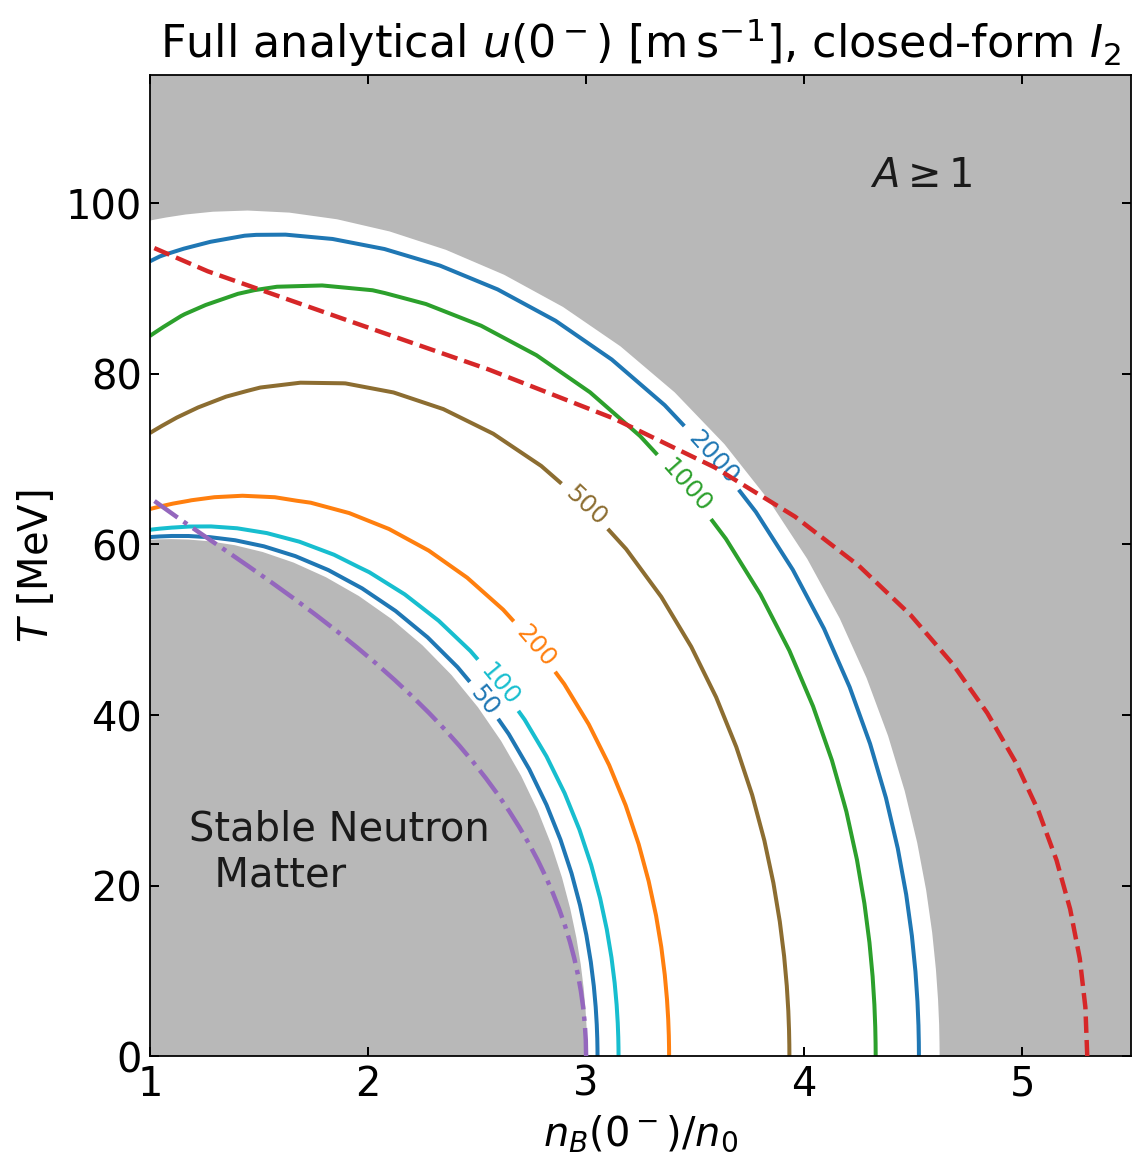

In [18]:
# Tunable plotting parameters
# Previous full analytical cluster payload with closed-form transport
RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH = "new_paper_calculations/26-07-24-2/analytic-uN-elliptical-ray-grid.npy"
RAY_CONTOUR_FIGURE_SIZE = (7.2, 7.2)
RAY_CONTOUR_FIGURE_DPI = 160
RAY_CONTOUR_EXPORT_DPI = 220
RAY_CONTOUR_CONSTRAINED_LAYOUT = True
RAY_CONTOUR_BACKGROUND_COLOR = "white"
RAY_CONTOUR_X_LIMITS = (1.0, 5.5)
RAY_CONTOUR_Y_LIMITS_MEV = (0.0, 115.0)
RAY_CONTOUR_X_SCALE = "linear"
RAY_CONTOUR_Y_SCALE = "linear"
RAY_CONTOUR_BOX_ASPECT = 1.0
RAY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
RAY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c")
RAY_CONTOUR_LINE_WIDTH = 1.8
RAY_CONTOUR_LABEL_FONT_SIZE = 11
RAY_CONTOUR_LABEL_FORMAT = "%g"
RAY_CONTOUR_LABEL_INLINE = True
RAY_CONTOUR_LABEL_INLINE_SPACING = 4
RAY_CONTOUR_LINE_ZORDER = 2
RAY_CONTOUR_GAP_SHADE_COLOR = "0.72"
RAY_CONTOUR_A_SHADE_COLOR = "0.72"
RAY_CONTOUR_SHADE_ALPHA = 1.0
RAY_CONTOUR_SHADE_ZORDER = 0
RAY_CONTOUR_GAP_BOUNDARY_COLOR = "#d62728"
RAY_CONTOUR_GAP_BOUNDARY_STYLE = ":"
RAY_CONTOUR_GAP_BOUNDARY_WIDTH = 1.2
RAY_CONTOUR_A_BOUNDARY_COLOR = "0.35"
RAY_CONTOUR_A_BOUNDARY_STYLE = "--"
RAY_CONTOUR_A_BOUNDARY_WIDTH = 1.2
RAY_CONTOUR_BOUNDARY_ZORDER = 3
RAY_CONTOUR_CRITICAL_DENSITY_COLOR = "#9467bd"
RAY_CONTOUR_CRITICAL_DENSITY_LINE_STYLE = "-."
RAY_CONTOUR_CRITICAL_DENSITY_LINE_WIDTH = 2.0
RAY_CONTOUR_CRITICAL_DENSITY_LINE_ZORDER = 4
RAY_CONTOUR_UD_CRITICAL_COLOR = "#d62728"
RAY_CONTOUR_UD_CRITICAL_LINE_STYLE = "--"
RAY_CONTOUR_UD_CRITICAL_LINE_WIDTH = 2.0
RAY_CONTOUR_UD_CRITICAL_LINE_ZORDER = 4
RAY_CONTOUR_TITLE = r"Full analytical $u(0^-)$ [$\mathrm{m\,s^{-1}}$], closed-form $I_2$"
RAY_CONTOUR_TITLE_FONT_SIZE = 20
RAY_CONTOUR_TITLE_PAD = 8
RAY_CONTOUR_X_LABEL = r"$n_B(0^-)/n_0$"
RAY_CONTOUR_Y_LABEL = r"$T$ [MeV]"
RAY_CONTOUR_AXIS_LABEL_FONT_SIZE = 18
RAY_CONTOUR_TICK_LABEL_FONT_SIZE = 18
RAY_CONTOUR_TICK_DIRECTION = "in"
RAY_CONTOUR_TICKS_TOP = True
RAY_CONTOUR_TICKS_RIGHT = True
RAY_CONTOUR_TICK_LENGTH = 4.0
RAY_CONTOUR_TICK_WIDTH = 0.9
RAY_CONTOUR_SPINE_LINE_WIDTH = 0.8
RAY_CONTOUR_A_TEXT = r"$A\geq 1$"
RAY_CONTOUR_A_TEXT_POSITION = (4.3, 102.0)
RAY_CONTOUR_GAP_TEXT = "Stable Neutron \n  Matter" #r"$\dfrac{h}{n_B}(0^-)\ne\dfrac{h}{n_B}(0^+)$"
RAY_CONTOUR_GAP_TEXT_POSITION = (1.18, 20.0)
RAY_CONTOUR_REGION_TEXT_COLOR = "0.10"
RAY_CONTOUR_REGION_TEXT_FONT_SIZE = 18
RAY_CONTOUR_TEXT_ZORDER = 4
RAY_CONTOUR_LEGEND_LOCATION = "lower right"
RAY_CONTOUR_LEGEND_FONT_SIZE = 14
RAY_CONTOUR_LEGEND_FRAME_ALPHA = 0.92
RAY_CONTOUR_OUTPUT_PNG = "local_analysis_results/26SU-9/analytic-uN-closed-form-I2-absolute-density-contour.png"
RAY_CONTOUR_OUTPUT_PDF = "local_analysis_results/26SU-9/analytic-uN-closed-form-I2-absolute-density-contour.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

ray_analytic_contour_root = Path.cwd()
ray_analytic_contour_payload_path = ray_analytic_contour_root / RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH
ray_analytic_contour_payload = np.load(
    ray_analytic_contour_payload_path,
    allow_pickle=True,
).item()
if ray_analytic_contour_payload.get("analytic_closure") != "hydro_jump_eigenvalue":
    raise RuntimeError(f"Expected analytical hydro-jump payload, got {ray_analytic_contour_payload.get('analytic_closure')!r}")
print(f"Using analytical contour payload: {ray_analytic_contour_payload_path}")

ray_density_grid = np.asarray(ray_analytic_contour_payload["nB_grid_over_n0"], dtype=float)
ray_temperature_grid = np.asarray(ray_analytic_contour_payload["temperature_grid_MeV"], dtype=float)
ray_velocity_grid = np.asarray(ray_analytic_contour_payload["velocity_grid_m_s"], dtype=float)
ray_gap_density = np.asarray(ray_analytic_contour_payload["gap_boundary_nB_over_n0"], dtype=float)
ray_gap_temperature = np.asarray(ray_analytic_contour_payload["gap_boundary_temperature_MeV"], dtype=float)
ray_A_density = np.asarray(ray_analytic_contour_payload["A_boundary_nB_over_n0"], dtype=float)
ray_A_temperature = np.asarray(ray_analytic_contour_payload["A_boundary_temperature_MeV"], dtype=float)
ray_has_A_boundary = bool(ray_A_density.size and ray_A_temperature.size)
ray_velocity_masked = np.ma.masked_invalid(ray_velocity_grid)

ray_figure, ray_axis = plt.subplots(
    figsize=RAY_CONTOUR_FIGURE_SIZE,
    dpi=RAY_CONTOUR_FIGURE_DPI,
    constrained_layout=RAY_CONTOUR_CONSTRAINED_LAYOUT,
    facecolor=RAY_CONTOUR_BACKGROUND_COLOR,
)
ray_axis.set_facecolor(RAY_CONTOUR_BACKGROUND_COLOR)
ray_gap_polygon_x = np.concatenate((
    ray_gap_density,
    (RAY_CONTOUR_X_LIMITS[0], ray_gap_density[0]),
))
ray_gap_polygon_y = np.concatenate((
    ray_gap_temperature,
    (RAY_CONTOUR_Y_LIMITS_MEV[0], RAY_CONTOUR_Y_LIMITS_MEV[0]),
))
ray_axis.fill(
    ray_gap_polygon_x,
    ray_gap_polygon_y,
    color=RAY_CONTOUR_GAP_SHADE_COLOR,
    alpha=RAY_CONTOUR_SHADE_ALPHA,
    zorder=RAY_CONTOUR_SHADE_ZORDER,
)
if ray_has_A_boundary:
    ray_A_polygon_x = np.concatenate((
        ray_A_density,
        (RAY_CONTOUR_X_LIMITS[0], RAY_CONTOUR_X_LIMITS[1], RAY_CONTOUR_X_LIMITS[1], ray_A_density[0]),
    ))
    ray_A_polygon_y = np.concatenate((
        ray_A_temperature,
        (RAY_CONTOUR_Y_LIMITS_MEV[1], RAY_CONTOUR_Y_LIMITS_MEV[1], RAY_CONTOUR_Y_LIMITS_MEV[0], RAY_CONTOUR_Y_LIMITS_MEV[0]),
    ))
    ray_axis.fill(
        ray_A_polygon_x,
        ray_A_polygon_y,
        color=RAY_CONTOUR_A_SHADE_COLOR,
        alpha=RAY_CONTOUR_SHADE_ALPHA,
        zorder=RAY_CONTOUR_SHADE_ZORDER,
    )

ray_contours = ray_axis.contour(
    ray_density_grid,
    ray_temperature_grid,
    ray_velocity_masked,
    levels=RAY_CONTOUR_LEVELS_M_S,
    colors=RAY_CONTOUR_COLORS,
    linewidths=RAY_CONTOUR_LINE_WIDTH,
    zorder=RAY_CONTOUR_LINE_ZORDER,
)
ray_axis.clabel(
    ray_contours,
    fontsize=RAY_CONTOUR_LABEL_FONT_SIZE,
    fmt=RAY_CONTOUR_LABEL_FORMAT,
    inline=RAY_CONTOUR_LABEL_INLINE,
    inline_spacing=RAY_CONTOUR_LABEL_INLINE_SPACING,
)
ray_axis.plot(
    ray_critical_density,
    ray_critical_temperature,
    color=RAY_CONTOUR_CRITICAL_DENSITY_COLOR,
    linestyle=RAY_CONTOUR_CRITICAL_DENSITY_LINE_STYLE,
    linewidth=RAY_CONTOUR_CRITICAL_DENSITY_LINE_WIDTH,
    zorder=RAY_CONTOUR_CRITICAL_DENSITY_LINE_ZORDER,
)
ray_axis.plot(
    ray_ud_critical_density,
    ray_ud_critical_temperature,
    color=RAY_CONTOUR_UD_CRITICAL_COLOR,
    linestyle=RAY_CONTOUR_UD_CRITICAL_LINE_STYLE,
    linewidth=RAY_CONTOUR_UD_CRITICAL_LINE_WIDTH,
    zorder=RAY_CONTOUR_UD_CRITICAL_LINE_ZORDER,
    label=r"$n_{B,\mathrm{crit}}^{N\leftrightarrow ud}(T)$",
)

if ray_has_A_boundary:
    ray_axis.text(
        *RAY_CONTOUR_A_TEXT_POSITION,
        RAY_CONTOUR_A_TEXT,
        color=RAY_CONTOUR_REGION_TEXT_COLOR,
        fontsize=RAY_CONTOUR_REGION_TEXT_FONT_SIZE,
        zorder=RAY_CONTOUR_TEXT_ZORDER,
    )
ray_axis.text(
    *RAY_CONTOUR_GAP_TEXT_POSITION,
    RAY_CONTOUR_GAP_TEXT,
    color=RAY_CONTOUR_REGION_TEXT_COLOR,
    fontsize=RAY_CONTOUR_REGION_TEXT_FONT_SIZE,
    zorder=RAY_CONTOUR_TEXT_ZORDER,
)
ray_axis.set_xlim(*RAY_CONTOUR_X_LIMITS)
ray_axis.set_ylim(*RAY_CONTOUR_Y_LIMITS_MEV)
ray_axis.set_xscale(RAY_CONTOUR_X_SCALE)
ray_axis.set_yscale(RAY_CONTOUR_Y_SCALE)
ray_axis.set_box_aspect(RAY_CONTOUR_BOX_ASPECT)
ray_axis.set_title(RAY_CONTOUR_TITLE, fontsize=RAY_CONTOUR_TITLE_FONT_SIZE, pad=RAY_CONTOUR_TITLE_PAD)
ray_axis.set_xlabel(RAY_CONTOUR_X_LABEL, fontsize=RAY_CONTOUR_AXIS_LABEL_FONT_SIZE)
ray_axis.set_ylabel(RAY_CONTOUR_Y_LABEL, fontsize=RAY_CONTOUR_AXIS_LABEL_FONT_SIZE)
ray_axis.tick_params(
    direction=RAY_CONTOUR_TICK_DIRECTION,
    top=RAY_CONTOUR_TICKS_TOP,
    right=RAY_CONTOUR_TICKS_RIGHT,
    length=RAY_CONTOUR_TICK_LENGTH,
    width=RAY_CONTOUR_TICK_WIDTH,
    labelsize=RAY_CONTOUR_TICK_LABEL_FONT_SIZE,
)
for ray_spine in ray_axis.spines.values():
    ray_spine.set_linewidth(RAY_CONTOUR_SPINE_LINE_WIDTH)
ray_legend_handles = [
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_GAP_BOUNDARY_COLOR, linestyle=RAY_CONTOUR_GAP_BOUNDARY_STYLE, linewidth=RAY_CONTOUR_GAP_BOUNDARY_WIDTH, label=r"$\Delta h=0$"),
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_A_BOUNDARY_COLOR, linestyle=RAY_CONTOUR_A_BOUNDARY_STYLE, linewidth=RAY_CONTOUR_A_BOUNDARY_WIDTH, label=r"$A=1$"),
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_CRITICAL_DENSITY_COLOR, linestyle=RAY_CONTOUR_CRITICAL_DENSITY_LINE_STYLE, linewidth=RAY_CONTOUR_CRITICAL_DENSITY_LINE_WIDTH, label=r"$n_B^{\mathrm{crit}}(T)$"),
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_UD_CRITICAL_COLOR, linestyle=RAY_CONTOUR_UD_CRITICAL_LINE_STYLE, linewidth=RAY_CONTOUR_UD_CRITICAL_LINE_WIDTH, label=r"$n_{B,\mathrm{crit}}^{N\leftrightarrow ud}(T)$"),
]


ray_output_png = ray_analytic_contour_root / RAY_CONTOUR_OUTPUT_PNG
ray_output_pdf = ray_analytic_contour_root / RAY_CONTOUR_OUTPUT_PDF
ray_output_png.parent.mkdir(parents=True, exist_ok=True)
ray_figure.savefig(ray_output_png, dpi=RAY_CONTOUR_EXPORT_DPI, facecolor=RAY_CONTOUR_BACKGROUND_COLOR)
ray_figure.savefig(ray_output_pdf, facecolor=RAY_CONTOUR_BACKGROUND_COLOR)
plt.show()


Using new_paper_calculations/26-07-25/uNmax-elliptical-ray-grid.npy: 600/600 finite cells
Using new_paper_calculations/26-07-24-2/analytic-uN-elliptical-ray-grid.npy: 600/600 finite cells


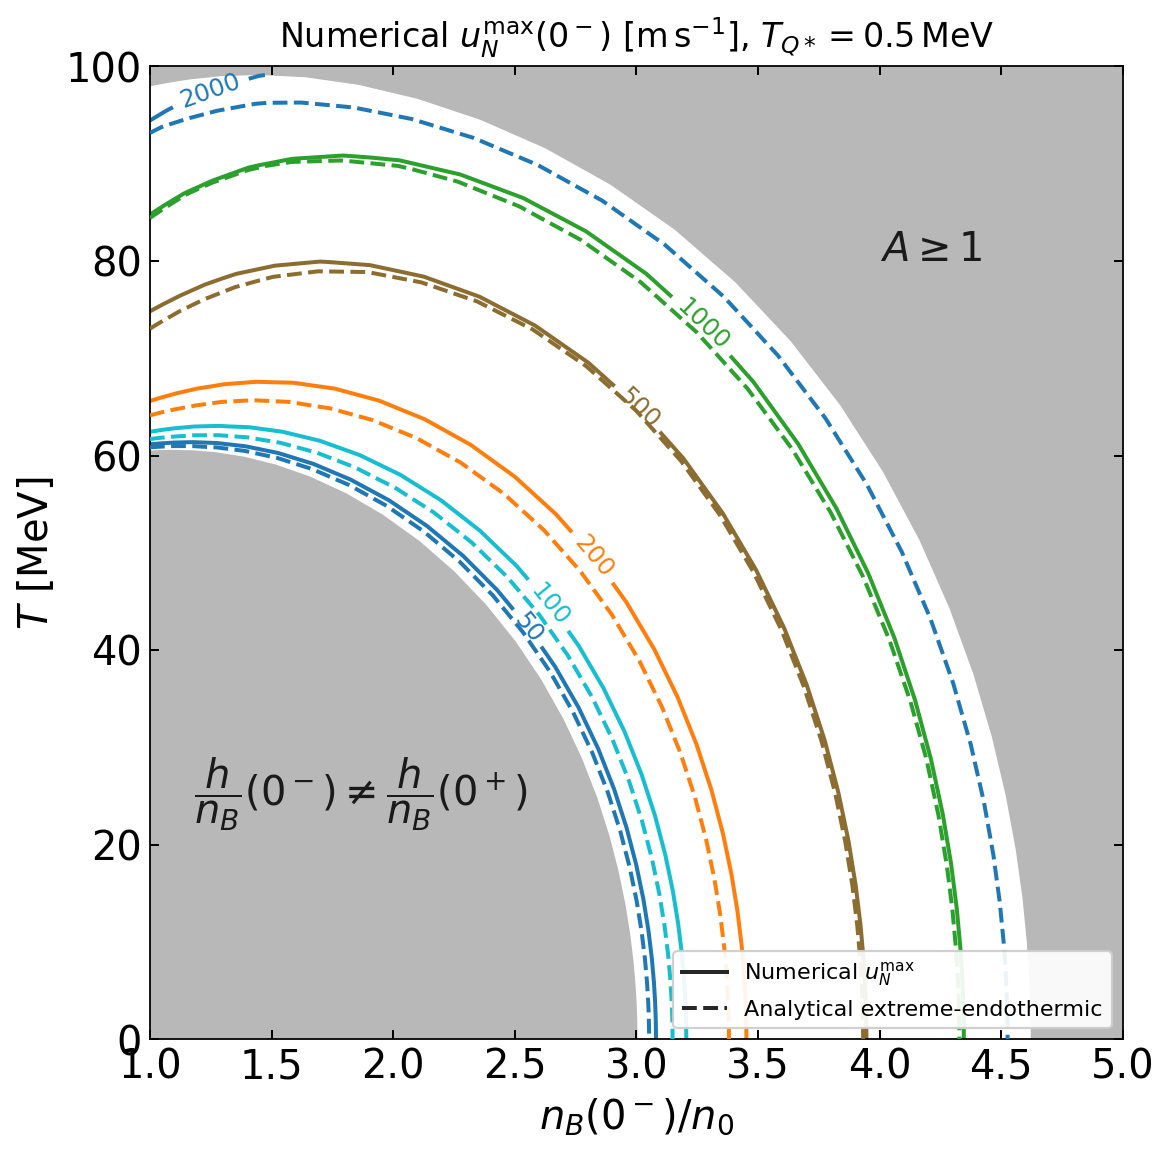

In [19]:
# Tunable plotting parameters
RAY_CONTOUR_CLUSTER_PAYLOAD_PATH = "new_paper_calculations/26-07-25/uNmax-elliptical-ray-grid.npy"
RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH = "new_paper_calculations/26-07-24-2/analytic-uN-elliptical-ray-grid.npy"
RAY_CONTOUR_FIGURE_SIZE = (7.2, 7.2)
RAY_CONTOUR_FIGURE_DPI = 160
RAY_CONTOUR_EXPORT_DPI = 220
RAY_CONTOUR_CONSTRAINED_LAYOUT = True
RAY_CONTOUR_BACKGROUND_COLOR = "white"
RAY_CONTOUR_X_LIMITS = (1.0, 5.0)
RAY_CONTOUR_Y_LIMITS_MEV = (0.0, 100.0)
RAY_CONTOUR_X_SCALE = "linear"
RAY_CONTOUR_Y_SCALE = "linear"
RAY_CONTOUR_BOX_ASPECT = 1.0
RAY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
RAY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c")
RAY_CONTOUR_LINE_WIDTH = 1.8
RAY_CONTOUR_LABEL_FONT_SIZE = 11
RAY_CONTOUR_LABEL_FORMAT = "%g"
RAY_CONTOUR_LABEL_INLINE = True
RAY_CONTOUR_LABEL_INLINE_SPACING = 4
RAY_CONTOUR_LINE_ZORDER = 2
RAY_CONTOUR_ANALYTIC_LINE_STYLE = "--"
RAY_CONTOUR_ANALYTIC_LINE_WIDTH = 1.8
RAY_CONTOUR_ANALYTIC_LINE_ALPHA = 1.0
RAY_CONTOUR_ANALYTIC_LINE_ZORDER = 3
RAY_CONTOUR_GAP_SHADE_COLOR = "0.72"
RAY_CONTOUR_A_SHADE_COLOR = "0.72"
RAY_CONTOUR_SHADE_ALPHA = 1.0
RAY_CONTOUR_SHADE_ZORDER = 0
RAY_CONTOUR_GAP_BOUNDARY_COLOR = "#d62728"
RAY_CONTOUR_GAP_BOUNDARY_STYLE = ":"
RAY_CONTOUR_GAP_BOUNDARY_WIDTH = 1.2
RAY_CONTOUR_A_BOUNDARY_COLOR = "0.35"
RAY_CONTOUR_A_BOUNDARY_STYLE = "--"
RAY_CONTOUR_A_BOUNDARY_WIDTH = 1.2
RAY_CONTOUR_BOUNDARY_ZORDER = 3
RAY_CONTOUR_TITLE = r"Numerical $u_N^{\max}(0^-)$ [$\mathrm{m\,s^{-1}}$], $T_{Q*}=0.5\,\mathrm{MeV}$"
RAY_CONTOUR_TITLE_FONT_SIZE = 15
RAY_CONTOUR_TITLE_PAD = 8
RAY_CONTOUR_X_LABEL = r"$n_B(0^-)/n_0$"
RAY_CONTOUR_Y_LABEL = r"$T$ [MeV]"
RAY_CONTOUR_AXIS_LABEL_FONT_SIZE = 18
RAY_CONTOUR_TICK_LABEL_FONT_SIZE = 18
RAY_CONTOUR_TICK_DIRECTION = "in"
RAY_CONTOUR_TICKS_TOP = True
RAY_CONTOUR_TICKS_RIGHT = True
RAY_CONTOUR_TICK_LENGTH = 4.0
RAY_CONTOUR_TICK_WIDTH = 0.9
RAY_CONTOUR_SPINE_LINE_WIDTH = 0.8
RAY_CONTOUR_A_TEXT = r"$A\geq 1$"
RAY_CONTOUR_A_TEXT_POSITION = (4.0, 80.0)
RAY_CONTOUR_GAP_TEXT = r"$\dfrac{h}{n_B}(0^-)\ne\dfrac{h}{n_B}(0^+)$"
RAY_CONTOUR_GAP_TEXT_POSITION = (1.18, 24.0)
RAY_CONTOUR_REGION_TEXT_COLOR = "0.10"
RAY_CONTOUR_REGION_TEXT_FONT_SIZE = 18
RAY_CONTOUR_TEXT_ZORDER = 4
RAY_CONTOUR_LEGEND_LOCATION = "lower right"
RAY_CONTOUR_LEGEND_FONT_SIZE = 10
RAY_CONTOUR_LEGEND_FRAME_ALPHA = 0.92
RAY_CONTOUR_LEGEND_LINE_COLOR = "0.15"
RAY_CONTOUR_OUTPUT_PNG = "local_analysis_results/26SU-9/numerical-vs-analytic-uNmax-TQstar0p5-absolute-density-contour.png"
RAY_CONTOUR_OUTPUT_PDF = "local_analysis_results/26SU-9/numerical-vs-analytic-uNmax-TQstar0p5-absolute-density-contour.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

RAY_CLUSTER_ROOT = Path.cwd()
ray_cluster_payload = np.load(
    RAY_CLUSTER_ROOT / RAY_CONTOUR_CLUSTER_PAYLOAD_PATH,
    allow_pickle=True,
).item()
ray_analytic_payload = np.load(
    RAY_CLUSTER_ROOT / RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH,
    allow_pickle=True,
).item()
print(
    f"Using {RAY_CONTOUR_CLUSTER_PAYLOAD_PATH}: "
    f"{np.count_nonzero(np.isfinite(ray_cluster_payload['velocity_grid_m_s']))}/"
    f"{np.asarray(ray_cluster_payload['velocity_grid_m_s']).size} finite cells"
)
print(
    f"Using {RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH}: "
    f"{np.count_nonzero(np.isfinite(ray_analytic_payload['velocity_grid_m_s']))}/"
    f"{np.asarray(ray_analytic_payload['velocity_grid_m_s']).size} finite cells"
)

ray_density_grid = np.asarray(ray_cluster_payload["nB_grid_over_n0"], dtype=float)
ray_temperature_grid = np.asarray(ray_cluster_payload["temperature_grid_MeV"], dtype=float)
ray_velocity_grid = np.asarray(ray_cluster_payload["velocity_grid_m_s"], dtype=float)
ray_gap_density = np.asarray(ray_cluster_payload["gap_boundary_nB_over_n0"], dtype=float)
ray_gap_temperature = np.asarray(ray_cluster_payload["gap_boundary_temperature_MeV"], dtype=float)
ray_A_density = np.asarray(ray_cluster_payload["A_boundary_nB_over_n0"], dtype=float)
ray_A_temperature = np.asarray(ray_cluster_payload["A_boundary_temperature_MeV"], dtype=float)
ray_velocity_masked = np.ma.masked_invalid(ray_velocity_grid)
ray_analytic_density_grid = np.asarray(ray_analytic_payload["nB_grid_over_n0"], dtype=float)
ray_analytic_temperature_grid = np.asarray(ray_analytic_payload["temperature_grid_MeV"], dtype=float)
ray_analytic_velocity_grid = np.asarray(ray_analytic_payload["velocity_grid_m_s"], dtype=float)
ray_analytic_velocity_masked = np.ma.masked_invalid(ray_analytic_velocity_grid)

ray_figure, ray_axis = plt.subplots(
    figsize=RAY_CONTOUR_FIGURE_SIZE,
    dpi=RAY_CONTOUR_FIGURE_DPI,
    constrained_layout=RAY_CONTOUR_CONSTRAINED_LAYOUT,
    facecolor=RAY_CONTOUR_BACKGROUND_COLOR,
)
ray_axis.set_facecolor(RAY_CONTOUR_BACKGROUND_COLOR)
ray_gap_polygon_x = np.concatenate((
    ray_gap_density,
    (RAY_CONTOUR_X_LIMITS[0], ray_gap_density[0]),
))
ray_gap_polygon_y = np.concatenate((
    ray_gap_temperature,
    (RAY_CONTOUR_Y_LIMITS_MEV[0], RAY_CONTOUR_Y_LIMITS_MEV[0]),
))
ray_axis.fill(
    ray_gap_polygon_x,
    ray_gap_polygon_y,
    color=RAY_CONTOUR_GAP_SHADE_COLOR,
    alpha=RAY_CONTOUR_SHADE_ALPHA,
    zorder=RAY_CONTOUR_SHADE_ZORDER,
)
ray_A_polygon_x = np.concatenate((
    ray_A_density,
    (RAY_CONTOUR_X_LIMITS[0], RAY_CONTOUR_X_LIMITS[1], RAY_CONTOUR_X_LIMITS[1], ray_A_density[0]),
))
ray_A_polygon_y = np.concatenate((
    ray_A_temperature,
    (RAY_CONTOUR_Y_LIMITS_MEV[1], RAY_CONTOUR_Y_LIMITS_MEV[1], RAY_CONTOUR_Y_LIMITS_MEV[0], RAY_CONTOUR_Y_LIMITS_MEV[0]),
))
ray_axis.fill(
    ray_A_polygon_x,
    ray_A_polygon_y,
    color=RAY_CONTOUR_A_SHADE_COLOR,
    alpha=RAY_CONTOUR_SHADE_ALPHA,
    zorder=RAY_CONTOUR_SHADE_ZORDER,
)
ray_contours = ray_axis.contour(
    ray_density_grid,
    ray_temperature_grid,
    ray_velocity_masked,
    levels=RAY_CONTOUR_LEVELS_M_S,
    colors=RAY_CONTOUR_COLORS,
    linewidths=RAY_CONTOUR_LINE_WIDTH,
    zorder=RAY_CONTOUR_LINE_ZORDER,
)
ray_axis.clabel(
    ray_contours,
    fontsize=RAY_CONTOUR_LABEL_FONT_SIZE,
    fmt=RAY_CONTOUR_LABEL_FORMAT,
    inline=RAY_CONTOUR_LABEL_INLINE,
    inline_spacing=RAY_CONTOUR_LABEL_INLINE_SPACING,
)
ray_analytic_contours = ray_axis.contour(
    ray_analytic_density_grid,
    ray_analytic_temperature_grid,
    ray_analytic_velocity_masked,
    levels=RAY_CONTOUR_LEVELS_M_S,
    colors=RAY_CONTOUR_COLORS,
    linewidths=RAY_CONTOUR_ANALYTIC_LINE_WIDTH,
    linestyles=RAY_CONTOUR_ANALYTIC_LINE_STYLE,
    alpha=RAY_CONTOUR_ANALYTIC_LINE_ALPHA,
    zorder=RAY_CONTOUR_ANALYTIC_LINE_ZORDER,
)

ray_axis.text(
    *RAY_CONTOUR_A_TEXT_POSITION,
    RAY_CONTOUR_A_TEXT,
    color=RAY_CONTOUR_REGION_TEXT_COLOR,
    fontsize=RAY_CONTOUR_REGION_TEXT_FONT_SIZE,
    zorder=RAY_CONTOUR_TEXT_ZORDER,
)
ray_axis.text(
    *RAY_CONTOUR_GAP_TEXT_POSITION,
    RAY_CONTOUR_GAP_TEXT,
    color=RAY_CONTOUR_REGION_TEXT_COLOR,
    fontsize=RAY_CONTOUR_REGION_TEXT_FONT_SIZE,
    zorder=RAY_CONTOUR_TEXT_ZORDER,
)
ray_axis.set_xlim(*RAY_CONTOUR_X_LIMITS)
ray_axis.set_ylim(*RAY_CONTOUR_Y_LIMITS_MEV)
ray_axis.set_xscale(RAY_CONTOUR_X_SCALE)
ray_axis.set_yscale(RAY_CONTOUR_Y_SCALE)
ray_axis.set_box_aspect(RAY_CONTOUR_BOX_ASPECT)
ray_axis.set_title(RAY_CONTOUR_TITLE, fontsize=RAY_CONTOUR_TITLE_FONT_SIZE, pad=RAY_CONTOUR_TITLE_PAD)
ray_axis.set_xlabel(RAY_CONTOUR_X_LABEL, fontsize=RAY_CONTOUR_AXIS_LABEL_FONT_SIZE)
ray_axis.set_ylabel(RAY_CONTOUR_Y_LABEL, fontsize=RAY_CONTOUR_AXIS_LABEL_FONT_SIZE)
ray_axis.tick_params(
    direction=RAY_CONTOUR_TICK_DIRECTION,
    top=RAY_CONTOUR_TICKS_TOP,
    right=RAY_CONTOUR_TICKS_RIGHT,
    length=RAY_CONTOUR_TICK_LENGTH,
    width=RAY_CONTOUR_TICK_WIDTH,
    labelsize=RAY_CONTOUR_TICK_LABEL_FONT_SIZE,
)
for ray_spine in ray_axis.spines.values():
    ray_spine.set_linewidth(RAY_CONTOUR_SPINE_LINE_WIDTH)
ray_legend_handles = [
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_LEGEND_LINE_COLOR, linestyle="-", linewidth=RAY_CONTOUR_LINE_WIDTH, label=r"Numerical $u_N^{\max}$"),
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_LEGEND_LINE_COLOR, linestyle=RAY_CONTOUR_ANALYTIC_LINE_STYLE, linewidth=RAY_CONTOUR_ANALYTIC_LINE_WIDTH, label="Analytical extreme-endothermic"),
]
ray_axis.legend(
    handles=ray_legend_handles,
    loc=RAY_CONTOUR_LEGEND_LOCATION,
    fontsize=RAY_CONTOUR_LEGEND_FONT_SIZE,
    framealpha=RAY_CONTOUR_LEGEND_FRAME_ALPHA,
)

ray_output_png = RAY_CLUSTER_ROOT / RAY_CONTOUR_OUTPUT_PNG
ray_output_pdf = RAY_CLUSTER_ROOT / RAY_CONTOUR_OUTPUT_PDF
ray_output_png.parent.mkdir(parents=True, exist_ok=True)
ray_figure.savefig(ray_output_png, dpi=RAY_CONTOUR_EXPORT_DPI, facecolor=RAY_CONTOUR_BACKGROUND_COLOR)
ray_figure.savefig(ray_output_pdf, facecolor=RAY_CONTOUR_BACKGROUND_COLOR)
plt.show()


Using new_paper_calculations/26-08-03/uNmax-T-nB-ray-grid-full-profile-continuation.npy: 352/600 finite cells
Using new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy: 1350/1350 finite cells


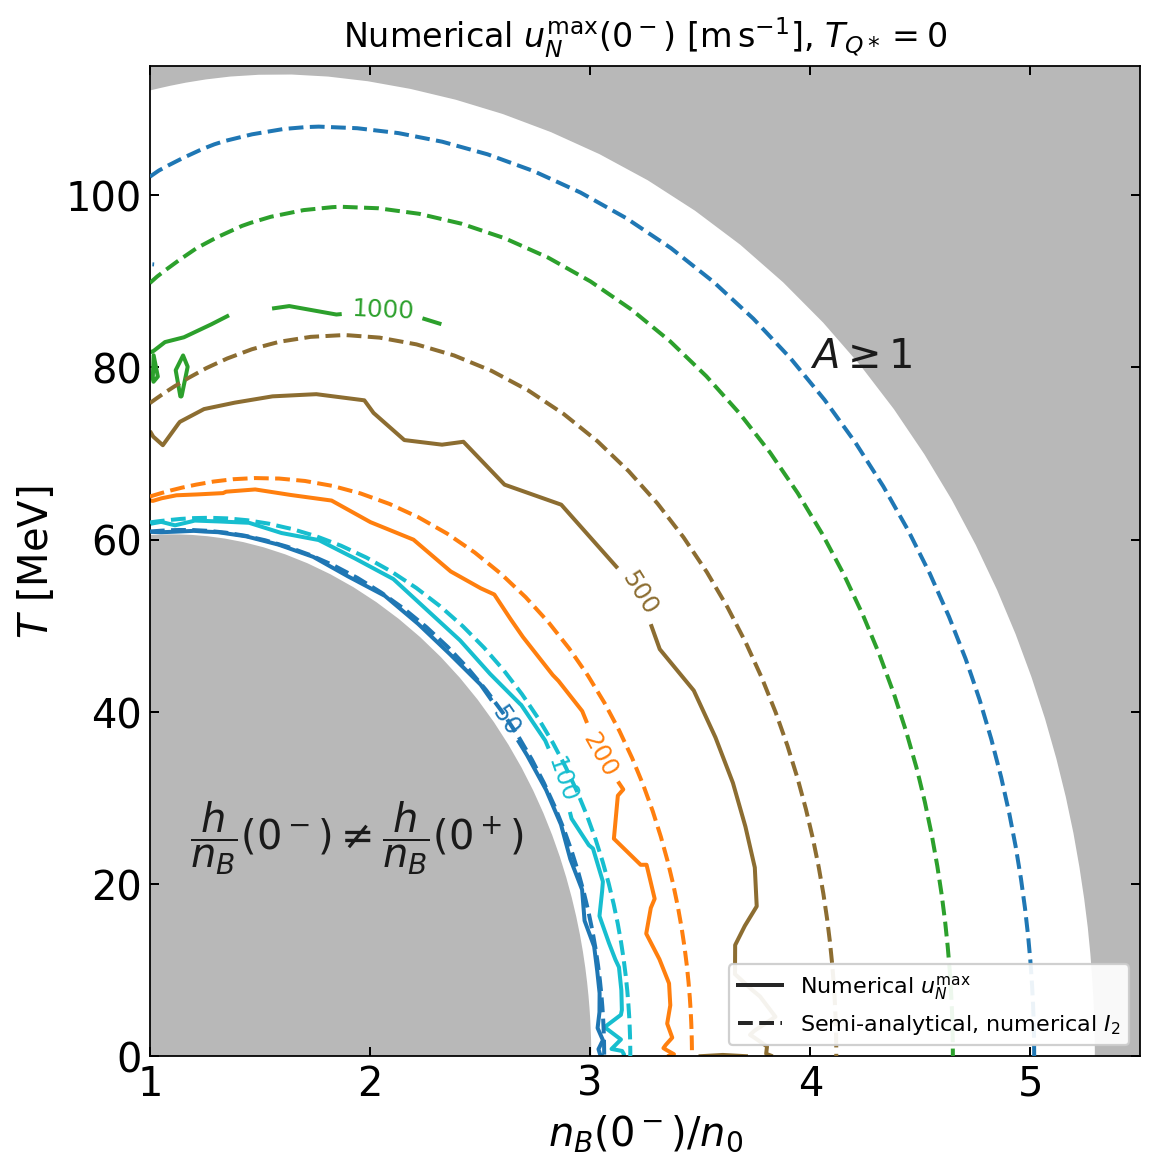

In [20]:
# Tunable plotting parameters
RAY_CONTOUR_CLUSTER_PAYLOAD_PATH = "new_paper_calculations/26-08-03/uNmax-T-nB-ray-grid-full-profile-continuation.npy"
RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH = "new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy"
RAY_CONTOUR_FIGURE_SIZE = (7.2, 7.2)
RAY_CONTOUR_FIGURE_DPI = 160
RAY_CONTOUR_EXPORT_DPI = 220
RAY_CONTOUR_CONSTRAINED_LAYOUT = True
RAY_CONTOUR_BACKGROUND_COLOR = "white"
RAY_CONTOUR_X_LIMITS = (1.0, 5.5)
RAY_CONTOUR_Y_LIMITS_MEV = (0.0, 115.0)
RAY_CONTOUR_X_SCALE = "linear"
RAY_CONTOUR_Y_SCALE = "linear"
RAY_CONTOUR_BOX_ASPECT = 1.0
RAY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
RAY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c")
RAY_CONTOUR_LINE_WIDTH = 1.8
RAY_CONTOUR_LABEL_FONT_SIZE = 11
RAY_CONTOUR_LABEL_FORMAT = "%g"
RAY_CONTOUR_LABEL_INLINE = True
RAY_CONTOUR_LABEL_INLINE_SPACING = 4
RAY_CONTOUR_LINE_ZORDER = 2
RAY_CONTOUR_ANALYTIC_LINE_STYLE = "--"
RAY_CONTOUR_ANALYTIC_LINE_WIDTH = 1.8
RAY_CONTOUR_ANALYTIC_LINE_ALPHA = 1.0
RAY_CONTOUR_ANALYTIC_LINE_ZORDER = 3
RAY_CONTOUR_GAP_SHADE_COLOR = "0.72"
RAY_CONTOUR_A_SHADE_COLOR = "0.72"
RAY_CONTOUR_SHADE_ALPHA = 1.0
RAY_CONTOUR_SHADE_ZORDER = 0
RAY_CONTOUR_GAP_BOUNDARY_COLOR = "#d62728"
RAY_CONTOUR_GAP_BOUNDARY_STYLE = ":"
RAY_CONTOUR_GAP_BOUNDARY_WIDTH = 1.2
RAY_CONTOUR_A_BOUNDARY_COLOR = "0.35"
RAY_CONTOUR_A_BOUNDARY_STYLE = "--"
RAY_CONTOUR_A_BOUNDARY_WIDTH = 1.2
RAY_CONTOUR_BOUNDARY_ZORDER = 3
RAY_CONTOUR_TITLE = r"Numerical $u_N^{\max}(0^-)$ [$\mathrm{m\,s^{-1}}$], $T_{Q*}=0$"
RAY_CONTOUR_TITLE_FONT_SIZE = 15
RAY_CONTOUR_TITLE_PAD = 8
RAY_CONTOUR_X_LABEL = r"$n_B(0^-)/n_0$"
RAY_CONTOUR_Y_LABEL = r"$T$ [MeV]"
RAY_CONTOUR_AXIS_LABEL_FONT_SIZE = 18
RAY_CONTOUR_TICK_LABEL_FONT_SIZE = 18
RAY_CONTOUR_TICK_DIRECTION = "in"
RAY_CONTOUR_TICKS_TOP = True
RAY_CONTOUR_TICKS_RIGHT = True
RAY_CONTOUR_TICK_LENGTH = 4.0
RAY_CONTOUR_TICK_WIDTH = 0.9
RAY_CONTOUR_SPINE_LINE_WIDTH = 0.8
RAY_CONTOUR_A_TEXT = r"$A\geq 1$"
RAY_CONTOUR_A_TEXT_POSITION = (4.0, 80.0)
RAY_CONTOUR_GAP_TEXT = r"$\dfrac{h}{n_B}(0^-)\ne\dfrac{h}{n_B}(0^+)$"
RAY_CONTOUR_GAP_TEXT_POSITION = (1.18, 24.0)
RAY_CONTOUR_REGION_TEXT_COLOR = "0.10"
RAY_CONTOUR_REGION_TEXT_FONT_SIZE = 18
RAY_CONTOUR_TEXT_ZORDER = 4
RAY_CONTOUR_LEGEND_LOCATION = "lower right"
RAY_CONTOUR_LEGEND_FONT_SIZE = 10
RAY_CONTOUR_LEGEND_FRAME_ALPHA = 0.92
RAY_CONTOUR_LEGEND_LINE_COLOR = "0.15"
RAY_CONTOUR_OUTPUT_PNG = "local_analysis_results/26SU-9/numerical-vs-semi-analytical-uNmax-exact-TQstar0-absolute-density-contour.png"
RAY_CONTOUR_OUTPUT_PDF = "local_analysis_results/26SU-9/numerical-vs-semi-analytical-uNmax-exact-TQstar0-absolute-density-contour.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

RAY_CLUSTER_ROOT = Path.cwd()
ray_cluster_payload = np.load(
    RAY_CLUSTER_ROOT / RAY_CONTOUR_CLUSTER_PAYLOAD_PATH,
    allow_pickle=True,
).item()
ray_analytic_payload = np.load(
    RAY_CLUSTER_ROOT / RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH,
    allow_pickle=True,
).item()
if not np.isclose(float(ray_cluster_payload.get("arguments", {}).get("TQstar", np.nan)), 0.0):
    raise RuntimeError("Expected the exact TQstar=0 numerical payload")
print(
    f"Using {RAY_CONTOUR_CLUSTER_PAYLOAD_PATH}: "
    f"{np.count_nonzero(np.isfinite(ray_cluster_payload['velocity_grid_m_s']))}/"
    f"{np.asarray(ray_cluster_payload['velocity_grid_m_s']).size} finite cells"
)
print(
    f"Using {RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH}: "
    f"{np.count_nonzero(np.isfinite(ray_analytic_payload['velocity_grid_m_s']))}/"
    f"{np.asarray(ray_analytic_payload['velocity_grid_m_s']).size} finite cells"
)

ray_density_grid = np.asarray(ray_cluster_payload["nB_grid_over_n0"], dtype=float)
ray_temperature_grid = np.asarray(ray_cluster_payload["temperature_grid_MeV"], dtype=float)
ray_velocity_grid = np.asarray(ray_cluster_payload["velocity_grid_m_s"], dtype=float)
ray_gap_density = np.asarray(ray_cluster_payload["gap_boundary_nB_over_n0"], dtype=float)
ray_gap_temperature = np.asarray(ray_cluster_payload["gap_boundary_temperature_MeV"], dtype=float)
ray_A_density = np.asarray(ray_cluster_payload["A_boundary_nB_over_n0"], dtype=float)
ray_A_temperature = np.asarray(ray_cluster_payload["A_boundary_temperature_MeV"], dtype=float)
ray_velocity_masked = np.ma.masked_invalid(ray_velocity_grid)
ray_analytic_density_grid = np.asarray(ray_analytic_payload["nB_grid_over_n0"], dtype=float)
ray_analytic_temperature_grid = np.asarray(ray_analytic_payload["temperature_grid_MeV"], dtype=float)
ray_analytic_velocity_grid = np.asarray(ray_analytic_payload["velocity_grid_m_s"], dtype=float)
ray_analytic_velocity_masked = np.ma.masked_invalid(ray_analytic_velocity_grid)

ray_figure, ray_axis = plt.subplots(
    figsize=RAY_CONTOUR_FIGURE_SIZE,
    dpi=RAY_CONTOUR_FIGURE_DPI,
    constrained_layout=RAY_CONTOUR_CONSTRAINED_LAYOUT,
    facecolor=RAY_CONTOUR_BACKGROUND_COLOR,
)
ray_axis.set_facecolor(RAY_CONTOUR_BACKGROUND_COLOR)
ray_gap_polygon_x = np.concatenate((
    ray_gap_density,
    (RAY_CONTOUR_X_LIMITS[0], ray_gap_density[0]),
))
ray_gap_polygon_y = np.concatenate((
    ray_gap_temperature,
    (RAY_CONTOUR_Y_LIMITS_MEV[0], RAY_CONTOUR_Y_LIMITS_MEV[0]),
))
ray_axis.fill(
    ray_gap_polygon_x,
    ray_gap_polygon_y,
    color=RAY_CONTOUR_GAP_SHADE_COLOR,
    alpha=RAY_CONTOUR_SHADE_ALPHA,
    zorder=RAY_CONTOUR_SHADE_ZORDER,
)
ray_A_polygon_x = np.concatenate((
    ray_A_density,
    (RAY_CONTOUR_X_LIMITS[0], RAY_CONTOUR_X_LIMITS[1], RAY_CONTOUR_X_LIMITS[1], ray_A_density[0]),
))
ray_A_polygon_y = np.concatenate((
    ray_A_temperature,
    (RAY_CONTOUR_Y_LIMITS_MEV[1], RAY_CONTOUR_Y_LIMITS_MEV[1], RAY_CONTOUR_Y_LIMITS_MEV[0], RAY_CONTOUR_Y_LIMITS_MEV[0]),
))
ray_axis.fill(
    ray_A_polygon_x,
    ray_A_polygon_y,
    color=RAY_CONTOUR_A_SHADE_COLOR,
    alpha=RAY_CONTOUR_SHADE_ALPHA,
    zorder=RAY_CONTOUR_SHADE_ZORDER,
)
ray_contours = ray_axis.contour(
    ray_density_grid,
    ray_temperature_grid,
    ray_velocity_masked,
    levels=RAY_CONTOUR_LEVELS_M_S,
    colors=RAY_CONTOUR_COLORS,
    linewidths=RAY_CONTOUR_LINE_WIDTH,
    zorder=RAY_CONTOUR_LINE_ZORDER,
)
ray_axis.clabel(
    ray_contours,
    fontsize=RAY_CONTOUR_LABEL_FONT_SIZE,
    fmt=RAY_CONTOUR_LABEL_FORMAT,
    inline=RAY_CONTOUR_LABEL_INLINE,
    inline_spacing=RAY_CONTOUR_LABEL_INLINE_SPACING,
)
ray_analytic_contours = ray_axis.contour(
    ray_analytic_density_grid,
    ray_analytic_temperature_grid,
    ray_analytic_velocity_masked,
    levels=RAY_CONTOUR_LEVELS_M_S,
    colors=RAY_CONTOUR_COLORS,
    linewidths=RAY_CONTOUR_ANALYTIC_LINE_WIDTH,
    linestyles=RAY_CONTOUR_ANALYTIC_LINE_STYLE,
    alpha=RAY_CONTOUR_ANALYTIC_LINE_ALPHA,
    zorder=RAY_CONTOUR_ANALYTIC_LINE_ZORDER,
)

ray_axis.text(
    *RAY_CONTOUR_A_TEXT_POSITION,
    RAY_CONTOUR_A_TEXT,
    color=RAY_CONTOUR_REGION_TEXT_COLOR,
    fontsize=RAY_CONTOUR_REGION_TEXT_FONT_SIZE,
    zorder=RAY_CONTOUR_TEXT_ZORDER,
)
ray_axis.text(
    *RAY_CONTOUR_GAP_TEXT_POSITION,
    RAY_CONTOUR_GAP_TEXT,
    color=RAY_CONTOUR_REGION_TEXT_COLOR,
    fontsize=RAY_CONTOUR_REGION_TEXT_FONT_SIZE,
    zorder=RAY_CONTOUR_TEXT_ZORDER,
)
ray_axis.set_xlim(*RAY_CONTOUR_X_LIMITS)
ray_axis.set_ylim(*RAY_CONTOUR_Y_LIMITS_MEV)
ray_axis.set_xscale(RAY_CONTOUR_X_SCALE)
ray_axis.set_yscale(RAY_CONTOUR_Y_SCALE)
ray_axis.set_box_aspect(RAY_CONTOUR_BOX_ASPECT)
ray_axis.set_title(RAY_CONTOUR_TITLE, fontsize=RAY_CONTOUR_TITLE_FONT_SIZE, pad=RAY_CONTOUR_TITLE_PAD)
ray_axis.set_xlabel(RAY_CONTOUR_X_LABEL, fontsize=RAY_CONTOUR_AXIS_LABEL_FONT_SIZE)
ray_axis.set_ylabel(RAY_CONTOUR_Y_LABEL, fontsize=RAY_CONTOUR_AXIS_LABEL_FONT_SIZE)
ray_axis.tick_params(
    direction=RAY_CONTOUR_TICK_DIRECTION,
    top=RAY_CONTOUR_TICKS_TOP,
    right=RAY_CONTOUR_TICKS_RIGHT,
    length=RAY_CONTOUR_TICK_LENGTH,
    width=RAY_CONTOUR_TICK_WIDTH,
    labelsize=RAY_CONTOUR_TICK_LABEL_FONT_SIZE,
)
for ray_spine in ray_axis.spines.values():
    ray_spine.set_linewidth(RAY_CONTOUR_SPINE_LINE_WIDTH)
ray_legend_handles = [
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_LEGEND_LINE_COLOR, linestyle="-", linewidth=RAY_CONTOUR_LINE_WIDTH, label=r"Numerical $u_N^{\max}$"),
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_LEGEND_LINE_COLOR, linestyle=RAY_CONTOUR_ANALYTIC_LINE_STYLE, linewidth=RAY_CONTOUR_ANALYTIC_LINE_WIDTH, label=r"Semi-analytical, numerical $I_2$"),
]
ray_axis.legend(
    handles=ray_legend_handles,
    loc=RAY_CONTOUR_LEGEND_LOCATION,
    fontsize=RAY_CONTOUR_LEGEND_FONT_SIZE,
    framealpha=RAY_CONTOUR_LEGEND_FRAME_ALPHA,
)

ray_output_png = RAY_CLUSTER_ROOT / RAY_CONTOUR_OUTPUT_PNG
ray_output_pdf = RAY_CLUSTER_ROOT / RAY_CONTOUR_OUTPUT_PDF
ray_output_png.parent.mkdir(parents=True, exist_ok=True)
ray_figure.savefig(ray_output_png, dpi=RAY_CONTOUR_EXPORT_DPI, facecolor=RAY_CONTOUR_BACKGROUND_COLOR)
ray_figure.savefig(ray_output_pdf, facecolor=RAY_CONTOUR_BACKGROUND_COLOR)
plt.show()


26-07-24: 600 finite shared-window cells; max u=15274.429 m/s
26-08-02: 1094 finite shared-window cells; max u=22294.528 m/s


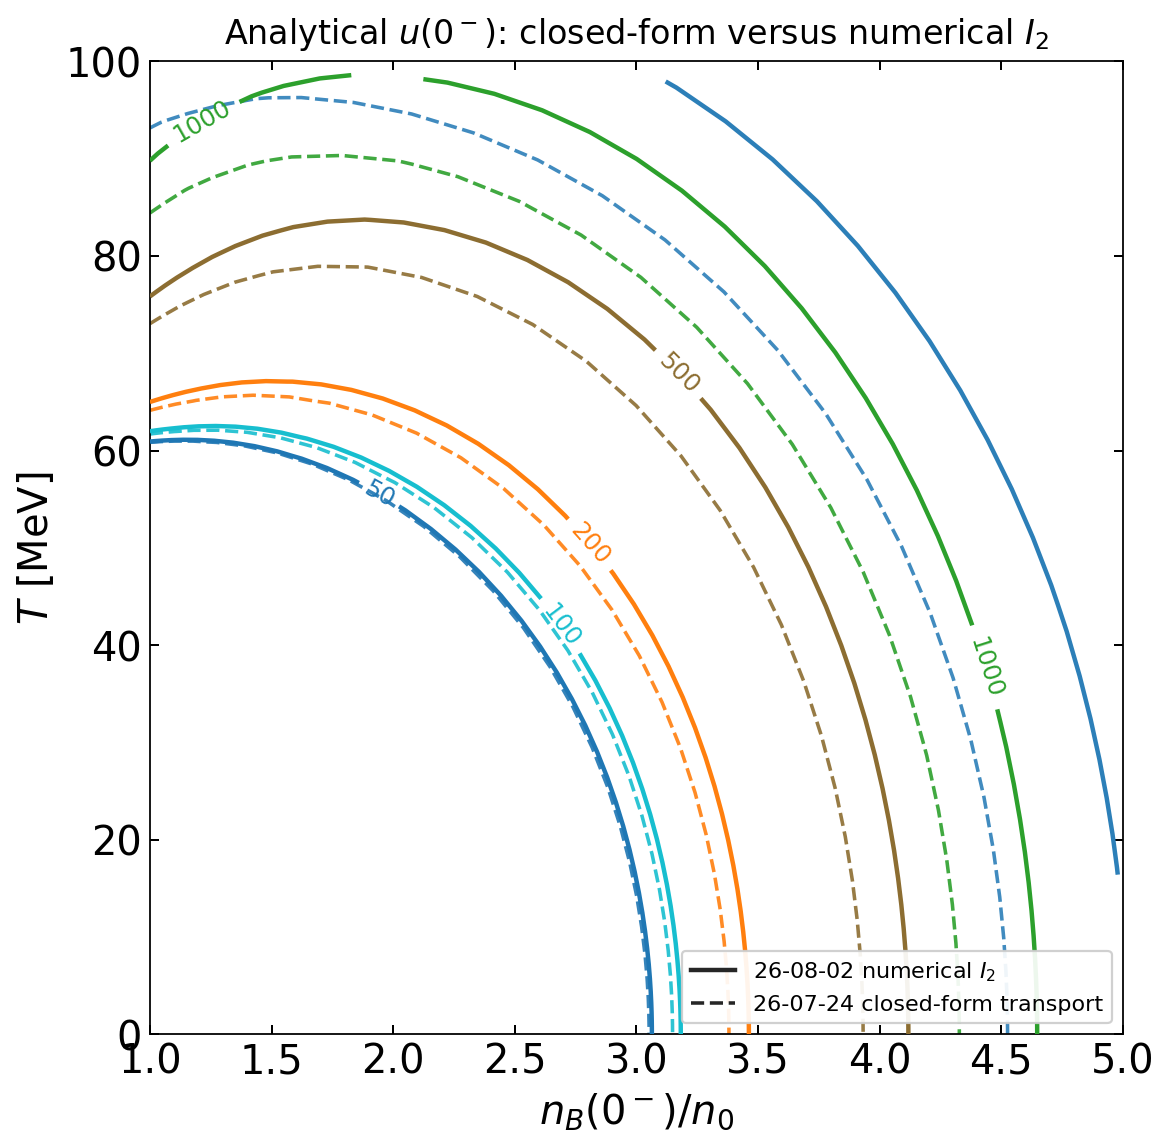

In [21]:
# Tunable plotting parameters
ANALYTIC_COMPARE_OLD_PAYLOAD_PATH = "new_paper_calculations/26-07-24/analytic-uN-elliptical-ray-grid.npy"
ANALYTIC_COMPARE_CURRENT_PAYLOAD_PATH = "new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy"
ANALYTIC_COMPARE_FIGURE_SIZE = (7.2, 7.2)
ANALYTIC_COMPARE_FIGURE_DPI = 160
ANALYTIC_COMPARE_EXPORT_DPI = 220
ANALYTIC_COMPARE_CONSTRAINED_LAYOUT = True
ANALYTIC_COMPARE_BACKGROUND_COLOR = "white"
ANALYTIC_COMPARE_X_LIMITS = (1.0, 5.0)
ANALYTIC_COMPARE_Y_LIMITS_MEV = (0.0, 100.0)
ANALYTIC_COMPARE_X_SCALE = "linear"
ANALYTIC_COMPARE_Y_SCALE = "linear"
ANALYTIC_COMPARE_BOX_ASPECT = 1.0
ANALYTIC_COMPARE_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
ANALYTIC_COMPARE_LABEL_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0)
ANALYTIC_COMPARE_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#2c7fb8")
ANALYTIC_COMPARE_CURRENT_LINE_STYLE = "-"
ANALYTIC_COMPARE_CURRENT_LINE_WIDTH = 2.0
ANALYTIC_COMPARE_CURRENT_LINE_ALPHA = 1.0
ANALYTIC_COMPARE_CURRENT_LINE_ZORDER = 3
ANALYTIC_COMPARE_OLD_LINE_STYLE = "--"
ANALYTIC_COMPARE_OLD_LINE_WIDTH = 1.6
ANALYTIC_COMPARE_OLD_LINE_ALPHA = 0.9
ANALYTIC_COMPARE_OLD_LINE_ZORDER = 2
ANALYTIC_COMPARE_LABEL_FONT_SIZE = 11
ANALYTIC_COMPARE_LABEL_FORMAT = "%g"
ANALYTIC_COMPARE_LABEL_INLINE = True
ANALYTIC_COMPARE_LABEL_INLINE_SPACING = 4
ANALYTIC_COMPARE_TITLE = r"Analytical $u(0^-)$: closed-form versus numerical $I_2$"
ANALYTIC_COMPARE_TITLE_FONT_SIZE = 15
ANALYTIC_COMPARE_TITLE_PAD = 8
ANALYTIC_COMPARE_X_LABEL = r"$n_B(0^-)/n_0$"
ANALYTIC_COMPARE_Y_LABEL = r"$T$ [MeV]"
ANALYTIC_COMPARE_AXIS_LABEL_FONT_SIZE = 18
ANALYTIC_COMPARE_TICK_LABEL_FONT_SIZE = 18
ANALYTIC_COMPARE_TICK_DIRECTION = "in"
ANALYTIC_COMPARE_TICKS_TOP = True
ANALYTIC_COMPARE_TICKS_RIGHT = True
ANALYTIC_COMPARE_TICK_LENGTH = 4.0
ANALYTIC_COMPARE_TICK_WIDTH = 0.9
ANALYTIC_COMPARE_SPINE_LINE_WIDTH = 0.8
ANALYTIC_COMPARE_LEGEND_LINE_COLOR = "0.15"
ANALYTIC_COMPARE_LEGEND_LOCATION = "lower right"
ANALYTIC_COMPARE_LEGEND_FONT_SIZE = 10
ANALYTIC_COMPARE_LEGEND_FRAME_ALPHA = 0.92
ANALYTIC_COMPARE_OUTPUT_PNG = "local_analysis_results/26SU-9/analytic-uN-closed-form-vs-numerical-I2.png"
ANALYTIC_COMPARE_OUTPUT_PDF = "local_analysis_results/26SU-9/analytic-uN-closed-form-vs-numerical-I2.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

analytic_compare_root = Path.cwd()
analytic_compare_old_path = analytic_compare_root / ANALYTIC_COMPARE_OLD_PAYLOAD_PATH
analytic_compare_current_path = analytic_compare_root / ANALYTIC_COMPARE_CURRENT_PAYLOAD_PATH
analytic_compare_old = np.load(analytic_compare_old_path, allow_pickle=True).item()
analytic_compare_current = np.load(analytic_compare_current_path, allow_pickle=True).item()

def analytic_compare_fields(payload):
    density = np.asarray(payload["nB_grid_over_n0"], dtype=float)
    temperature = np.asarray(payload["temperature_grid_MeV"], dtype=float)
    velocity = np.asarray(payload["velocity_grid_m_s"], dtype=float)
    inside_window = (
        np.isfinite(density)
        & np.isfinite(temperature)
        & np.isfinite(velocity)
        & (density >= ANALYTIC_COMPARE_X_LIMITS[0])
        & (density <= ANALYTIC_COMPARE_X_LIMITS[1])
        & (temperature >= ANALYTIC_COMPARE_Y_LIMITS_MEV[0])
        & (temperature <= ANALYTIC_COMPARE_Y_LIMITS_MEV[1])
    )
    return density, temperature, np.ma.masked_where(~inside_window, velocity), inside_window

analytic_compare_old_density, analytic_compare_old_temperature, analytic_compare_old_velocity, analytic_compare_old_mask = analytic_compare_fields(analytic_compare_old)
analytic_compare_current_density, analytic_compare_current_temperature, analytic_compare_current_velocity, analytic_compare_current_mask = analytic_compare_fields(analytic_compare_current)
print(f"26-07-24: {np.count_nonzero(analytic_compare_old_mask)} finite shared-window cells; max u={np.nanmax(np.where(analytic_compare_old_mask, np.asarray(analytic_compare_old['velocity_grid_m_s'], dtype=float), np.nan)):.3f} m/s")
print(f"26-08-02: {np.count_nonzero(analytic_compare_current_mask)} finite shared-window cells; max u={np.nanmax(np.where(analytic_compare_current_mask, np.asarray(analytic_compare_current['velocity_grid_m_s'], dtype=float), np.nan)):.3f} m/s")

analytic_compare_figure, analytic_compare_axis = plt.subplots(
    figsize=ANALYTIC_COMPARE_FIGURE_SIZE,
    dpi=ANALYTIC_COMPARE_FIGURE_DPI,
    constrained_layout=ANALYTIC_COMPARE_CONSTRAINED_LAYOUT,
    facecolor=ANALYTIC_COMPARE_BACKGROUND_COLOR,
)
analytic_compare_axis.set_facecolor(ANALYTIC_COMPARE_BACKGROUND_COLOR)
analytic_compare_old_contours = analytic_compare_axis.contour(
    analytic_compare_old_density,
    analytic_compare_old_temperature,
    analytic_compare_old_velocity,
    levels=ANALYTIC_COMPARE_LEVELS_M_S,
    colors=ANALYTIC_COMPARE_COLORS,
    linestyles=ANALYTIC_COMPARE_OLD_LINE_STYLE,
    linewidths=ANALYTIC_COMPARE_OLD_LINE_WIDTH,
    alpha=ANALYTIC_COMPARE_OLD_LINE_ALPHA,
    zorder=ANALYTIC_COMPARE_OLD_LINE_ZORDER,
)
analytic_compare_current_contours = analytic_compare_axis.contour(
    analytic_compare_current_density,
    analytic_compare_current_temperature,
    analytic_compare_current_velocity,
    levels=ANALYTIC_COMPARE_LEVELS_M_S,
    colors=ANALYTIC_COMPARE_COLORS,
    linestyles=ANALYTIC_COMPARE_CURRENT_LINE_STYLE,
    linewidths=ANALYTIC_COMPARE_CURRENT_LINE_WIDTH,
    alpha=ANALYTIC_COMPARE_CURRENT_LINE_ALPHA,
    zorder=ANALYTIC_COMPARE_CURRENT_LINE_ZORDER,
)
analytic_compare_axis.clabel(
    analytic_compare_current_contours,
    levels=ANALYTIC_COMPARE_LABEL_LEVELS_M_S,
    fontsize=ANALYTIC_COMPARE_LABEL_FONT_SIZE,
    fmt=ANALYTIC_COMPARE_LABEL_FORMAT,
    inline=ANALYTIC_COMPARE_LABEL_INLINE,
    inline_spacing=ANALYTIC_COMPARE_LABEL_INLINE_SPACING,
)
analytic_compare_axis.set_xlim(*ANALYTIC_COMPARE_X_LIMITS)
analytic_compare_axis.set_ylim(*ANALYTIC_COMPARE_Y_LIMITS_MEV)
analytic_compare_axis.set_xscale(ANALYTIC_COMPARE_X_SCALE)
analytic_compare_axis.set_yscale(ANALYTIC_COMPARE_Y_SCALE)
analytic_compare_axis.set_box_aspect(ANALYTIC_COMPARE_BOX_ASPECT)
analytic_compare_axis.set_title(ANALYTIC_COMPARE_TITLE, fontsize=ANALYTIC_COMPARE_TITLE_FONT_SIZE, pad=ANALYTIC_COMPARE_TITLE_PAD)
analytic_compare_axis.set_xlabel(ANALYTIC_COMPARE_X_LABEL, fontsize=ANALYTIC_COMPARE_AXIS_LABEL_FONT_SIZE)
analytic_compare_axis.set_ylabel(ANALYTIC_COMPARE_Y_LABEL, fontsize=ANALYTIC_COMPARE_AXIS_LABEL_FONT_SIZE)
analytic_compare_axis.tick_params(
    direction=ANALYTIC_COMPARE_TICK_DIRECTION,
    top=ANALYTIC_COMPARE_TICKS_TOP,
    right=ANALYTIC_COMPARE_TICKS_RIGHT,
    length=ANALYTIC_COMPARE_TICK_LENGTH,
    width=ANALYTIC_COMPARE_TICK_WIDTH,
    labelsize=ANALYTIC_COMPARE_TICK_LABEL_FONT_SIZE,
)
for analytic_compare_spine in analytic_compare_axis.spines.values():
    analytic_compare_spine.set_linewidth(ANALYTIC_COMPARE_SPINE_LINE_WIDTH)
analytic_compare_axis.legend(
    handles=(
        Line2D((0.0,), (0.0,), color=ANALYTIC_COMPARE_LEGEND_LINE_COLOR, linestyle=ANALYTIC_COMPARE_CURRENT_LINE_STYLE, linewidth=ANALYTIC_COMPARE_CURRENT_LINE_WIDTH, label=r"26-08-02 numerical $I_2$"),
        Line2D((0.0,), (0.0,), color=ANALYTIC_COMPARE_LEGEND_LINE_COLOR, linestyle=ANALYTIC_COMPARE_OLD_LINE_STYLE, linewidth=ANALYTIC_COMPARE_OLD_LINE_WIDTH, label=r"26-07-24 closed-form transport"),
    ),
    loc=ANALYTIC_COMPARE_LEGEND_LOCATION,
    fontsize=ANALYTIC_COMPARE_LEGEND_FONT_SIZE,
    framealpha=ANALYTIC_COMPARE_LEGEND_FRAME_ALPHA,
)
analytic_compare_output_png = analytic_compare_root / ANALYTIC_COMPARE_OUTPUT_PNG
analytic_compare_output_pdf = analytic_compare_root / ANALYTIC_COMPARE_OUTPUT_PDF
analytic_compare_output_png.parent.mkdir(parents=True, exist_ok=True)
analytic_compare_figure.savefig(analytic_compare_output_png, dpi=ANALYTIC_COMPARE_EXPORT_DPI, facecolor=ANALYTIC_COMPARE_BACKGROUND_COLOR)
analytic_compare_figure.savefig(analytic_compare_output_pdf, facecolor=ANALYTIC_COMPARE_BACKGROUND_COLOR)
plt.show()


Using semi-analytical payload: /Users/janshao/NSM_related/new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy
Using numerical payload: /Users/janshao/NSM_related/new_paper_calculations/26-08-04/uNmax-T-nB-ray-grid-TQstar-0p01-numerical-I2-seeded.npy
Finite numerical cells: 260/600


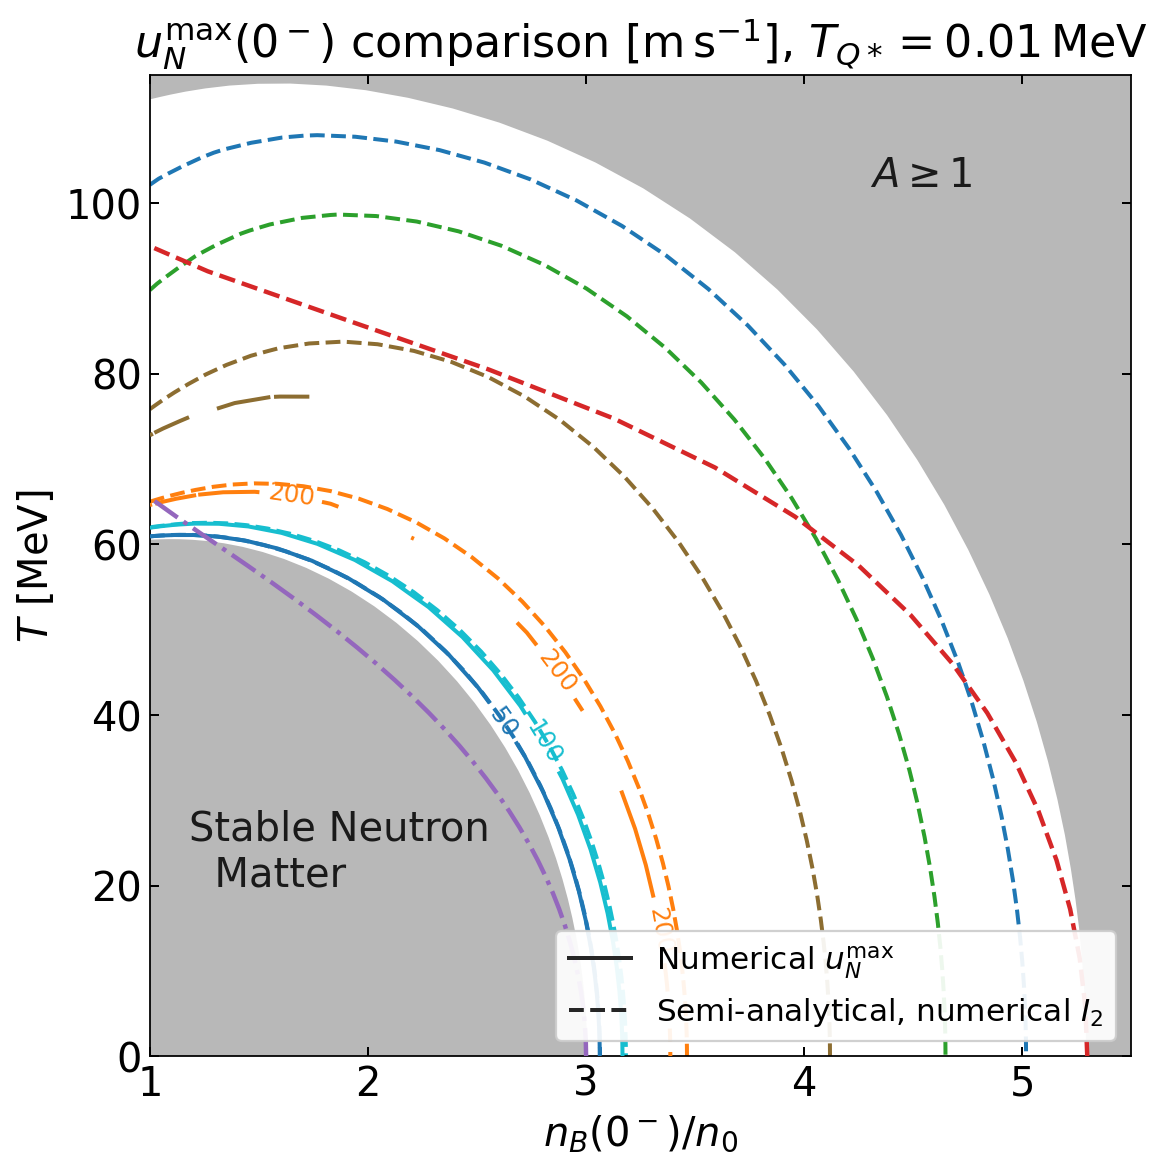

In [22]:
# Tunable plotting parameters
# Numerical uNmax overlaid on the state-of-the-art semi-analytical result
RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH = "new_paper_calculations/26-08-02/analytic-uN-T-nB-ray-grid-numerical-I2.npy"
RAY_CONTOUR_NUMERICAL_PAYLOAD_PATH = "new_paper_calculations/26-08-04/uNmax-T-nB-ray-grid-TQstar-0p01-numerical-I2-seeded.npy"
RAY_CONTOUR_FIGURE_SIZE = (7.2, 7.2)
RAY_CONTOUR_FIGURE_DPI = 160
RAY_CONTOUR_EXPORT_DPI = 220
RAY_CONTOUR_CONSTRAINED_LAYOUT = True
RAY_CONTOUR_BACKGROUND_COLOR = "white"
RAY_CONTOUR_X_LIMITS = (1.0, 5.5)
RAY_CONTOUR_Y_LIMITS_MEV = (0.0, 115.0)
RAY_CONTOUR_X_SCALE = "linear"
RAY_CONTOUR_Y_SCALE = "linear"
RAY_CONTOUR_BOX_ASPECT = 1.0
RAY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
RAY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c")
RAY_CONTOUR_LINE_WIDTH = 1.8
RAY_CONTOUR_NUMERICAL_LINE_STYLE = "-"
RAY_CONTOUR_SEMI_ANALYTICAL_LINE_STYLE = "--"
RAY_CONTOUR_LABEL_FONT_SIZE = 11
RAY_CONTOUR_LABEL_FORMAT = "%g"
RAY_CONTOUR_LABEL_INLINE = True
RAY_CONTOUR_LABEL_INLINE_SPACING = 4
RAY_CONTOUR_SEMI_ANALYTICAL_LINE_ZORDER = 2
RAY_CONTOUR_NUMERICAL_LINE_ZORDER = 3
RAY_CONTOUR_GAP_SHADE_COLOR = "0.72"
RAY_CONTOUR_A_SHADE_COLOR = "0.72"
RAY_CONTOUR_SHADE_ALPHA = 1.0
RAY_CONTOUR_SHADE_ZORDER = 0
RAY_CONTOUR_GAP_BOUNDARY_COLOR = "#d62728"
RAY_CONTOUR_GAP_BOUNDARY_STYLE = ":"
RAY_CONTOUR_GAP_BOUNDARY_WIDTH = 1.2
RAY_CONTOUR_A_BOUNDARY_COLOR = "0.35"
RAY_CONTOUR_A_BOUNDARY_STYLE = "--"
RAY_CONTOUR_A_BOUNDARY_WIDTH = 1.2
RAY_CONTOUR_BOUNDARY_ZORDER = 3
RAY_CONTOUR_CRITICAL_DENSITY_COLOR = "#9467bd"
RAY_CONTOUR_CRITICAL_DENSITY_LINE_STYLE = "-."
RAY_CONTOUR_CRITICAL_DENSITY_LINE_WIDTH = 2.0
RAY_CONTOUR_CRITICAL_DENSITY_LINE_ZORDER = 4
RAY_CONTOUR_UD_CRITICAL_COLOR = "#d62728"
RAY_CONTOUR_UD_CRITICAL_LINE_STYLE = "--"
RAY_CONTOUR_UD_CRITICAL_LINE_WIDTH = 2.0
RAY_CONTOUR_UD_CRITICAL_LINE_ZORDER = 4
RAY_CONTOUR_TITLE = r"$u_N^{\max}(0^-)$ comparison [$\mathrm{m\,s^{-1}}$], $T_{Q*}=0.01\,\mathrm{MeV}$"
RAY_CONTOUR_TITLE_FONT_SIZE = 20
RAY_CONTOUR_TITLE_PAD = 8
RAY_CONTOUR_X_LABEL = r"$n_B(0^-)/n_0$"
RAY_CONTOUR_Y_LABEL = r"$T$ [MeV]"
RAY_CONTOUR_AXIS_LABEL_FONT_SIZE = 18
RAY_CONTOUR_TICK_LABEL_FONT_SIZE = 18
RAY_CONTOUR_TICK_DIRECTION = "in"
RAY_CONTOUR_TICKS_TOP = True
RAY_CONTOUR_TICKS_RIGHT = True
RAY_CONTOUR_TICK_LENGTH = 4.0
RAY_CONTOUR_TICK_WIDTH = 0.9
RAY_CONTOUR_SPINE_LINE_WIDTH = 0.8
RAY_CONTOUR_A_TEXT = r"$A\geq 1$"
RAY_CONTOUR_A_TEXT_POSITION = (4.3, 102.0)
RAY_CONTOUR_GAP_TEXT = "Stable Neutron \n  Matter" #r"$\dfrac{h}{n_B}(0^-)\ne\dfrac{h}{n_B}(0^+)$"
RAY_CONTOUR_GAP_TEXT_POSITION = (1.18, 20.0)
RAY_CONTOUR_REGION_TEXT_COLOR = "0.10"
RAY_CONTOUR_REGION_TEXT_FONT_SIZE = 18
RAY_CONTOUR_TEXT_ZORDER = 4
RAY_CONTOUR_LEGEND_LOCATION = "lower right"
RAY_CONTOUR_LEGEND_FONT_SIZE = 14
RAY_CONTOUR_LEGEND_FRAME_ALPHA = 0.92
RAY_CONTOUR_LEGEND_LINE_COLOR = "0.15"
RAY_CONTOUR_OUTPUT_PNG = "local_analysis_results/26SU-9/uNmax-TQstar0p01-vs-semi-analytical-numerical-I2-contour.png"
RAY_CONTOUR_OUTPUT_PDF = "local_analysis_results/26SU-9/uNmax-TQstar0p01-vs-semi-analytical-numerical-I2-contour.pdf"

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

ray_analytic_contour_root = Path.cwd()
ray_analytic_contour_payload_path = ray_analytic_contour_root / RAY_CONTOUR_ANALYTIC_PAYLOAD_PATH
ray_numerical_contour_payload_path = ray_analytic_contour_root / RAY_CONTOUR_NUMERICAL_PAYLOAD_PATH
ray_analytic_contour_payload = np.load(
    ray_analytic_contour_payload_path,
    allow_pickle=True,
).item()
ray_numerical_contour_payload = np.load(
    ray_numerical_contour_payload_path,
    allow_pickle=True,
).item()
if ray_analytic_contour_payload.get("velocity_closure") != "numerical_I2":
    raise RuntimeError("Expected the numerical-I2 semi-analytical payload")
if ray_numerical_contour_payload.get("root_method") != "solve_bvp_uNmax_nK_parameter_1d":
    raise RuntimeError("Expected the one-parameter numerical uNmax payload")
print(f"Using semi-analytical payload: {ray_analytic_contour_payload_path}")
print(f"Using numerical payload: {ray_numerical_contour_payload_path}")

ray_density_grid = np.asarray(ray_analytic_contour_payload["nB_grid_over_n0"], dtype=float)
ray_temperature_grid = np.asarray(ray_analytic_contour_payload["temperature_grid_MeV"], dtype=float)
ray_velocity_grid = np.asarray(ray_analytic_contour_payload["velocity_grid_m_s"], dtype=float)
ray_numerical_density_grid = np.asarray(ray_numerical_contour_payload["nB_grid_over_n0"], dtype=float)
ray_numerical_temperature_grid = np.asarray(ray_numerical_contour_payload["temperature_grid_MeV"], dtype=float)
ray_numerical_velocity_grid = np.asarray(ray_numerical_contour_payload["velocity_grid_m_s"], dtype=float)
ray_gap_density = np.asarray(ray_analytic_contour_payload["gap_boundary_nB_over_n0"], dtype=float)
ray_gap_temperature = np.asarray(ray_analytic_contour_payload["gap_boundary_temperature_MeV"], dtype=float)
ray_A_density = np.asarray(ray_analytic_contour_payload["A_boundary_nB_over_n0"], dtype=float)
ray_A_temperature = np.asarray(ray_analytic_contour_payload["A_boundary_temperature_MeV"], dtype=float)
ray_has_A_boundary = bool(ray_A_density.size and ray_A_temperature.size)
ray_velocity_masked = np.ma.masked_invalid(ray_velocity_grid)
ray_numerical_velocity_masked = np.ma.masked_invalid(ray_numerical_velocity_grid)
print(
    f"Finite numerical cells: {np.count_nonzero(np.isfinite(ray_numerical_velocity_grid))}"
    f"/{ray_numerical_velocity_grid.size}"
)

ray_figure, ray_axis = plt.subplots(
    figsize=RAY_CONTOUR_FIGURE_SIZE,
    dpi=RAY_CONTOUR_FIGURE_DPI,
    constrained_layout=RAY_CONTOUR_CONSTRAINED_LAYOUT,
    facecolor=RAY_CONTOUR_BACKGROUND_COLOR,
)
ray_axis.set_facecolor(RAY_CONTOUR_BACKGROUND_COLOR)
ray_gap_polygon_x = np.concatenate((
    ray_gap_density,
    (RAY_CONTOUR_X_LIMITS[0], ray_gap_density[0]),
))
ray_gap_polygon_y = np.concatenate((
    ray_gap_temperature,
    (RAY_CONTOUR_Y_LIMITS_MEV[0], RAY_CONTOUR_Y_LIMITS_MEV[0]),
))
ray_axis.fill(
    ray_gap_polygon_x,
    ray_gap_polygon_y,
    color=RAY_CONTOUR_GAP_SHADE_COLOR,
    alpha=RAY_CONTOUR_SHADE_ALPHA,
    zorder=RAY_CONTOUR_SHADE_ZORDER,
)
if ray_has_A_boundary:
    ray_A_polygon_x = np.concatenate((
        ray_A_density,
        (RAY_CONTOUR_X_LIMITS[0], RAY_CONTOUR_X_LIMITS[1], RAY_CONTOUR_X_LIMITS[1], ray_A_density[0]),
    ))
    ray_A_polygon_y = np.concatenate((
        ray_A_temperature,
        (RAY_CONTOUR_Y_LIMITS_MEV[1], RAY_CONTOUR_Y_LIMITS_MEV[1], RAY_CONTOUR_Y_LIMITS_MEV[0], RAY_CONTOUR_Y_LIMITS_MEV[0]),
    ))
    ray_axis.fill(
        ray_A_polygon_x,
        ray_A_polygon_y,
        color=RAY_CONTOUR_A_SHADE_COLOR,
        alpha=RAY_CONTOUR_SHADE_ALPHA,
        zorder=RAY_CONTOUR_SHADE_ZORDER,
    )

ray_semi_analytical_contours = ray_axis.contour(
    ray_density_grid,
    ray_temperature_grid,
    ray_velocity_masked,
    levels=RAY_CONTOUR_LEVELS_M_S,
    colors=RAY_CONTOUR_COLORS,
    linewidths=RAY_CONTOUR_LINE_WIDTH,
    linestyles=RAY_CONTOUR_SEMI_ANALYTICAL_LINE_STYLE,
    zorder=RAY_CONTOUR_SEMI_ANALYTICAL_LINE_ZORDER,
)
ray_numerical_contours = ray_axis.contour(
    ray_numerical_density_grid,
    ray_numerical_temperature_grid,
    ray_numerical_velocity_masked,
    levels=RAY_CONTOUR_LEVELS_M_S,
    colors=RAY_CONTOUR_COLORS,
    linewidths=RAY_CONTOUR_LINE_WIDTH,
    linestyles=RAY_CONTOUR_NUMERICAL_LINE_STYLE,
    zorder=RAY_CONTOUR_NUMERICAL_LINE_ZORDER,
)
ray_axis.clabel(
    ray_numerical_contours,
    fontsize=RAY_CONTOUR_LABEL_FONT_SIZE,
    fmt=RAY_CONTOUR_LABEL_FORMAT,
    inline=RAY_CONTOUR_LABEL_INLINE,
    inline_spacing=RAY_CONTOUR_LABEL_INLINE_SPACING,
)
ray_axis.plot(
    ray_critical_density,
    ray_critical_temperature,
    color=RAY_CONTOUR_CRITICAL_DENSITY_COLOR,
    linestyle=RAY_CONTOUR_CRITICAL_DENSITY_LINE_STYLE,
    linewidth=RAY_CONTOUR_CRITICAL_DENSITY_LINE_WIDTH,
    zorder=RAY_CONTOUR_CRITICAL_DENSITY_LINE_ZORDER,
)
ray_axis.plot(
    ray_ud_critical_density,
    ray_ud_critical_temperature,
    color=RAY_CONTOUR_UD_CRITICAL_COLOR,
    linestyle=RAY_CONTOUR_UD_CRITICAL_LINE_STYLE,
    linewidth=RAY_CONTOUR_UD_CRITICAL_LINE_WIDTH,
    zorder=RAY_CONTOUR_UD_CRITICAL_LINE_ZORDER,
    label=r"$n_{B,\mathrm{crit}}^{N\leftrightarrow ud}(T)$",
)

if ray_has_A_boundary:
    ray_axis.text(
        *RAY_CONTOUR_A_TEXT_POSITION,
        RAY_CONTOUR_A_TEXT,
        color=RAY_CONTOUR_REGION_TEXT_COLOR,
        fontsize=RAY_CONTOUR_REGION_TEXT_FONT_SIZE,
        zorder=RAY_CONTOUR_TEXT_ZORDER,
    )
ray_axis.text(
    *RAY_CONTOUR_GAP_TEXT_POSITION,
    RAY_CONTOUR_GAP_TEXT,
    color=RAY_CONTOUR_REGION_TEXT_COLOR,
    fontsize=RAY_CONTOUR_REGION_TEXT_FONT_SIZE,
    zorder=RAY_CONTOUR_TEXT_ZORDER,
)
ray_axis.set_xlim(*RAY_CONTOUR_X_LIMITS)
ray_axis.set_ylim(*RAY_CONTOUR_Y_LIMITS_MEV)
ray_axis.set_xscale(RAY_CONTOUR_X_SCALE)
ray_axis.set_yscale(RAY_CONTOUR_Y_SCALE)
ray_axis.set_box_aspect(RAY_CONTOUR_BOX_ASPECT)
ray_axis.set_title(RAY_CONTOUR_TITLE, fontsize=RAY_CONTOUR_TITLE_FONT_SIZE, pad=RAY_CONTOUR_TITLE_PAD)
ray_axis.set_xlabel(RAY_CONTOUR_X_LABEL, fontsize=RAY_CONTOUR_AXIS_LABEL_FONT_SIZE)
ray_axis.set_ylabel(RAY_CONTOUR_Y_LABEL, fontsize=RAY_CONTOUR_AXIS_LABEL_FONT_SIZE)
ray_axis.tick_params(
    direction=RAY_CONTOUR_TICK_DIRECTION,
    top=RAY_CONTOUR_TICKS_TOP,
    right=RAY_CONTOUR_TICKS_RIGHT,
    length=RAY_CONTOUR_TICK_LENGTH,
    width=RAY_CONTOUR_TICK_WIDTH,
    labelsize=RAY_CONTOUR_TICK_LABEL_FONT_SIZE,
)
for ray_spine in ray_axis.spines.values():
    ray_spine.set_linewidth(RAY_CONTOUR_SPINE_LINE_WIDTH)
ray_legend_handles = [
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_LEGEND_LINE_COLOR, linestyle=RAY_CONTOUR_NUMERICAL_LINE_STYLE, linewidth=RAY_CONTOUR_LINE_WIDTH, label=r"Numerical $u_N^{\max}$"),
    Line2D((0.0,), (0.0,), color=RAY_CONTOUR_LEGEND_LINE_COLOR, linestyle=RAY_CONTOUR_SEMI_ANALYTICAL_LINE_STYLE, linewidth=RAY_CONTOUR_LINE_WIDTH, label=r"Semi-analytical, numerical $I_2$"),
]
ray_axis.legend(
    handles=ray_legend_handles,
    loc=RAY_CONTOUR_LEGEND_LOCATION,
    fontsize=RAY_CONTOUR_LEGEND_FONT_SIZE,
    framealpha=RAY_CONTOUR_LEGEND_FRAME_ALPHA,
)


ray_output_png = ray_analytic_contour_root / RAY_CONTOUR_OUTPUT_PNG
ray_output_pdf = ray_analytic_contour_root / RAY_CONTOUR_OUTPUT_PDF
ray_output_png.parent.mkdir(parents=True, exist_ok=True)
ray_figure.savefig(ray_output_png, dpi=RAY_CONTOUR_EXPORT_DPI, facecolor=RAY_CONTOUR_BACKGROUND_COLOR)
ray_figure.savefig(ray_output_pdf, facecolor=RAY_CONTOUR_BACKGROUND_COLOR)
plt.show()
